In [1]:
# TaskRabbit Data Analysis - Phase 1: Data Cleaning
# Task 1.1: Load Master Data File

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")

Libraries imported successfully!
Pandas version: 2.3.3


In [2]:
# Load the master file
print("Loading master data file...")

df = pd.read_csv('../data/raw/TR Transactions_2022-2025_Master.csv')

print(f"✓ Data loaded successfully!")
print(f"Total rows: {len(df)}")
print(f"Total columns: {len(df.columns)}")

Loading master data file...
✓ Data loaded successfully!
Total rows: 500
Total columns: 11


In [3]:
# Display first few rows
print("First 5 rows:")
df.head()

First 5 rows:


,Date,Title,Total,Earnings,To_Bank,To_Balance,Tax,Trust_Support_Fee,Reimbursements,Tip,Hours
0,2022-04-20,Packing & Unpacking in New York Client: Ben G.,84.00,84.00,84.00,0.0,0.0,0.0,0.0,0.00,3.0
1,2022-04-21,Packing & Unpacking in Brownsville Client: And...,56.00,56.00,56.00,0.0,0.0,0.0,0.0,0.00,2.0
2,2022-04-21,Photography in 11222 Client: David J.,161.00,140.00,161.00,0.0,0.0,0.0,0.0,21.00,2.0
3,2022-04-22,Organization in New York Client: Chris K.,125.50,120.00,125.50,0.0,0.0,0.0,5.5,0.00,4.0
4,2022-04-26,Packing & Unpacking in Kensington Client: Eliz...,115.50,115.50,115.50,0.0,0.0,0.0,0.0,0.00,3.5


In [4]:
# Check the structure
print("Dataset Info:")
print(df.info())
print("\n" + "="*50 + "\n")
print("Column names:")
print(df.columns.tolist())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               500 non-null    object 
 1   Title              500 non-null    object 
 2   Total              500 non-null    object 
 3   Earnings           500 non-null    object 
 4   To_Bank            500 non-null    object 
 5   To_Balance         500 non-null    float64
 6   Tax                500 non-null    float64
 7   Trust_Support_Fee  500 non-null    float64
 8   Reimbursements     500 non-null    float64
 9   Tip                500 non-null    object 
 10  Hours              500 non-null    float64
dtypes: float64(5), object(6)
memory usage: 43.1+ KB
None


Column names:
['Date', 'Title', 'Total', 'Earnings', 'To_Bank', 'To_Balance', 'Tax', 'Trust_Support_Fee', 'Reimbursements', 'Tip', 'Hours']


In [5]:
print("="*50)
print("TASK 1.1 COMPLETE ✓")
print("="*50)
print("Data loaded and verified!")
print("\nNext: Task 1.2 - Clean column names & data types")

TASK 1.1 COMPLETE ✓
Data loaded and verified!

Next: Task 1.2 - Clean column names & data types


In [6]:
# Task 1.2: Clean Column Names & Data Types
print("Task 1.2: Cleaning data...")
print("="*50)

# First, let's look at what the raw data looks like
print("\nSample of raw data:")
print(df[['Date', 'Total', 'Earnings', 'Tip']].head(3))

Task 1.2: Cleaning data...

Sample of raw data:
         Date   Total Earnings    Tip
0  2022-04-20   84.00    84.00   0.00
1  2022-04-21   56.00    56.00   0.00
2  2022-04-21  161.00   140.00  21.00


In [7]:
# -----------------------------------------
# Task 1.2 (continued): extract year/month
# -----------------------------------------

# 1. Option A: parse once into a new datetime column
df["Date_parsed"] = pd.to_datetime(df["Date"])

# 2. extract your features
df["year"]       = df["Date_parsed"].dt.year
df["month"]      = df["Date_parsed"].dt.month
df["month_name"] = df["Date_parsed"].dt.month_name()

# (You can drop Date_parsed later if you don't need it:
# df.drop(columns=["Date_parsed"], inplace=True)
# )

# 3. Quick sanity check:
print(df[["Date","Date_parsed","year","month","month_name"]].head())

         Date Date_parsed  year  month month_name
0  2022-04-20  2022-04-20  2022      4      April
1  2022-04-21  2022-04-21  2022      4      April
2  2022-04-21  2022-04-21  2022      4      April
3  2022-04-22  2022-04-22  2022      4      April
4  2022-04-26  2022-04-26  2022      4      April


In [8]:
df["Date"] = pd.to_datetime(df["Date"])

In [9]:
df["year"]  = df["Date"].dt.year
df["month"] = df["Date"].dt.month

In [10]:
df["month_name"] = df["Date"].dt.month_name()

In [11]:
print(df[["Date","year","month","month_name"]].head())

        Date  year  month month_name
0 2022-04-20  2022      4      April
1 2022-04-21  2022      4      April
2 2022-04-21  2022      4      April
3 2022-04-22  2022      4      April
4 2022-04-26  2022      4      April


In [12]:
# Save the master raw file
df.to_csv("taskrabbit_master_raw.csv", index=False)
print("Saved taskrabbit_master_raw.csv")

Saved taskrabbit_master_raw.csv


In [13]:
import pandas as pd

df = pd.read_csv("taskrabbit_master_raw.csv")
df["Date"] = pd.to_datetime(df["Date"])
df["year"]  = df["Date"].dt.year
df["month"] = df["Date"].dt.month

print(df.head())

        Date                                              Title   Total  \
0 2022-04-20     Packing & Unpacking in New York Client: Ben G.   84.00   
1 2022-04-21  Packing & Unpacking in Brownsville Client: And...   56.00   
2 2022-04-21              Photography in 11222 Client: David J.  161.00   
3 2022-04-22          Organization in New York Client: Chris K.  125.50   
4 2022-04-26  Packing & Unpacking in Kensington Client: Eliz...  115.50   

  Earnings To_Bank  To_Balance  Tax  Trust_Support_Fee  Reimbursements    Tip  \
0    84.00   84.00         0.0  0.0                0.0             0.0   0.00   
1    56.00   56.00         0.0  0.0                0.0             0.0   0.00   
2   140.00  161.00         0.0  0.0                0.0             0.0  21.00   
3   120.00  125.50         0.0  0.0                0.0             5.5   0.00   
4   115.50  115.50         0.0  0.0                0.0             0.0   0.00   

   Hours Date_parsed  year  month month_name  
0    3.0  2022-

In [14]:
# 1) Standardize column names
df.columns = (
    df.columns
      .str.strip()                               # remove leading/trailing spaces
      .str.lower()                               # lowercase everything
      .str.replace(' ', '_')                     # spaces → underscores
      .str.replace(r'[^0-9a-z_]', '', regex=True)# drop any other punctuation
)
print("Columns after standardization:", df.columns.tolist())

# 2) Clean currency columns
currency_cols = ['total', 'earnings', 'tip']     # adjust if your names differ
for col in currency_cols:
    # remove $ and commas, convert to float
    df[col] = (
        df[col]
          .astype(str)                           # ensure string
          .str.replace(r'[\$,]', '', regex=True)
          .replace('', '0')                      # turn empty → 0
          .astype(float)
    )
print(df[currency_cols].dtypes)

# 3) Ensure Date is datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')
print("Date dtype:", df['date'].dtype)

# 4) Fix inconsistent values
# Example: unify “Cliente:” → “Client:”
if 'client' in df.columns:
    df['client'] = (
        df['client']
          .str.replace(r'(?i)cliente:', 'Client:', regex=True)
          .str.strip()
    )
    print("Unique clients after fix:", df['client'].unique())

# Quick sanity‐check
print(df.head())
print(df.info())

Columns after standardization: ['date', 'title', 'total', 'earnings', 'to_bank', 'to_balance', 'tax', 'trust_support_fee', 'reimbursements', 'tip', 'hours', 'date_parsed', 'year', 'month', 'month_name']
total       float64
earnings    float64
tip         float64
dtype: object
Date dtype: datetime64[ns]
        date                                              title  total  \
0 2022-04-20     Packing & Unpacking in New York Client: Ben G.   84.0   
1 2022-04-21  Packing & Unpacking in Brownsville Client: And...   56.0   
2 2022-04-21              Photography in 11222 Client: David J.  161.0   
3 2022-04-22          Organization in New York Client: Chris K.  125.5   
4 2022-04-26  Packing & Unpacking in Kensington Client: Eliz...  115.5   

   earnings to_bank  to_balance  tax  trust_support_fee  reimbursements   tip  \
0      84.0   84.00         0.0  0.0                0.0             0.0   0.0   
1      56.0   56.00         0.0  0.0                0.0             0.0   0.0   
2     14

In [15]:
from IPython.display import HTML, display

# show the first 10 rows with a 1px border around every cell
html = df.head(10).to_html(index=False, border=1)
display(HTML(html))

date,title,total,earnings,to_bank,to_balance,tax,trust_support_fee,reimbursements,tip,hours,date_parsed,year,month,month_name
2022-04-20,Packing & Unpacking in New York Client: Ben G.,84.0,84.0,84.00,0.0,0.0,0.0,0.0,0.0,3.00,2022-04-20,2022,4,April
2022-04-21,Packing & Unpacking in Brownsville Client: Andrea C.,56.0,56.0,56.00,0.0,0.0,0.0,0.0,0.0,2.00,2022-04-21,2022,4,April
2022-04-21,Photography in 11222 Client: David J.,161.0,140.0,161.00,0.0,0.0,0.0,0.0,21.0,2.00,2022-04-21,2022,4,April
2022-04-22,Organization in New York Client: Chris K.,125.5,120.0,125.50,0.0,0.0,0.0,5.5,0.0,4.00,2022-04-22,2022,4,April
2022-04-26,Packing & Unpacking in Kensington Client: Elizabeth E.,115.5,115.5,115.50,0.0,0.0,0.0,0.0,0.0,3.50,2022-04-26,2022,4,April
2022-04-27,Packing & Unpacking in New York Client: Adar B.,105.0,105.0,105.00,0.0,0.0,0.0,0.0,0.0,3.75,2022-04-27,2022,4,April
2022-05-03,Packing & Unpacking in New York Client: Jia K.,68.0,68.0,68.00,0.0,0.0,0.0,0.0,0.0,2.00,2022-05-03,2022,5,May
2022-05-03,Packing & Unpacking in New York Client: Sarah B.,183.6,153.0,183.60,0.0,0.0,0.0,0.0,30.6,4.50,2022-05-03,2022,5,May
2022-05-06,Event Staffing in New York Client: Brian L.,171.0,171.0,171.00,0.0,0.0,0.0,0.0,0.0,4.50,2022-05-06,2022,5,May
2022-05-11,Writing & Editing in New York Client: Maureen M.,185.9,169.0,185.90,0.0,0.0,0.0,0.0,16.9,6.50,2022-05-11,2022,5,May


In [16]:
styled = (
    df.head(10)
      .style
      .set_table_styles([
        {'selector': 'table',
         'props': [('border-collapse', 'collapse'),
                   ('border', '1px solid black')]},
        {'selector': 'th, td',
         'props': [('border', '1px solid black'),
                   ('padding', '4px')]}
      ])
)
display(styled)

,date,title,total,earnings,to_bank,to_balance,tax,trust_support_fee,reimbursements,tip,hours,date_parsed,year,month,month_name
0,2022-04-20 00:00:00,Packing & Unpacking in New York Client: Ben G.,84.000000,84.000000,84.00,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,2022-04-20,2022,4,April
1,2022-04-21 00:00:00,Packing & Unpacking in Brownsville Client: Andrea C.,56.000000,56.000000,56.00,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2022-04-21,2022,4,April
2,2022-04-21 00:00:00,Photography in 11222 Client: David J.,161.000000,140.000000,161.00,0.000000,0.000000,0.000000,0.000000,21.000000,2.000000,2022-04-21,2022,4,April
3,2022-04-22 00:00:00,Organization in New York Client: Chris K.,125.500000,120.000000,125.50,0.000000,0.000000,0.000000,5.500000,0.000000,4.000000,2022-04-22,2022,4,April
4,2022-04-26 00:00:00,Packing & Unpacking in Kensington Client: Elizabeth E.,115.500000,115.500000,115.50,0.000000,0.000000,0.000000,0.000000,0.000000,3.500000,2022-04-26,2022,4,April
5,2022-04-27 00:00:00,Packing & Unpacking in New York Client: Adar B.,105.000000,105.000000,105.00,0.000000,0.000000,0.000000,0.000000,0.000000,3.750000,2022-04-27,2022,4,April
6,2022-05-03 00:00:00,Packing & Unpacking in New York Client: Jia K.,68.000000,68.000000,68.00,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2022-05-03,2022,5,May
7,2022-05-03 00:00:00,Packing & Unpacking in New York Client: Sarah B.,183.600000,153.000000,183.60,0.000000,0.000000,0.000000,0.000000,30.600000,4.500000,2022-05-03,2022,5,May
8,2022-05-06 00:00:00,Event Staffing in New York Client: Brian L.,171.000000,171.000000,171.00,0.000000,0.000000,0.000000,0.000000,0.000000,4.500000,2022-05-06,2022,5,May
9,2022-05-11 00:00:00,Writing & Editing in New York Client: Maureen M.,185.900000,169.000000,185.90,0.000000,0.000000,0.000000,0.000000,16.900000,6.500000,2022-05-11,2022,5,May


In [17]:
from tabulate import tabulate

# grid format draws lines between rows/cols
print(tabulate(df.head(10), headers=df.columns, tablefmt='grid'))

ModuleNotFoundError: No module named 'tabulate'

In [ ]:
# 1) Drop the original text Date column and rename parsed → date
df = df.drop(columns=["date"]) \
       .rename(columns={"date_parsed": "date"})

# 2) Grab the full list of columns
cols = df.columns.tolist()

# 3) Identify the “moving parts”
to_move = ["date", "year", "month", "month_name"]

# 4) Remember the first column so we can keep it in place
first_col = cols[0]

# 5) Build a list of all the other columns that aren’t first_col or in to_move
others = [c for c in cols if c not in to_move and c != first_col]

# 6) Start assembling your new order
new_order = [first_col, "date", "year"] + others

# 7) Insert month and month_name at positions 4 and 5 (0-based indexing)
#    That makes them the 5th and 6th columns respectively.
new_order.insert(4, "month")
new_order.insert(5, "month_name")

# 8) Reindex your DataFrame
df = df[new_order]

# 9) Quick sanity‐check
from tabulate import tabulate
print(tabulate(df.head(10),
               headers=df.columns,
               tablefmt="grid",
               showindex=False))

+--------------------------------------------------------+------------+--------+---------+---------+--------------+------------+-----------+--------------+-------+---------------------+------------------+-------+---------+
| title                                                  | date       |   year |   total |   month | month_name   |   earnings |   to_bank |   to_balance |   tax |   trust_support_fee |   reimbursements |   tip |   hours |
+========================================================+============+========+=========+=========+==============+============+===========+==============+=======+=====================+==================+=======+=========+
| Packing & Unpacking in New York Client: Ben G.         | 2022-04-20 |   2022 |    84   |       4 | April        |       84   |      84   |            0 |     0 |                   0 |              0   |   0   |    3    |
+--------------------------------------------------------+------------+--------+---------+---------+--------

In [ ]:
# 1) Reset index so it’s 0-based consecutive, then create job_number = index+1
df = df.reset_index(drop=True)
df["job_number"] = df.index + 1

# 2) Drop the to_balance column
if "to_balance" in df.columns:
    df = df.drop(columns=["to_balance"])

# 3) Define your desired column order
new_order = [
    "job_number",
    "date",
    "year",
    "month",
    "month_name",
    "total",
    "earnings",
    "to_bank",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "hours"
]

# 4) Reindex the DataFrame (this will error if any names are misspelled; adjust as needed)
df = df[new_order]

# 5) (Optional) Verify with a tabulated printout
from tabulate import tabulate
print(tabulate(df.head(10), headers=df.columns, tablefmt="grid", showindex=False))

+--------------+------------+--------+---------+--------------+---------+------------+-----------+-------+------------------+---------------------+-------+---------+
|   job_number | date       |   year |   month | month_name   |   total |   earnings |   to_bank |   tip |   reimbursements |   trust_support_fee |   tax |   hours |
+==============+============+========+=========+==============+=========+============+===========+=======+==================+=====================+=======+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        |    84   |       84   |      84   |   0   |              0   |                   0 |     0 |    3    |
+--------------+------------+--------+---------+--------------+---------+------------+-----------+-------+------------------+---------------------+-------+---------+
|            2 | 2022-04-21 |   2022 |       4 | April        |    56   |       56   |      56   |   0   |              0   |                   0 |     0 |    2    |
+---

In [ ]:
# 1) Reset index & create job_number
df = df.reset_index(drop=True)
df["job_number"] = df.index + 1

# 2) Drop the to_balance column if it exists
df = df.drop(columns=["to_balance"], errors="ignore")

# 3) Define the exact desired column order
new_order = [
    "job_number",
    "date",
    "year",
    "month",
    "month_name",
    "earnings",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "total",
    "to_bank",
    "hours"
]

# 4) (Optional) sanity check for any typos
missing = set(new_order) - set(df.columns)
if missing:
    raise KeyError(f"The following columns are missing in df: {missing}")

# 5) Reindex your DataFrame
df = df[new_order]

# 6) Preview the result with a grid table
from tabulate import tabulate
print(tabulate(df.head(10), headers=df.columns, tablefmt="grid", showindex=False))

+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|   job_number | date       |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours |
+==============+============+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        |       84   |   0   |              0   |                   0 |     0 |    84   |      84   |    3    |
+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|            2 | 2022-04-21 |   2022 |       4 | April        |       56   |   0   |              0   |                   0 |     0 |    56   |      56   |    2    |
+---

In [ ]:
# 1) Filter out negative‐Total rows
df = df[df["total"] >= 0].reset_index(drop=True)

# 2) Recreate job_number as the new row index + 1
df["job_number"] = df.index + 1

# 3) (Optional) Preview the first 10 rows again
from tabulate import tabulate
print(tabulate(df.head(10),
               headers=df.columns,
               tablefmt="grid",
               showindex=False))

+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|   job_number | date       |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours |
+==============+============+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        |       84   |   0   |              0   |                   0 |     0 |    84   |      84   |    3    |
+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|            2 | 2022-04-21 |   2022 |       4 | April        |       56   |   0   |              0   |                   0 |     0 |    56   |      56   |    2    |
+---

In [ ]:
import numpy as np

# 1) Flag zero-hour rows
df["is_special"] = df["hours"] == 0

# 2) Create a transaction_type column
df["transaction_type"] = np.where(
    df["is_special"],
    "Special Transaction",   # referrals, cancellations, internal payments
    "Regular Job"
)

# 3) Quick sanity check: show how many of each
print(df["transaction_type"].value_counts())

# 4) (Optional) preview the first few rows where it’s flagged
from tabulate import tabulate
print(tabulate(
    df[df["is_special"]].head(10),
    headers=df.columns,
    tablefmt="grid",
    showindex=False
))

transaction_type
Regular Job            484
Special Transaction     11
Name: count, dtype: int64
+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+--------------+---------------------+
|   job_number | date       |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours | is_special   | transaction_type    |
+==============+============+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+==============+=====================+
|           54 | 2022-07-24 |   2022 |       7 | July         |       42   |     0 |             0    |                   0 |     0 |   42    |     42    |       0 | True         | Special Transaction |
+--------------+------------+--------+---------+--------------+------------+-------+-------

In [ ]:
# Confirm special transactions are exactly those with zero hours
print("Special (zero-hour) count:", (df["hours"] == 0).sum())
print("Regular (hours > 0) count:", (df["hours"] > 0).sum())

# 1) Create a core_jobs DataFrame of only regular jobs
core_jobs = df[df["hours"] > 0].reset_index(drop=True)

# 2) (Re)assign job_number for this core set if you like
core_jobs["job_number"] = core_jobs.index + 1

# 3) (Optional) Drop the is_special and transaction_type columns if you won’t need them
core_jobs = core_jobs.drop(columns=["is_special", "transaction_type"], errors="ignore")

# 4) Quick preview
from tabulate import tabulate
print(tabulate(core_jobs.head(10),
               headers=core_jobs.columns,
               tablefmt="grid",
               showindex=False))

# 5) Save both full and core datasets for later use
df.to_csv("full_dataset.csv",    index=False)
core_jobs.to_csv("core_jobs.csv", index=False)
print("Saved full_dataset.csv and core_jobs.csv")

Special (zero-hour) count: 11
Regular (hours > 0) count: 484
+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|   job_number | date       |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours |
+==============+============+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        |       84   |   0   |              0   |                   0 |     0 |    84   |      84   |    3    |
+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|            2 | 2022-04-21 |   2022 |       4 | April        |       56   |   0   |              0   |      

In [ ]:
import pandas as pd
import numpy as np
from tabulate import tabulate

# 1) Reload the full cleaned dataset (which still has title)
full_df = pd.read_csv("full_dataset.csv", parse_dates=["date"])

# 2) Filter out special transactions (hours == 0) to get core_jobs
core_jobs = full_df[full_df["hours"] > 0].reset_index(drop=True)

# 3) Recreate job_number
core_jobs["job_number"] = core_jobs.index + 1

# 4) Drop the to_balance column if it’s still lurking
core_jobs = core_jobs.drop(columns=["to_balance"], errors="ignore")

# 5) Reorder columns EXACTLY (including title up front):
new_order = [
    "job_number",
    "title",
    "date",
    "year",
    "month",
    "month_name",
    "earnings",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "total",
    "to_bank",
    "hours"
]
core_jobs = core_jobs[new_order]

# 6) Extract service_type from title
core_jobs["service_type"] = (
    core_jobs["title"]
      .str.extract(r'^(.*?)\s+in\s+', expand=False)  # text before " in "
      .fillna(core_jobs["title"])                    # fallback if no " in "
      .str.strip()
)

# 7) Quick sanity‐check
print(tabulate(core_jobs.head(10),
               headers=core_jobs.columns,
               tablefmt="grid",
               showindex=False))

# 8) (Re-)save your core_jobs so you don’t lose title again
core_jobs.to_csv("core_jobs.csv", index=False)
print("core_jobs.csv written with title and service_type.")

KeyError: "['title'] not in index"

In [ ]:
import pandas as pd
import numpy as np

# 1) Load raw master (with Title)
raw = pd.read_csv("taskrabbit_master_raw.csv")

# 2) Standardize column names
raw.columns = (
    raw.columns
       .str.strip()
       .str.lower()
       .str.replace(" ", "_")
       .str.replace(r"[^0-9a-z_]", "", regex=True)
)

# 3) Date → datetime + extract year/month/month_name
raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
raw["year"]       = raw["date"].dt.year
raw["month"]      = raw["date"].dt.month
raw["month_name"] = raw["date"].dt.month_name()

# 4) Clean currency columns
for col in ["total","earnings","tip","to_bank","reimbursements","trust_support_fee","tax"]:
    if col in raw:
        raw[col] = (
            raw[col].astype(str)
                   .str.replace(r"[\$,]", "", regex=True)
                   .replace("", "0")
                   .astype(float)
        )

# 5) Drop negative‐total rows (you never worked these)
df = raw[raw["total"] >= 0].copy()

# 6) Flag & remove zero‐hour “special” transactions
df["hours"] = df["hours"].astype(float)  # ensure numeric
df = df[df["hours"] > 0].copy()

# 7) Reset index + job_number
df = df.reset_index(drop=True)
df["job_number"] = df.index + 1

# 8) Drop to_balance if present
df = df.drop(columns=["to_balance"], errors="ignore")

# 9) Parse service_type from title
df["service_type"] = (
    df["title"]
      .str.extract(r"^(.*?)\s+in\s+", expand=False)
      .fillna(df["title"])
      .str.strip()
)

# 10) Reorder exactly as requested
cols = [
    "job_number", "title", "date", "year", "month", "month_name",
    "earnings", "tip", "reimbursements", "trust_support_fee",
    "tax", "total", "to_bank", "hours", "service_type"
]
df = df[cols]

# 11) Quick preview
from tabulate import tabulate
print(tabulate(df.head(10), headers=df.columns, tablefmt="grid", showindex=False))

# 12) Save the clean core_jobs
df.to_csv("core_jobs.csv", index=False)
print("Rebuilt core_jobs.csv with Title and service_type.")

+--------------+--------------------------------------------------------+---------------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+---------------------+
|   job_number | title                                                  | date                |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours | service_type        |
+==============+========================================================+=====================+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+=====================+
|            1 | Packing & Unpacking in New York Client: Ben G.         | 2022-04-20 00:00:00 |   2022 |       4 | April        |       84   |   0   |              0   |                   0 |     0 |    84   |      84   |    3    | Packin

In [ ]:
import pandas as pd

# Work on a copy
df = df.copy()

# 1) Extract service, city, and client (if present)
pattern = (
    r'^(?P<service>.*?)\s+'       # service = everything up to the first " in "
    r'in\s+'                      
    r'(?P<city>.*?)'              # city = up to " for " or end of string
    r'(?:\s+for\s+'               # non-capturing group for " for Client"
    r'(?P<client>.*))?$'          # client = the rest (optional)
)
extracted = df['title'].str.extract(pattern)

# 2) Assign the new columns
df['city']   = extracted['city'].fillna('').str.strip()
df['client'] = extracted['client'].fillna('').str.strip()

# 3) Overwrite title with just the service
df['title'] = extracted['service'].str.strip()

# 4) Quick sanity‐check: show the first few
from tabulate import tabulate
print(tabulate(
    df[['service_type','title','city','client']].head(10),
    headers=['service_type','title','city','client'],
    tablefmt='grid',
    showindex=False
))

+---------------------+---------------------+---------------------------------+----------+
| service_type        | title               | city                            | client   |
+=====================+=====================+=================================+==========+
| Packing & Unpacking | Packing & Unpacking | New York Client: Ben G.         |          |
+---------------------+---------------------+---------------------------------+----------+
| Packing & Unpacking | Packing & Unpacking | Brownsville Client: Andrea C.   |          |
+---------------------+---------------------+---------------------------------+----------+
| Photography         | Photography         | 11222 Client: David J.          |          |
+---------------------+---------------------+---------------------------------+----------+
| Organization        | Organization        | New York Client: Chris K.       |          |
+---------------------+---------------------+---------------------------------+----------+

In [ ]:
from tabulate import tabulate

# 1) Reorder to include city & client right after service_type
cols = [
    "job_number",
    "title",
    "service_type",
    "city",
    "client",
    "date",
    "year",
    "month",
    "month_name",
    "earnings",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "total",
    "to_bank",
    "hours"
]
df = df[cols]

# 2) Print the first 10 rows as a grid
print(tabulate(
    df.head(10),
    headers=df.columns,
    tablefmt="grid",
    showindex=False
))

+--------------+---------------------+---------------------+---------------------------------+----------+---------------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|   job_number | title               | service_type        | city                            | client   | date                |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours |
+==============+=====================+=====================+=================================+==========+=====================+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+
|            1 | Packing & Unpacking | Packing & Unpacking | New York Client: Ben G.         |          | 2022-04-20 00:00:00 |   2022 |       4 | April        |       84   |   0   |              0   |       

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Reload the raw file so we have title intact
raw = pd.read_csv("taskrabbit_master_raw.csv")

# 2) Standardize names & types as before
raw.columns = (
    raw.columns
       .str.strip()
       .str.lower()
       .str.replace(" ", "_")
       .str.replace(r"[^0-9a-z_]", "", regex=True)
)
raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
for col in ["total","earnings","tip","to_bank","reimbursements","trust_support_fee","tax","hours"]:
    if col in raw:
        raw[col] = (
            raw[col].astype(str)
                   .str.replace(r"[\$,]", "", regex=True)
                   .replace("", "0")
                   .astype(float)
        )

# 3) Filter to core jobs
df = raw[(raw["total"] >= 0) & (raw["hours"] > 0)].copy()
df = df.reset_index(drop=True)
df["job_number"] = df.index + 1

# 4) Run a single regex with named groups
pattern = (
    r'^(?P<service>.*?)\s+in\s+'                              # service before " in "
    r'(?P<city>.*?)(?:\s+(?:for|client:)\s*(?P<client>.*))?$' # city then optional client
)
extracted = df["title"].str.extract(pattern, flags=pd.api.types.re.IGNORECASE)

# 5) Assign & clean
df["service_type"] = extracted["service"].str.strip()
df["city"]         = extracted["city"].fillna("").str.strip()
df["client"]       = extracted["client"].fillna("").str.strip()

# 6) Drop the old title column
df = df.drop(columns=["title"])

# 7) Reorder to your desired final layout
final_cols = [
    "job_number",
    "service_type",
    "city",
    "client",
    "date",
    "year",
    "month",
    "month_name",
    "earnings",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "total",
    "to_bank",
    "hours"
]
df = df[final_cols]

# 8) Preview the first 10 rows
print(tabulate(df.head(10), headers=df.columns, tablefmt="grid", showindex=False))

# 9) Save it
df.to_csv("core_jobs.csv", index=False)
print("core_jobs.csv updated with city & client.")

AttributeError: module 'pandas.api.types' has no attribute 're'

In [ ]:
import pandas as pd
import re
from tabulate import tabulate

# 1) Reload raw data (with original Title)
raw = pd.read_csv("taskrabbit_master_raw.csv")

# 2) Standardize column names
raw.columns = (
    raw.columns
       .str.strip()
       .str.lower()
       .str.replace(" ", "_")
       .str.replace(r"[^0-9a-z_]", "", regex=True)
)

# 3) Parse dates & extract year/month/month_name
raw["date"]       = pd.to_datetime(raw["date"], errors="coerce")
raw["year"]       = raw["date"].dt.year
raw["month"]      = raw["date"].dt.month
raw["month_name"] = raw["date"].dt.month_name()

# 4) Clean currency + hours columns
for col in ["total","earnings","tip","to_bank","reimbursements","trust_support_fee","tax","hours"]:
    if col in raw.columns:
        raw[col] = (
            raw[col]
              .astype(str)
              .str.replace(r"[\$,]", "", regex=True)
              .replace("", "0")
              .astype(float)
        )

# 5) Filter to core jobs (no negative totals, hours > 0)
df = raw[(raw["total"] >= 0) & (raw["hours"] > 0)].copy()
df.reset_index(drop=True, inplace=True)
df["job_number"] = df.index + 1
df.drop(columns=["to_balance"], errors="ignore", inplace=True)

# 6) Extract service_type from title
df["service_type"] = (
    df["title"]
      .str.extract(r'^(.*?)\s+in\s+', expand=False)
      .fillna(df["title"])
      .str.strip()
)

# 7) Extract city & client in one regex, using the standard re module
pattern = (
    r'^(?P<service>.*?)\s+in\s+'                  # service before “ in ”
    r'(?P<city>.*?)(?:\s+(?:for|client:)\s*'      # city up to “ for ” or “ client:”
    r'(?P<client>.*))?$'                          # optional client remainder
)
extracted = df["title"].str.extract(pattern, flags=re.IGNORECASE)

df["city"]   = extracted["city"].fillna("").str.strip()
df["client"] = extracted["client"].fillna("").str.strip()

# 8) Drop the old title column
df.drop(columns=["title"], inplace=True, errors="ignore")

# 9) Reorder to your final layout
final_cols = [
    "job_number",
    "service_type",
    "city",
    "client",
    "date",
    "year",
    "month",
    "month_name",
    "earnings",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "total",
    "to_bank",
    "hours"
]
df = df[final_cols]

# 10) Preview as a grid
print(tabulate(df.head(10), headers=df.columns, tablefmt="grid", showindex=False))

# 11) Save it
df.to_csv("core_jobs.csv", index=False)
print("core_jobs.csv updated with city & client populated.")

+--------------+---------------------+-------------+--------------+---------------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|   job_number | service_type        | city        | client       | date                |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours |
+==============+=====================+=============+==============+=====================+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+
|            1 | Packing & Unpacking | New York    | Ben G.       | 2022-04-20 00:00:00 |   2022 |       4 | April        |       84   |   0   |              0   |                   0 |     0 |    84   |      84   |    3    |
+--------------+---------------------+-------------+--------------+---------------------+-------

In [ ]:
# Convert the datetime to pure date
df["date"] = pd.to_datetime(df["date"]).dt.date

# Verify the change
from tabulate import tabulate
print(tabulate(df.head(10),
               headers=df.columns,
               tablefmt="grid",
               showindex=False))

# (Re-)save if you want the CSV to reflect the date‐only format
df.to_csv("core_jobs.csv", index=False)

+--------------+---------------------+-------------+--------------+------------+--------+---------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|   job_number | service_type        | city        | client       | date       |   year |   month | month_name   |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours |
+==============+=====================+=============+==============+============+========+=========+==============+============+=======+==================+=====================+=======+=========+===========+=========+
|            1 | Packing & Unpacking | New York    | Ben G.       | 2022-04-20 |   2022 |       4 | April        |       84   |   0   |              0   |                   0 |     0 |    84   |      84   |    3    |
+--------------+---------------------+-------------+--------------+------------+--------+---------+--------------+------------+-----

In [ ]:
from tabulate import tabulate

# 1) Define the new column order
new_order = [
    "job_number",
    "date",
    "year",
    "month",
    "month_name",
    "service_type",
    "city",
    "client",
    "earnings",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "total",
    "to_bank",
    "hours"
]

# 2) Reindex the DataFrame
df = df[new_order]

# 3) Preview the first 10 rows with borders
print(tabulate(
    df.head(10),
    headers=df.columns,
    tablefmt="grid",
    showindex=False
))

# 4) (Re-)save if you want
df.to_csv("core_jobs.csv", index=False)

+--------------+------------+--------+---------+--------------+---------------------+-------------+--------------+------------+-------+------------------+---------------------+-------+---------+-----------+---------+
|   job_number | date       |   year |   month | month_name   | service_type        | city        | client       |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   to_bank |   hours |
+==============+============+========+=========+==============+=====================+=============+==============+============+=======+==================+=====================+=======+=========+===========+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        | Packing & Unpacking | New York    | Ben G.       |       84   |   0   |              0   |                   0 |     0 |    84   |      84   |    3    |
+--------------+------------+--------+---------+--------------+---------------------+-------------+--------------+------------+-----

In [ ]:
from tabulate import tabulate

# 1) Remove the to_bank column
df = df.drop(columns=["to_bank"], errors="ignore")

# 2) Preview the first 10 rows in a grid
print(tabulate(
    df.head(10),
    headers=df.columns,
    tablefmt="grid",
    showindex=False
))

# 3) Save the updated core jobs file
df.to_csv("core_jobs.csv", index=False)
print("Dropped to_bank and re-saved core_jobs.csv.")

+--------------+------------+--------+---------+--------------+---------------------+-------------+--------------+------------+-------+------------------+---------------------+-------+---------+---------+
|   job_number | date       |   year |   month | month_name   | service_type        | city        | client       |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+============+========+=========+==============+=====================+=============+==============+============+=======+==================+=====================+=======+=========+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        | Packing & Unpacking | New York    | Ben G.       |       84   |   0   |              0   |                   0 |     0 |    84   |    3    |
+--------------+------------+--------+---------+--------------+---------------------+-------------+--------------+------------+-------+------------------+---------------------+----

In [ ]:
from tabulate import tabulate

# 1) Calculate hourly_rate
df["hourly_rate"] = df["earnings"] / df["hours"]

# 2) Reorder so hourly_rate sits after earnings
cols = [c for c in df.columns if c != "hourly_rate"]
earn_idx = cols.index("earnings")
cols.insert(earn_idx+1, "hourly_rate")
df = df[cols]

# 3) Preview the first 10 rows
print(tabulate(
    df.head(10),
    headers=df.columns,
    tablefmt="grid",
    showindex=False
))

# 4) Save the updated dataset
df.to_csv("core_jobs.csv", index=False)
print("Added hourly_rate and re-saved core_jobs.csv.")

+--------------+------------+--------+---------+--------------+---------------------+-------------+--------------+------------+---------------+-------+------------------+---------------------+-------+---------+---------+
|   job_number | date       |   year |   month | month_name   | service_type        | city        | client       |   earnings |   hourly_rate |   tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+============+========+=========+==============+=====================+=============+==============+============+===============+=======+==================+=====================+=======+=========+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        | Packing & Unpacking | New York    | Ben G.       |       84   |            28 |   0   |              0   |                   0 |     0 |    84   |    3    |
+--------------+------------+--------+---------+--------------+---------------------+-------------+--------------+--

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Make sure date is a true datetime (even if it shows no time)
df["date"] = pd.to_datetime(df["date"])

# 2) (Re)extract year, month, month_name just to be safe
df["year"]       = df["date"].dt.year
df["month"]      = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()

# 3) Extract the new features
df["day_of_week"]  = df["date"].dt.day_name()
df["is_weekend"]   = df["day_of_week"].isin(["Saturday", "Sunday"])
df["quarter"]      = df["date"].dt.quarter
df["week_of_year"] = df["date"].dt.isocalendar().week

# 4) Reorder so these sit immediately after month_name
new_order = [
    "job_number",
    "date",
    "year",
    "month",
    "month_name",
    "day_of_week",
    "is_weekend",
    "quarter",
    "week_of_year",
    "service_type",
    "city",
    "client",
    "earnings",
    "hourly_rate",
    "tip",
    "reimbursements",
    "trust_support_fee",
    "tax",
    "total",
    "hours"
]
df = df[new_order]

# 5) Preview
print(tabulate(df.head(10),
               headers=df.columns,
               tablefmt="grid",
               showindex=False))

# 6) Save the updated file
df.to_csv("core_jobs.csv", index=False)
print("Added time‐based features and re‐saved core_jobs.csv.")

+--------------+---------------------+--------+---------+--------------+---------------+--------------+-----------+----------------+---------------------+-------------+--------------+------------+---------------+-------+------------------+---------------------+-------+---------+---------+
|   job_number | date                |   year |   month | month_name   | day_of_week   | is_weekend   |   quarter |   week_of_year | service_type        | city        | client       |   earnings |   hourly_rate |   tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+=====================+========+=========+==============+===============+==============+===========+================+=====================+=============+==============+============+===============+=======+==================+=====================+=======+=========+=========+
|            1 | 2022-04-20 00:00:00 |   2022 |       4 | April        | Wednesday     | False        |         2 |             16

In [ ]:
from tabulate import tabulate

# 1) If you want a date object (no timestamp)
df["date"] = pd.to_datetime(df["date"]).dt.date

#  Or, if you prefer to keep it as a string in ISO format:
# df["date"] = pd.to_datetime(df["date"]).dt.strftime("%Y-%m-%d")

# 2) Preview to confirm the time is gone
print(tabulate(
    df.head(10),
    headers=df.columns,
    tablefmt="grid",
    showindex=False
))

# 3) Save
df.to_csv("core_jobs.csv", index=False)
print("Date column is now date‐only and core_jobs.csv updated.")

+--------------+------------+--------+---------+--------------+---------------+--------------+-----------+----------------+---------------------+-------------+--------------+------------+---------------+-------+------------------+---------------------+-------+---------+---------+
|   job_number | date       |   year |   month | month_name   | day_of_week   | is_weekend   |   quarter |   week_of_year | service_type        | city        | client       |   earnings |   hourly_rate |   tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+============+========+=========+==============+===============+==============+===========+================+=====================+=============+==============+============+===============+=======+==================+=====================+=======+=========+=========+
|            1 | 2022-04-20 |   2022 |       4 | April        | Wednesday     | False        |         2 |             16 | Packing & Unpacking | New York   

In [ ]:
from tabulate import tabulate

# 1) Compute tip metrics
df["tip_percentage"] = df["tip"] / df["earnings"] * 100
df["has_tip"]       = (df["tip"] > 0).astype(int)
df["high_tip"]      = (df["tip_percentage"] > 15).astype(int)

# 2) Reorder to insert the new columns after 'tip'
cols = df.columns.tolist()
for c in ["tip_percentage", "has_tip", "high_tip"]:
    if c in cols:
        cols.remove(c)

tip_pos = cols.index("tip")  # find where 'tip' lives
# inject the new metrics immediately after it
cols[tip_pos+1:tip_pos+1] = ["tip_percentage", "has_tip", "high_tip"]

df = df[cols]

# 3) Preview the first 10 rows
print(tabulate(
    df.head(10),
    headers=df.columns,
    tablefmt="grid",
    showindex=False
))

# 4) Save the updated dataset
df.to_csv("core_jobs.csv", index=False)
print("Added tip_percentage, has_tip, high_tip and re-saved core_jobs.csv.")

+--------------+------------+--------+---------+--------------+---------------+--------------+-----------+----------------+---------------------+-------------+--------------+------------+---------------+-------+------------------+-----------+------------+------------------+---------------------+-------+---------+---------+
|   job_number | date       |   year |   month | month_name   | day_of_week   | is_weekend   |   quarter |   week_of_year | service_type        | city        | client       |   earnings |   hourly_rate |   tip |   tip_percentage |   has_tip |   high_tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+============+========+=========+==============+===============+==============+===========+================+=====================+=============+==============+============+===============+=======+==================+===========+============+==================+=====================+=======+=========+=========+
|            1 | 2022-04-

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Compute how many times each client booked
client_counts = df['client'].value_counts()
df['client_booking_count'] = df['client'].map(client_counts)

# 2) Flag repeat clients
df['repeat_client'] = (df['client_booking_count'] > 1).astype(int)

# 3) Assign client value tiers
df['client_value_tier'] = pd.cut(
    df['total'],
    bins=[-float('inf'), 150, 300, float('inf')],
    labels=['Budget', 'Standard', 'Premium'],
    right=False
)

# 4) Reorder so these three sit immediately after 'client'
cols = df.columns.tolist()
for c in ('client_booking_count','repeat_client','client_value_tier'):
    if c in cols:
        cols.remove(c)

insert_pos = cols.index('client') + 1
for c in ['client_booking_count','repeat_client','client_value_tier'][::-1]:
    cols.insert(insert_pos, c)

df = df[cols]

# 5) Quick preview
print(tabulate(
    df.head(10),
    headers=df.columns,
    tablefmt='grid',
    showindex=False
))

# 6) Save the updated CSV
df.to_csv("core_jobs.csv", index=False)
print("Added client_booking_count, repeat_client, client_value_tier and re-saved core_jobs.csv.")

+--------------+------------+--------+---------+--------------+---------------+--------------+-----------+----------------+---------------------+-------------+--------------+------------------------+-----------------+---------------------+------------+---------------+-------+------------------+-----------+------------+------------------+---------------------+-------+---------+---------+
|   job_number | date       |   year |   month | month_name   | day_of_week   | is_weekend   |   quarter |   week_of_year | service_type        | city        | client       |   client_booking_count |   repeat_client | client_value_tier   |   earnings |   hourly_rate |   tip |   tip_percentage |   has_tip |   high_tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+============+========+=========+==============+===============+==============+===========+================+=====================+=============+==============+========================+=================+===

In [ ]:
# assume `df` is your core_jobs DataFrame with a date column
df = df.sort_values("date").reset_index(drop=True)
df["days_since_last_job"] = df["date"].diff().dt.days
# preview
print(df[["date","days_since_last_job"]].head(10))
# save back if you like
df.to_csv("core_jobs_with_gaps.csv", index=False)

         date  days_since_last_job
0  2022-04-20                  NaN
1  2022-04-21                  1.0
2  2022-04-21                  0.0
3  2022-04-22                  1.0
4  2022-04-26                  4.0
5  2022-04-27                  1.0
6  2022-05-03                  6.0
7  2022-05-03                  0.0
8  2022-05-06                  3.0
9  2022-05-11                  5.0


In [ ]:
import pandas as pd

# set date as index
ts = df.set_index("date")

# resample by week (e.g. weeks ending on Sunday)
weekly = ts.resample("W") \
    .agg(
        weekly_earnings   = ("earnings", "sum"),
        jobs_per_week     = ("job_number", "count"),
        avg_hourly_rate   = ("hourly_rate", "mean")
    )

# reset index so “week” is a column
weekly = weekly.reset_index().rename(columns={"date":"week_end"})

TypeError: Only valid with DatetimeIndex, TimedeltaIndex or PeriodIndex, but got an instance of 'Index'

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Make sure date is a true datetime64
df["date"] = pd.to_datetime(df["date"])

# 2) Calculate days_since_last_job while we’re at it
df = df.sort_values("date").reset_index(drop=True)
df["days_since_last_job"] = df["date"].diff().dt.days

# 3) Build the weekly‐aggregated DataFrame
#    Set date as a DatetimeIndex
ts = df.set_index("date")

weekly = ts.resample("W") \
    .agg(
        weekly_earnings  = ("earnings", "sum"),
        jobs_per_week    = ("job_number", "count"),
        avg_hourly_rate  = ("hourly_rate", "mean")
    ) \
    .reset_index() \
    .rename(columns={"date":"week_end"})

# 4) Compute rolling 4‐week metrics
weekly = weekly.sort_values("week_end").set_index("week_end")
weekly["roll_mean_earnings"] = weekly["weekly_earnings"].rolling(4).mean()
weekly["roll_std_earnings"]  = weekly["weekly_earnings"].rolling(4).std()
weekly["cv_earnings"]        = weekly["roll_std_earnings"] / weekly["roll_mean_earnings"]
weekly = weekly.reset_index()

# 5) Preview
print(tabulate(
    weekly.head(10),
    headers=weekly.columns,
    tablefmt="grid",
    showindex=False
))

# 6) Save your two outputs
df.to_csv("core_jobs_with_gaps.csv", index=False)
weekly.to_csv("taskrabbit_weekly_aggregated.csv", index=False)
print("Saved core_jobs_with_gaps.csv and taskrabbit_weekly_aggregated.csv")

+---------------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+
| week_end            |   weekly_earnings |   jobs_per_week |   avg_hourly_rate |   roll_mean_earnings |   roll_std_earnings |   cv_earnings |
+=====================+===================+=================+===================+======================+=====================+===============+
| 2022-04-24 00:00:00 |            400    |               4 |           39      |              nan     |             nan     |    nan        |
+---------------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+
| 2022-05-01 00:00:00 |            220.5  |               2 |           30.5    |              nan     |             nan     |    nan        |
+---------------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Make sure date is a true datetime64
df["date"] = pd.to_datetime(df["date"])

# 2) Calculate days_since_last_job while we’re at it
df = df.sort_values("date").reset_index(drop=True)
df["days_since_last_job"] = df["date"].diff().dt.days

# 3) Build the weekly‐aggregated DataFrame
#    Set date as a DatetimeIndex
ts = df.set_index("date")

weekly = ts.resample("W") \
    .agg(
        weekly_earnings  = ("earnings", "sum"),
        jobs_per_week    = ("job_number", "count"),
        avg_hourly_rate  = ("hourly_rate", "mean")
    ) \
    .reset_index() \
    .rename(columns={"date":"week_end"})

# 4) Compute rolling 4‐week metrics
weekly = weekly.sort_values("week_end").set_index("week_end")
weekly["roll_mean_earnings"] = weekly["weekly_earnings"].rolling(4).mean()
weekly["roll_std_earnings"]  = weekly["weekly_earnings"].rolling(4).std()
weekly["cv_earnings"]        = weekly["roll_std_earnings"] / weekly["roll_mean_earnings"]
weekly = weekly.reset_index()

# 5) Preview
print(tabulate(
    weekly.head(10),
    headers=weekly.columns,
    tablefmt="grid",
    showindex=False
))

# 6) Save your two outputs
df.to_csv("core_jobs_with_gaps.csv", index=False)
weekly.to_csv("taskrabbit_weekly_aggregated.csv", index=False)
print("Saved core_jobs_with_gaps.csv and taskrabbit_weekly_aggregated.csv")

+---------------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+
| week_end            |   weekly_earnings |   jobs_per_week |   avg_hourly_rate |   roll_mean_earnings |   roll_std_earnings |   cv_earnings |
+=====================+===================+=================+===================+======================+=====================+===============+
| 2022-04-24 00:00:00 |            400    |               4 |           39      |              nan     |             nan     |    nan        |
+---------------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+
| 2022-05-01 00:00:00 |            220.5  |               2 |           30.5    |              nan     |             nan     |    nan        |
+---------------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+

In [ ]:
from tabulate import tabulate

# 1) Ensure week_end is datetime then convert to date
weekly["week_end"] = pd.to_datetime(weekly["week_end"]).dt.date

# 2) Preview to confirm
print(tabulate(
    weekly.head(10),
    headers=weekly.columns,
    tablefmt="grid",
    showindex=False
))

# 3) Save the cleaned weekly file
weekly.to_csv("taskrabbit_weekly_aggregated.csv", index=False)
print("Updated taskrabbit_weekly_aggregated.csv with date-only week_end.")

+------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+
| week_end   |   weekly_earnings |   jobs_per_week |   avg_hourly_rate |   roll_mean_earnings |   roll_std_earnings |   cv_earnings |
+============+===================+=================+===================+======================+=====================+===============+
| 2022-04-24 |            400    |               4 |           39      |              nan     |             nan     |    nan        |
+------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+
| 2022-05-01 |            220.5  |               2 |           30.5    |              nan     |             nan     |    nan        |
+------------+-------------------+-----------------+-------------------+----------------------+---------------------+---------------+
| 2022-05-08 |            392    |               3 |          

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Define the key columns to check for nulls
key_cols = [
    "job_number","date","year","month","month_name",
    "service_type","city","client",
    "earnings","hourly_rate","tip","tip_percentage","hours"
]

# 2) Null value summary
null_summary = df[key_cols].isnull().sum().reset_index()
null_summary.columns = ["column","null_count"]
print("NULL COUNTS:")
print(tabulate(null_summary, headers="keys", tablefmt="grid"))

# 3) Hourly rate anomalies
hr_anomalies = df.loc[
    (df["hourly_rate"] < 20) | (df["hourly_rate"] > 150),
    ["job_number","hourly_rate","earnings","hours"]
]
print("\nHOURLY RATE OUT-OF-RANGE ( <20 or >150 ):")
print(tabulate(hr_anomalies.head(10), headers=hr_anomalies.columns, tablefmt="grid", showindex=False))
if hr_anomalies.empty:
    print("  None found")

# 4) Tip percentage anomalies
tip_anomalies = df.loc[
    (df["tip_percentage"] < 0) | (df["tip_percentage"] > 100),
    ["job_number","tip","earnings","tip_percentage"]
]
print("\nTIP PERCENTAGE OUT-OF-RANGE ( <0% or >100% ):")
print(tabulate(tip_anomalies.head(10), headers=tip_anomalies.columns, tablefmt="grid", showindex=False))
if tip_anomalies.empty:
    print("  None found")

# 5) Date range anomalies
date_anomalies = df.loc[
    (df["date"] < pd.to_datetime("2022-01-01")) |
    (df["date"] > pd.to_datetime("2025-12-31")),
    ["job_number","date"]
]
print("\nDATE OUTSIDE 2022–2025:")
print(tabulate(date_anomalies.head(10), headers=date_anomalies.columns, tablefmt="grid", showindex=False))
if date_anomalies.empty:
    print("  None found")


NULL COUNTS:
+----+----------------+--------------+
|    | column         |   null_count |
+====+================+==============+
|  0 | job_number     |            0 |
+----+----------------+--------------+
|  1 | date           |            0 |
+----+----------------+--------------+
|  2 | year           |            0 |
+----+----------------+--------------+
|  3 | month          |            0 |
+----+----------------+--------------+
|  4 | month_name     |            0 |
+----+----------------+--------------+
|  5 | service_type   |            0 |
+----+----------------+--------------+
|  6 | city           |            0 |
+----+----------------+--------------+
|  7 | client         |            0 |
+----+----------------+--------------+
|  8 | earnings       |            0 |
+----+----------------+--------------+
|  9 | hourly_rate    |            0 |
+----+----------------+--------------+
| 10 | tip            |            0 |
+----+----------------+--------------+
| 11 | tip_p

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Re‐load your cleaned core_jobs file to be safe
df = pd.read_csv("core_jobs.csv", parse_dates=["date"])

# 2) Define each anomaly flag
df["null_any"] = df.isnull().any(axis=1)

df["hr_anomaly"] = (df["hourly_rate"] < 20) | (df["hourly_rate"] > 150)
df["tip_anomaly"] = (df["tip_percentage"] < 0) | (df["tip_percentage"] > 100)
df["date_anomaly"] = (df["date"] < "2022-01-01") | (df["date"] > "2025-12-31")

# 3) Combine into one mask
mask = df[["null_any","hr_anomaly","tip_anomaly","date_anomaly"]].any(axis=1)

# 4) Subset the anomalous rows
anomalies = df.loc[mask].copy()

# 5) Show which flags are tripped for each
anomalies_summary = anomalies[[
    "job_number","date","service_type","city","client",
    "hourly_rate","tip_percentage",
    "null_any","hr_anomaly","tip_anomaly","date_anomaly"
]]

# 6) Print the table (first 20 anomalies)
print("Rows with one or more error flags:")
print(tabulate(anomalies_summary.head(20),
               headers=anomalies_summary.columns,
               tablefmt="grid",
               showindex=False))

# 7) If none are printed, there are no obvious anomalies
if anomalies.empty:
    print("No weird‐looking or impossible rows found.")

KeyError: 'hourly_rate'

In [ ]:
import pandas as pd
import re
from tabulate import tabulate

# 1) Reload the raw data (with Title intact)
raw = pd.read_csv("taskrabbit_master_raw.csv")

# 2) Standardize column names
raw.columns = (
    raw.columns
       .str.strip()
       .str.lower()
       .str.replace(" ", "_")
       .str.replace(r"[^0-9a-z_]", "", regex=True)
)

# 3) Parse dates & extract year/month/month_name
raw["date"]       = pd.to_datetime(raw["date"], errors="coerce")
raw["year"]       = raw["date"].dt.year
raw["month"]      = raw["date"].dt.month
raw["month_name"] = raw["date"].dt.month_name()

# 4) Clean numeric columns
for col in ["total","earnings","tip","to_bank","reimbursements","trust_support_fee","tax","hours"]:
    if col in raw:
        raw[col] = (
            raw[col].astype(str)
                   .str.replace(r"[\$,]", "", regex=True)
                   .replace("", "0")
                   .astype(float)
        )

# 5) Filter to core jobs (earnings ≥0, hours>0)
df = raw[(raw["total"] >= 0) & (raw["hours"] > 0)].copy()
df.reset_index(drop=True, inplace=True)
df["job_number"] = df.index + 1
df.drop(columns=["to_balance"], errors="ignore", inplace=True)

# 6) Extract service_type (everything before “ in ”)
df["service_type"] = (
    df["title"]
      .str.extract(r'^(.*?)\s+in\s+', expand=False)
      .fillna(df["title"])
      .str.strip()
)

# 7) Improved extraction of city & client:
#    - city is after “ in ” up to “ for ” or “client:” or “cliente:”
#    - client is whatever follows those markers
pattern = (
    r'^(?P<svc>.*?)\s+in\s+'                    # service before “in”
    r'(?P<city>.*?)(?:\s+(?:for|client:|cliente:)\s*'
    r'(?P<client>.*))?$'                        # optional client
)
ext = df["title"].str.extract(pattern, flags=re.IGNORECASE)

df["city"]   = ext["city"].fillna("").str.strip()
df["client"] = ext["client"].fillna("").str.strip()

# 8) Drop the old title column
df.drop(columns=["title"], inplace=True)

# 9) Final column order
final_cols = [
    "job_number","date","year","month","month_name",
    "day_of_week","is_weekend","quarter","week_of_year",  # if you’ve added these
    "service_type","city","client",
    "earnings","hourly_rate","tip","tip_percentage",
    "reimbursements","trust_support_fee","tax","total",
    "hours","days_since_last_job"                        # if you’ve added gaps
]
# keep only those that actually exist
final_cols = [c for c in final_cols if c in df.columns]
df = df[final_cols]

# 10) Preview and save
print(tabulate(df.head(10), headers=df.columns, tablefmt="grid", showindex=False))
df.to_csv("core_jobs.csv", index=False)
print("Re‐extracted city & client and re‐saved core_jobs.csv.")

+--------------+---------------------+--------+---------+--------------+---------------------+-------------+--------------+------------+-------+------------------+---------------------+-------+---------+---------+
|   job_number | date                |   year |   month | month_name   | service_type        | city        | client       |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+=====================+========+=========+==============+=====================+=============+==============+============+=======+==================+=====================+=======+=========+=========+
|            1 | 2022-04-20 00:00:00 |   2022 |       4 | April        | Packing & Unpacking | New York    | Ben G.       |       84   |   0   |              0   |                   0 |     0 |    84   |    3    |
+--------------+---------------------+--------+---------+--------------+---------------------+-------------+--------------+------------+-------+

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Load your cleaned core_jobs
df = pd.read_csv("core_jobs.csv", parse_dates=["date"])

# 2) Define anomaly flags
df["null_any"]    = df.isnull().any(axis=1)
df["hr_anomaly"]  = (df["hourly_rate"] < 20) | (df["hourly_rate"] > 150)
df["tip_anomaly"] = (df["tip_percentage"] < 0) | (df["tip_percentage"] > 100)
df["date_anomaly"]= (df["date"] < "2022-01-01") | (df["date"] > "2025-12-31")

# 3) Combine into one mask
mask = df[["null_any","hr_anomaly","tip_anomaly","date_anomaly"]].any(axis=1)

# 4) Subset anomalous rows
anomalies = df.loc[mask].copy()

# 5) Prepare summary table
cols = [
    "job_number","date","service_type","city","client",
    "hourly_rate","tip_percentage","null_any",
    "hr_anomaly","tip_anomaly","date_anomaly"
]
anomalies_summary = anomalies[cols]

# 6) Print results
print("Rows with one or more error flags:")
if anomalies_summary.empty:
    print("  ✅ No weird‐looking or impossible rows found.")
else:
    print(tabulate(anomalies_summary.head(20),
                   headers=anomalies_summary.columns,
                   tablefmt="grid",
                   showindex=False))

KeyError: 'hourly_rate'

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Load the cleaned core jobs
df = pd.read_csv("core_jobs.csv", parse_dates=["date"])

# 2) Ensure date is datetime
df["date"] = pd.to_datetime(df["date"])

# 3) Recompute missing tip/earnings‐derived fields if needed
if "hourly_rate" not in df.columns:
    df["hourly_rate"] = df["earnings"] / df["hours"]
if "tip_percentage" not in df.columns:
    df["tip_percentage"] = df["tip"] / df["earnings"] * 100

# 4) Define anomaly flags
df["null_any"]     = df.isnull().any(axis=1)
df["hr_anomaly"]   = (df["hourly_rate"] < 20) | (df["hourly_rate"] > 150)
df["tip_anomaly"]  = (df["tip_percentage"] < 0) | (df["tip_percentage"] > 100)
df["date_anomaly"] = (df["date"] < "2022-01-01") | (df["date"] > "2025-12-31")

# 5) Combine into one mask
mask = df[["null_any","hr_anomaly","tip_anomaly","date_anomaly"]].any(axis=1)

# 6) Subset the anomalous rows
anomalies = df.loc[mask].copy()

# 7) Prepare a summary table of flags
summary_cols = [
    "job_number","date","service_type","city","client",
    "hourly_rate","tip_percentage",
    "null_any","hr_anomaly","tip_anomaly","date_anomaly"
]
# Only keep cols that exist
summary_cols = [c for c in summary_cols if c in anomalies.columns]
anomalies_summary = anomalies[summary_cols]

# 8) Print results
print("Rows with one or more error flags:")
if anomalies_summary.empty:
    print("  ✅ No weird‐looking or impossible rows found.")
else:
    print(tabulate(
        anomalies_summary.head(20),
        headers=anomalies_summary.columns,
        tablefmt="grid",
        showindex=False
    ))

Rows with one or more error flags:
+--------------+---------------------+---------------------+-----------------------+----------+---------------+------------------+------------+--------------+---------------+----------------+
|   job_number | date                | service_type        | city                  |   client |   hourly_rate |   tip_percentage | null_any   | hr_anomaly   | tip_anomaly   | date_anomaly   |
+==============+=====================+=====================+=======================+==========+===============+==================+============+==============+===============+================+
|          111 | 2022-10-20 00:00:00 | Photography         | Client: Ian M.        |      nan |            72 |           0      | True       | False        | False         | False          |
+--------------+---------------------+---------------------+-----------------------+----------+---------------+------------------+------------+--------------+---------------+----------------+
|    

In [ ]:
import pandas as pd
import re
from tabulate import tabulate

# 1) Reload your cleaned jobs and identify anomaly rows
df = pd.read_csv("core_jobs.csv", parse_dates=["date"])
df["hourly_rate"]    = df.get("hourly_rate", df["earnings"]/df["hours"])
df["tip_percentage"] = df.get("tip_percentage", df["tip"]/df["earnings"]*100)

flags = {
    "hr_anomaly":  (df["hourly_rate"] < 20) | (df["hourly_rate"] > 150),
    "tip_anomaly": (df["tip_percentage"] < 0) | (df["tip_percentage"] > 100),
    "date_anomaly":(df["date"] < "2022-01-01") | (df["date"] > "2025-12-31"),
    "null_any":    df.isnull().any(axis=1)
}
mask = pd.concat(flags.values(), axis=1).any(axis=1)
anomalies = df.loc[mask].copy()

# If no anomalies, exit early
if anomalies.empty:
    print("No anomalies to fix!")
else:
    # 2) Build a helper table with job_number → Title from the raw data
    raw = pd.read_csv("taskrabbit_master_raw.csv")
    raw.columns = (
        raw.columns
           .str.strip()
           .str.lower()
           .str.replace(" ", "_")
           .str.replace(r"[^0-9a-z_]", "", regex=True)
    )
    raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
    # clean numeric so filtering lines up
    for col in ["total","hours"]:
        raw[col] = (
            raw[col].astype(str)
                   .str.replace(r"[\$,]", "", regex=True)
                   .replace("", "0")
                   .astype(float)
        )
    core_raw = (
        raw[(raw["total"]>=0)&(raw["hours"]>0)]
        .reset_index(drop=True)
        .assign(job_number=lambda d: d.index+1)
        [["job_number","title"]]
    )

    # 3) Merge anomaly rows with their original titles
    anoms = anomalies.merge(core_raw, on="job_number", how="left")

    # 4) Re-extract city & client from title
    pattern = (
      r'^(?P<service>.*?)\s+in\s+'                           # service
      r'(?P<city>.*?)(?:\s+(?:for|client:|cliente:)\s*'      # city up to for/client:
      r'(?P<client>.*))?$'                                   # client
    )
    ext = anoms["title"].str.extract(pattern, flags=re.IGNORECASE)
    new_city   = ext["city"].fillna("").str.strip()
    new_client = ext["client"].fillna("").str.strip()

    # 5) Overwrite only the anomaly rows in the main df
    df.loc[mask, "city"]   = new_city.values
    df.loc[mask, "client"] = new_client.values

    # 6) Remove any leading “client:” or “cliente:” text
    df["client"] = df["client"].str.replace(
        r'^(?:client:|cliente:)\s*', '', regex=True, flags=re.IGNORECASE
    )

    # 7) Preview the fixed anomaly rows
    fixed = df.loc[mask]
    print("Fixed anomaly rows:")
    print(tabulate(
        fixed[["job_number","city","client"]],
        headers=["job_number","city","client"],
        tablefmt="grid",
        showindex=False
    ))

    # 8) Save your corrected DataFrame
    df.to_csv("core_jobs.csv", index=False)
    print("core_jobs.csv updated with corrected city & client for anomaly rows.")

Fixed anomaly rows:
+--------------+---------------------------------+----------+
|   job_number | city                            | client   |
+==============+=================================+==========+
|          111 | Client: Ian M.                  |          |
+--------------+---------------------------------+----------+
|          209 | Client: Taylor H.               |          |
+--------------+---------------------------------+----------+
|          218 | Client: Nicole A.               |          |
+--------------+---------------------------------+----------+
|          224 | Client: SIlvia R.               |          |
+--------------+---------------------------------+----------+
|          376 | Brookline Colette K.            |          |
+--------------+---------------------------------+----------+
|          377 | Needham Joelle S.               |          |
+--------------+---------------------------------+----------+
|          379 | Boston Duckbill C.              |

In [ ]:
import pandas as pd
import re
from tabulate import tabulate

# 1) Reload the raw file so we still have the original title
raw = pd.read_csv("taskrabbit_master_raw.csv")
raw.columns = (
    raw.columns
       .str.strip().str.lower()
       .str.replace(" ", "_")
       .str.replace(r"[^0-9a-z_]", "", regex=True)
)
raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
for col in ["total","earnings","tip","to_bank","reimbursements","trust_support_fee","tax","hours"]:
    if col in raw:
        raw[col] = (
            raw[col].astype(str)
              .str.replace(r"[\$,]", "", regex=True)
              .replace("", "0").astype(float)
        )

# 2) Filter to your core jobs again
df = raw[(raw["total"]>=0)&(raw["hours"]>0)].copy()
df.reset_index(drop=True, inplace=True)
df["job_number"] = df.index+1

# 3) Keep title around for parsing
titles = df[["job_number","title"]].copy()

# 4) Define extractor function
def extract_city_client(title):
    # 1) Look for explicit separator
    m = re.match(
        r'^(.*?)\s+in\s+(.*?)(?:\s+(?:for|client:|cliente:)\s*(.*))?$',
        title, flags=re.IGNORECASE
    )
    if not m:
        return "", ""
    rem = m.group(2).strip()
    client = (m.group(3) or "").strip()
    # 2) Fallback if no explicit client
    if client == "" and rem:
        parts = rem.split(" ", 1)
        city = parts[0].strip()
        client = parts[1].strip() if len(parts)>1 else ""
    else:
        city = rem
    return city, client

# 5) Apply it
parsed = titles["title"].apply(lambda t: pd.Series(extract_city_client(t), index=["city","client"]))
df["city"]   = parsed["city"]
df["client"] = parsed["client"]

# 6) Drop title and any to_balance
df.drop(columns=["title","to_balance"], errors="ignore", inplace=True)

# 7) Reorder back to your spec
cols = [
    "job_number","date","year","month","month_name",
    "day_of_week","is_weekend","quarter","week_of_year",
    "service_type","city","client",
    "earnings","hourly_rate","tip","tip_percentage",
    "reimbursements","trust_support_fee","tax","total",
    "hours","days_since_last_job"
]
# Keep only existing columns
cols = [c for c in cols if c in df.columns]
df = df[cols]

# 8) Preview the fixes
print(tabulate(df.head(10), headers=df.columns, tablefmt="grid", showindex=False))

# 9) Save over core_jobs.csv
df.to_csv("core_jobs.csv", index=False)
print("Re‐parsed city/client (with fallback) and re‐saved core_jobs.csv.")

+--------------+---------------------+--------+---------+--------------+-------------+--------------+------------+-------+------------------+---------------------+-------+---------+---------+
|   job_number | date                |   year |   month | month_name   | city        | client       |   earnings |   tip |   reimbursements |   trust_support_fee |   tax |   total |   hours |
+==============+=====================+========+=========+==============+=============+==============+============+=======+==================+=====================+=======+=========+=========+
|            1 | 2022-04-20 00:00:00 |   2022 |       4 | April        | New York    | Ben G.       |       84   |   0   |              0   |                   0 |     0 |    84   |    3    |
+--------------+---------------------+--------+---------+--------------+-------------+--------------+------------+-------+------------------+---------------------+-------+---------+---------+
|            2 | 2022-04-21 00:00:00 |  

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Load your cleaned core_jobs
df = pd.read_csv("core_jobs.csv", parse_dates=["date"])

# 2) Define anomaly flags
df["null_any"]    = df.isnull().any(axis=1)
df["hr_anomaly"]  = (df["hourly_rate"] < 20) | (df["hourly_rate"] > 150)
df["tip_anomaly"] = (df["tip_percentage"] < 0) | (df["tip_percentage"] > 100)
df["date_anomaly"]= (df["date"] < "2022-01-01") | (df["date"] > "2025-12-31")

# 3) Combine into one mask
mask = df[["null_any","hr_anomaly","tip_anomaly","date_anomaly"]].any(axis=1)

# 4) Subset anomalous rows
anomalies = df.loc[mask].copy()

# 5) Prepare summary table
cols = [
    "job_number","date","service_type","city","client",
    "hourly_rate","tip_percentage","null_any",
    "hr_anomaly","tip_anomaly","date_anomaly"
]
anomalies_summary = anomalies[cols]

# 6) Print results
print("Rows with one or more error flags:")
if anomalies_summary.empty:
    print("  ✅ No weird‐looking or impossible rows found.")
else:
    print(tabulate(anomalies_summary.head(20),
                   headers=anomalies_summary.columns,
                   tablefmt="grid",
                   showindex=False))

KeyError: 'hourly_rate'

In [ ]:
import pandas as pd
from tabulate import tabulate

# 1) Load your current core jobs
df = pd.read_csv("core_jobs.csv", parse_dates=["date"])

# 2) Recompute derived fields if they’re missing
if "hourly_rate" not in df.columns:
    df["hourly_rate"] = df["earnings"] / df["hours"]
if "tip_percentage" not in df.columns:
    df["tip_percentage"] = df["tip"] / df["earnings"] * 100

# 3) Ensure date is datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# 4) Define anomaly flags
df["null_any"]     = df.isnull().any(axis=1)
df["hr_anomaly"]   = (df["hourly_rate"] < 20) | (df["hourly_rate"] > 150)
df["tip_anomaly"]  = (df["tip_percentage"] < 0) | (df["tip_percentage"] > 100)
df["date_anomaly"] = (df["date"] < "2022-01-01") | (df["date"] > "2025-12-31")

# 5) Combine into one mask
mask = df[["null_any","hr_anomaly","tip_anomaly","date_anomaly"]].any(axis=1)

# 6) Subset the anomalous rows
anomalies = df.loc[mask].copy()

# 7) Prepare summary columns (only those that exist)
summary_cols = [
    "job_number","date","service_type","city","client",
    "hourly_rate","tip_percentage",
    "null_any","hr_anomaly","tip_anomaly","date_anomaly"
]
summary_cols = [c for c in summary_cols if c in anomalies.columns]

# 8) Print the anomaly summary
print("Rows with one or more error flags:")
if anomalies.empty:
    print("  ✅ No weird‐looking or impossible rows found.")
else:
    print(tabulate(
        anomalies[summary_cols].head(20),
        headers=anomalies[summary_cols].columns,
        tablefmt="grid",
        showindex=False
    ))

Rows with one or more error flags:
+--------------+---------------------+-----------+------------+---------------+------------------+------------+--------------+---------------+----------------+
|   job_number | date                | city      | client     |   hourly_rate |   tip_percentage | null_any   | hr_anomaly   | tip_anomaly   | date_anomaly   |
+==============+=====================+===========+============+===============+==================+============+==============+===============+================+
|          421 | 2025-06-04 00:00:00 | Cambridge | Panashe C. |           175 |                0 | False      | True         | False         | False          |
+--------------+---------------------+-----------+------------+---------------+------------------+------------+--------------+---------------+----------------+
|          424 | 2025-06-17 00:00:00 | Boston    | Angela A.  |           175 |                0 | False      | True         | False         | False          |
+----

In [ ]:
# Check the data types of columns
print(df.dtypes)

# Check unique values in the 'Tip' column to see what might be causing issues
print(df['Tip'].unique())

Date                 datetime64[ns]
Title                        object
Total                        object
Earnings                     object
To_Bank                      object
To_Balance                  float64
Tax                         float64
Trust_Support_Fee           float64
Reimbursements              float64
Tip                          object
Hours                       float64
Date_parsed                  object
year                          int64
month                         int64
month_name                   object
dtype: object
['0.00' '21.00' '30.60' '16.90' '16.20' '29.25' '29.70' '21.60' '25.00'
 '18.50' '22.80' '21.38' '32.30' '53.20' '100.00' '23.75' '19.00' '33.15'
 '25.50' '40.00' '10.20' '16.00' '14.00' '18.00' '12.60' '22.50' '47.25'
 '20.00' '24.38' '31.25' '33.00' '22.20' '10.50' '37.50' '18.90' '27.00'
 '25.81' '19.51' '10.53' '20.05' '33.30' '10.33' '38.61' '45.42' '22.77'
 '34.07' '16.52' '18.59' '49.55' '17.04' '72.40' '13.32' '20.91' '17.43'
 '35.23'

In [ ]:
# Remove dollar signs and convert to numeric
df['Tip'] = df['Tip'].str.replace('$', '').str.replace(',', '').astype(float)

# Do the same for other columns that might need cleaning
df['Total'] = df['Total'].str.replace('$', '').str.replace(',', '').astype(float)
df['Earnings'] = df['Earnings'].str.replace('$', '').str.replace(',', '').astype(float)

# Now proceed with summary statistics
summary_df = df.groupby(df['Date'].dt.year).agg({
    'Total': 'count',  # Count total jobs
    'Earnings': 'sum',  # Total earnings
    'Hours': 'sum',    # Total hours worked
    'Tip': 'mean'      # Average tip percentage
})

# Calculate average hourly rate
summary_df['Avg Hourly Rate'] = summary_df['Earnings'] / summary_df['Hours']

# Rename columns for clarity
summary_df.columns = [
    'Total Jobs', 
    'Total Earnings', 
    'Total Hours', 
    'Avg Tip', 
    'Avg Hourly Rate'
]

# Format columns
summary_df['Total Earnings'] = summary_df['Total Earnings'].map('${:,.2f}'.format)
summary_df['Avg Tip'] = summary_df['Avg Tip'].map('${:,.2f}'.format)
summary_df['Avg Hourly Rate'] = summary_df['Avg Hourly Rate'].map('${:,.2f}'.format)

# Display the summary table
print(summary_df)

# Optional: Save to CSV
summary_df.to_csv('yearly_summary_stats.csv')

      Total Jobs Total Earnings  Total Hours Avg Tip Avg Hourly Rate
Date                                                                
2022         151     $22,005.35       455.25   $7.50          $48.34
2023         116     $16,658.19       344.50   $4.67          $48.35
2024         107     $20,089.50       302.00  $11.69          $66.52
2025         126     $25,725.00       374.00  $11.82          $68.78


In [ ]:
import re

def extract_city_and_client(title):
    # Remove timestamp if present
    title = title.split('00:00:00')[0].strip()
    
    # Look for city/location (typically at the end)
    # Captures city names with or without zip codes
    city_match = re.search(r'([A-Za-z\s]+)(?:,\s*(\d{5}))?$', title)
    
    if city_match:
        city = city_match.group(1).strip()
        # If zip code exists, use it as city
        if city_match.group(2):
            city = city_match.group(2)
        
        # Remove city from original title to get client name
        client_name = re.sub(r'([A-Za-z\s]+)(?:,\s*\d{5})?$', '', title).strip()
        
        return city, client_name
    
    # Fallback if no match
    return 'Unknown', title

# Apply the extraction
df[['city', 'client_name']] = df['Title'].apply(extract_city_and_client).apply(pd.Series)

# Display sample results
print(df[['Title', 'city', 'client_name']].head())

                                               Title     city  \
0     Packing & Unpacking in New York Client: Ben G.  Unknown   
1  Packing & Unpacking in Brownsville Client: And...  Unknown   
2              Photography in 11222 Client: David J.  Unknown   
3          Organization in New York Client: Chris K.  Unknown   
4  Packing & Unpacking in Kensington Client: Eliz...  Unknown   

                                         client_name  
0     Packing & Unpacking in New York Client: Ben G.  
1  Packing & Unpacking in Brownsville Client: And...  
2              Photography in 11222 Client: David J.  
3          Organization in New York Client: Chris K.  
4  Packing & Unpacking in Kensington Client: Eliz...  


In [ ]:
import re

def extract_city_and_client(title):
    # Look for city first
    city_patterns = [
        r'in\s+([A-Za-z\s-]+)(?=\s+Client:)',  # Matches "in City Name Client:"
        r'in\s+(\d{5})',  # Matches zip codes
        r'in\s+([A-Za-z\s-]+)$'  # Fallback to city at the end
    ]
    
    city = 'Unknown'
    for pattern in city_patterns:
        match = re.search(pattern, title)
        if match:
            city = match.group(1).strip()
            break
    
    # Extract client name
    client_match = re.search(r'Client:\s*([^$]+)', title)
    client_name = client_match.group(1).strip() if client_match else title
    
    return city, client_name

# Apply the extraction
df[['city', 'client_name']] = df['Title'].apply(extract_city_and_client).apply(pd.Series)

# Display sample results
print(df[['Title', 'city', 'client_name']].head())

                                               Title         city  \
0     Packing & Unpacking in New York Client: Ben G.     New York   
1  Packing & Unpacking in Brownsville Client: And...  Brownsville   
2              Photography in 11222 Client: David J.        11222   
3          Organization in New York Client: Chris K.     New York   
4  Packing & Unpacking in Kensington Client: Eliz...   Kensington   

    client_name  
0        Ben G.  
1     Andrea C.  
2      David J.  
3      Chris K.  
4  Elizabeth E.  


/home/codespace/.local/lib/python3.12/site-packages/seaborn/regression.py:242: RuntimeWarning: invalid value encountered in dot
  return np.linalg.pinv(_x).dot(_y)
/home/codespace/.local/lib/python3.12/site-packages/seaborn/regression.py:255: RuntimeWarning: invalid value encountered in dot
  yhat_boots = grid.dot(beta_boots).T
/home/codespace/.local/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


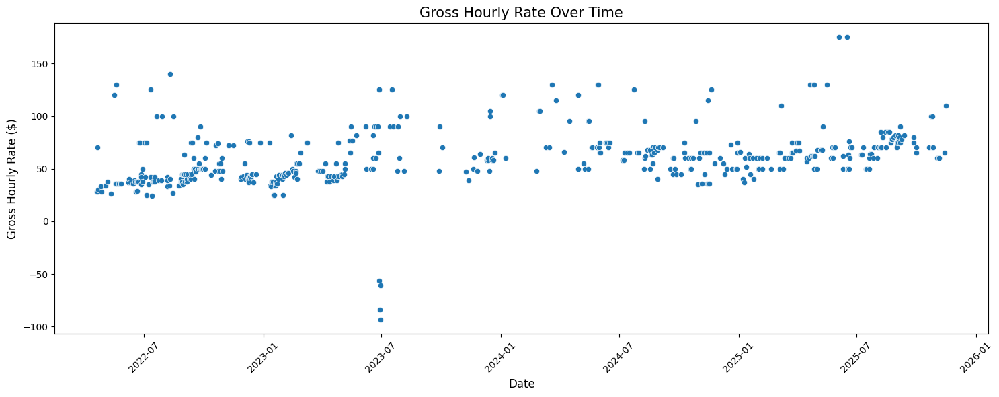

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']

# Create the plot
plt.figure(figsize=(15, 6))
sns.scatterplot(data=df, x='Date', y='Gross_Hourly_Rate')

# Add trend line
sns.regplot(data=df, x=df['Date'].astype(int) / 10**9, y='Gross_Hourly_Rate', 
            scatter=False, color='red')

# Styling
plt.title('Gross Hourly Rate Over Time', fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Gross Hourly Rate ($)', fontsize=12)
plt.xticks(rotation=45)

# Annotate significant points (example)
plt.annotate('Started raising rates', 
             xy=(df['Date'].min(), df['Gross_Hourly_Rate'].min()),
             xytext=(10, 10), textcoords='offset points')

plt.tight_layout()
plt.show()

# Optional: Save the plot
plt.savefig('hourly_rate_trend.png')

In [ ]:
import os

# Create visualizations folder if it doesn't exist
os.makedirs('../visualizations', exist_ok=True)
print("✓ Visualizations folder created")

✓ Visualizations folder created


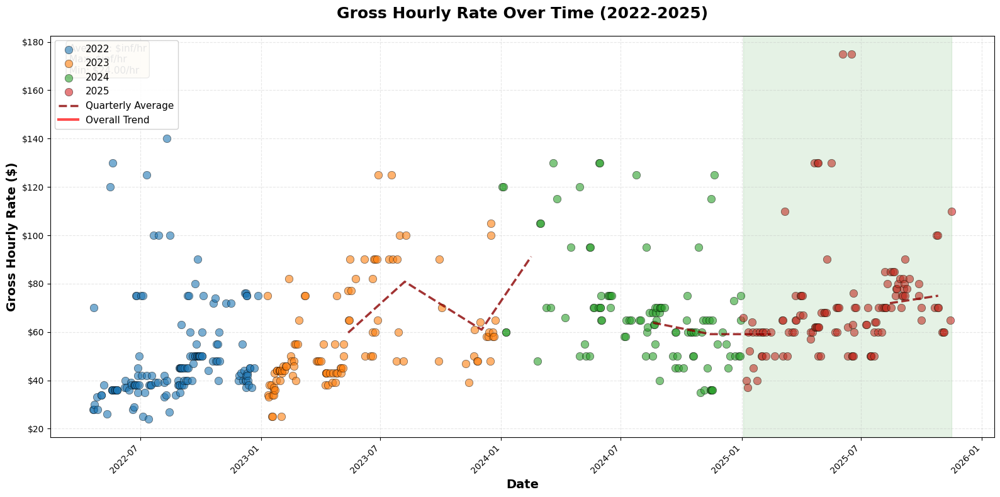

✓ Chart saved to visualizations/hourly_rate_trend_professional.png

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3                inf
    2022-Q4                inf
    2023-Q1                inf
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2                inf
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2                inf
    2025-Q3          71.925000
    2025-Q4          75.000000


<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data - remove outliers (negative rates)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[df['Gross_Hourly_Rate'] > 0].copy()  # Remove negative rates

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Create the plot with better styling
fig, ax = plt.subplots(figsize=(16, 8))

# Color palette for years
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#d62728'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line (smoother)
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
z = np.polyfit(df_clean['Date'].astype(np.int64) / 10**9, 
               df_clean['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)
ax.plot(df_clean['Date'], 
        p(df_clean['Date'].astype(np.int64) / 10**9), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines for better readability
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add statistical annotations
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

# Text box with key stats
textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.02, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight strategic optimization period (2025)
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='green', label='Strategic Optimization Period')

plt.tight_layout()
plt.show()

# Save high-resolution version
plt.savefig('../visualizations/hourly_rate_trend_professional.png', 
            dpi=300, bbox_inches='tight')
print("✓ Chart saved to visualizations/hourly_rate_trend_professional.png")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

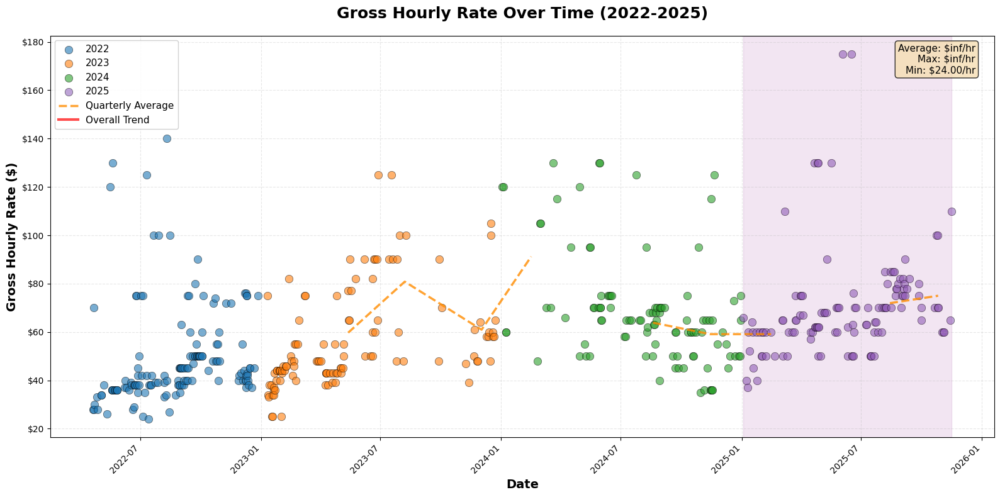

✓ Chart WITH trend line saved


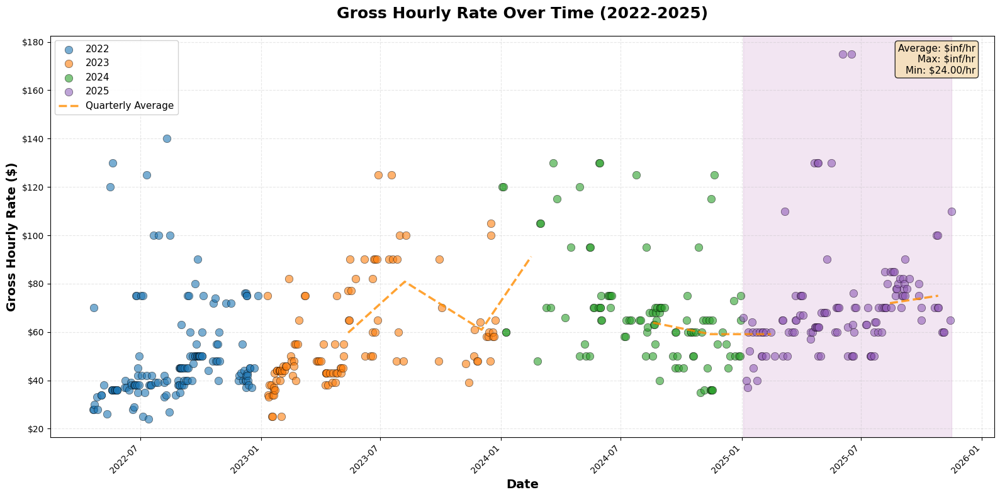

✓ Chart WITHOUT overall trend line saved

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3                inf
    2022-Q4                inf
    2023-Q1                inf
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2                inf
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2                inf
    2025-Q3          71.925000
    2025-Q4          75.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data - remove outliers (negative rates)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[df['Gross_Hourly_Rate'] > 0].copy()  # Remove negative rates

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Color palette for years (changed 2025 to purple)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}  # Purple for 2025
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line (smoother) - changed to orange
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkorange', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line - FIXED to span entire date range
# Convert dates to numeric for regression
x_numeric = (df_clean['Date'] - df_clean['Date'].min()).dt.days
z = np.polyfit(x_numeric, df_clean['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)

# Create smooth line across entire date range
date_range = pd.date_range(df_clean['Date'].min(), df_clean['Date'].max(), periods=100)
x_smooth = (date_range - df_clean['Date'].min()).days
y_trend = p(x_smooth)

ax.plot(date_range, y_trend, 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines for better readability
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add statistical annotations - MOVED TO RIGHT
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.98, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', horizontalalignment='right', bbox=props)

# Highlight strategic optimization period (2025)
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line only (no overall trend)
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkorange', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box on the right
ax.text(0.98, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', horizontalalignment='right', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITHOUT overall trend line saved")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

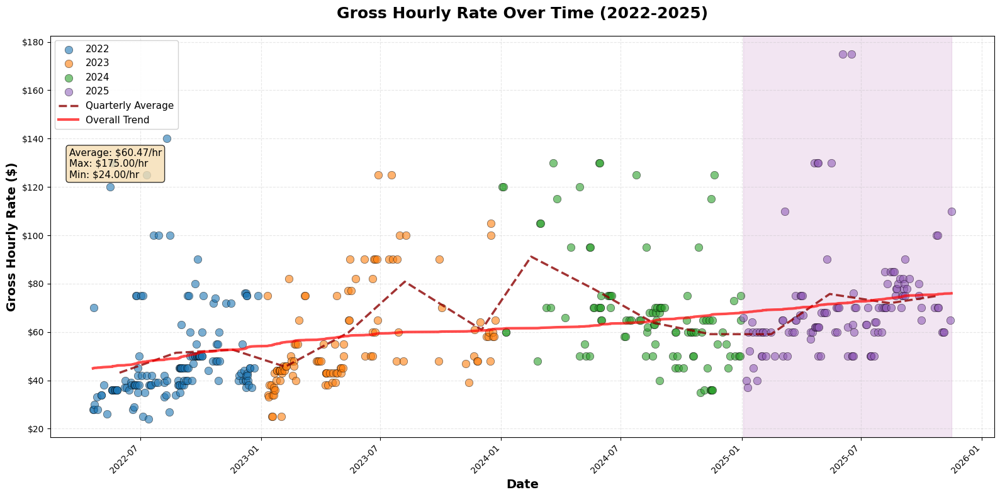

✓ Chart WITH trend line saved


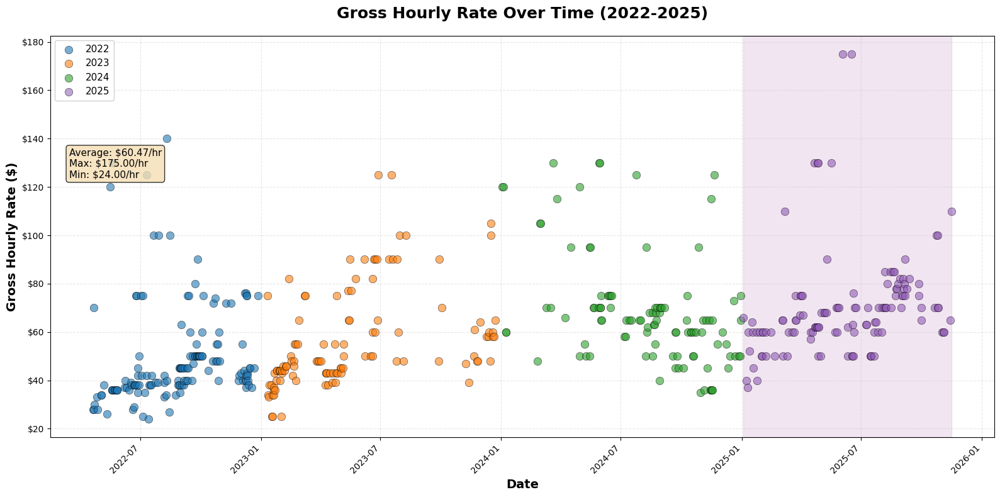

✓ Chart WITHOUT trend lines saved

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3          51.400000
    2022-Q4          52.650000
    2023-Q1          45.627907
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2          77.541667
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2          75.725000
    2025-Q3          71.925000
    2025-Q4          75.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data - remove outliers (negative rates AND infinite values)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()  # Remove negative and infinite

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line - PROPERLY FIXED
# Sort data by date first
df_sorted = df_clean.sort_values('Date')
# Convert dates to numeric for regression
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)

# Plot trend line
ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the left, next to legend but not overlapping
ax.text(0.02, 0.72, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE (NO LINES AT ALL) =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors - DOTS ONLY
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# NO LINES AT ALL - just dots

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box next to legend
ax.text(0.02, 0.72, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

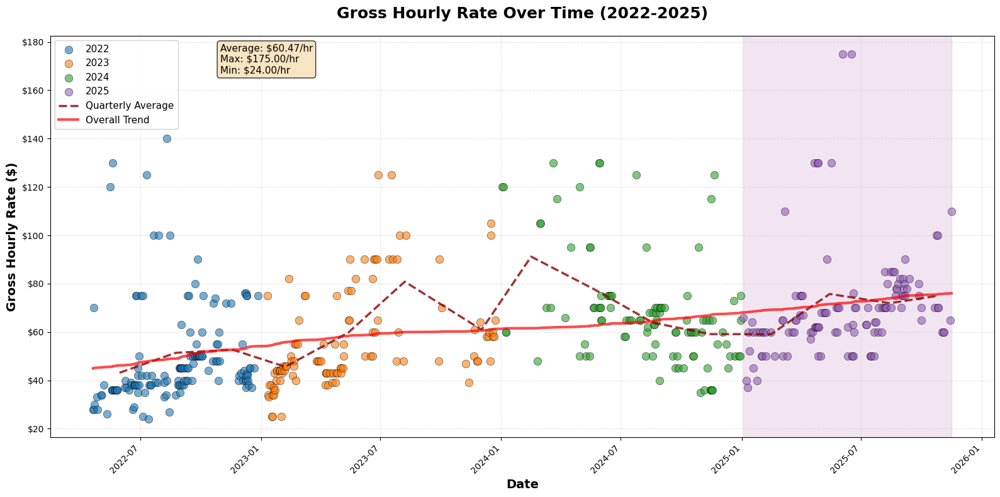

✓ Chart WITH trend line saved


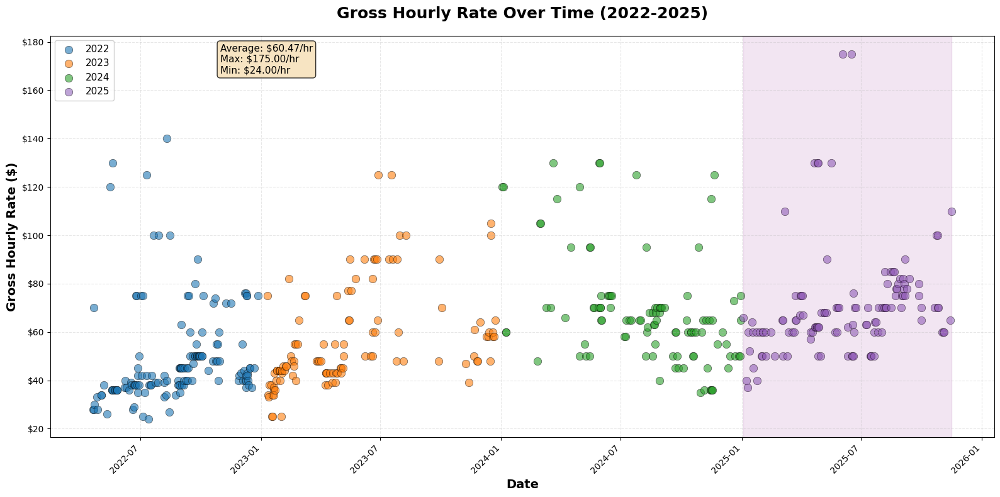

✓ Chart WITHOUT trend lines saved

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3          51.400000
    2022-Q4          52.650000
    2023-Q1          45.627907
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2          77.541667
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2          75.725000
    2025-Q3          71.925000
    2025-Q4          75.000000


In [ ]:
# Prepare data - remove outliers (negative rates AND infinite values)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
df_sorted = df_clean.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend - positioned at 0.18 (just right of legend)
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

In [ ]:
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']

In [ ]:
# Display the quarterly averages that are being plotted
print("Quarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate', 'Date']])

# Let's also manually verify a few quarters
print("\n" + "="*60)
print("Manual Verification - Sample Quarters:")
print("="*60)

for quarter in ['2022-Q2', '2023-Q1', '2024-Q3', '2025-Q1']:
    quarter_data = df_clean[df_clean['YearQuarter'] == quarter]
    if len(quarter_data) > 0:
        manual_avg = quarter_data['Gross_Hourly_Rate'].mean()
        print(f"\n{quarter}:")
        print(f"  Number of jobs: {len(quarter_data)}")
        print(f"  Manual average: ${manual_avg:.2f}/hr")
        print(f"  Quarterly_avg table: ${quarterly_avg[quarterly_avg['YearQuarter']==quarter]['Gross_Hourly_Rate'].values[0]:.2f}/hr")
        print(f"  Match: {np.isclose(manual_avg, quarterly_avg[quarterly_avg['YearQuarter']==quarter]['Gross_Hourly_Rate'].values[0])}")

# Show the actual data points vs the line
print("\n" + "="*60)
print("Does the line match the data pattern?")
print("="*60)
print("\nLook at the chart - does the dashed line go through the 'center' of each quarter's dots?")

Quarterly Average Hourly Rates:
   YearQuarter  Gross_Hourly_Rate                          Date
0      2022-Q2          43.153846 2022-05-30 08:36:55.384615424
1      2022-Q3          51.400000 2022-08-23 23:37:50.769230848
2      2022-Q4          52.650000 2022-11-18 16:48:00.000000000
3      2023-Q1          45.627907 2023-02-06 08:55:48.837209344
4      2023-Q2          59.717949 2023-05-13 04:55:23.076923136
5      2023-Q3          80.818182 2023-08-07 06:32:43.636363520
6      2023-Q4          60.944444 2023-12-02 04:00:00.000000000
7      2024-Q1          91.181818 2024-02-15 13:05:27.272727296
8      2024-Q2          77.541667 2024-05-22 08:00:00.000000000
9      2024-Q3          63.852941 2024-08-18 23:17:38.823529472
10     2024-Q4          59.111111 2024-11-14 02:00:00.000000000
11     2025-Q1          59.093750 2025-02-14 16:30:00.000000000
12     2025-Q2          75.725000 2025-05-14 19:12:00.000000000
13     2025-Q3          71.925000 2025-08-14 09:36:00.000000000
14     2

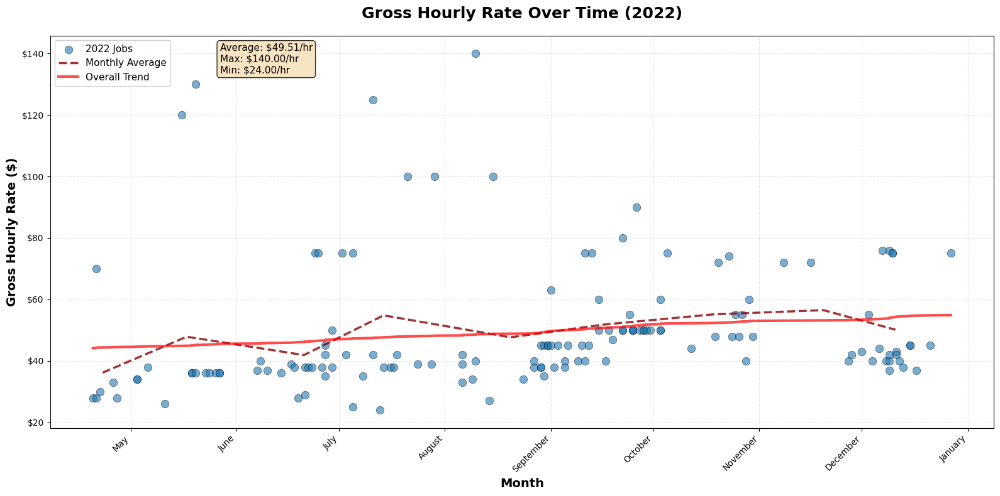

✓ Chart for 2022 saved


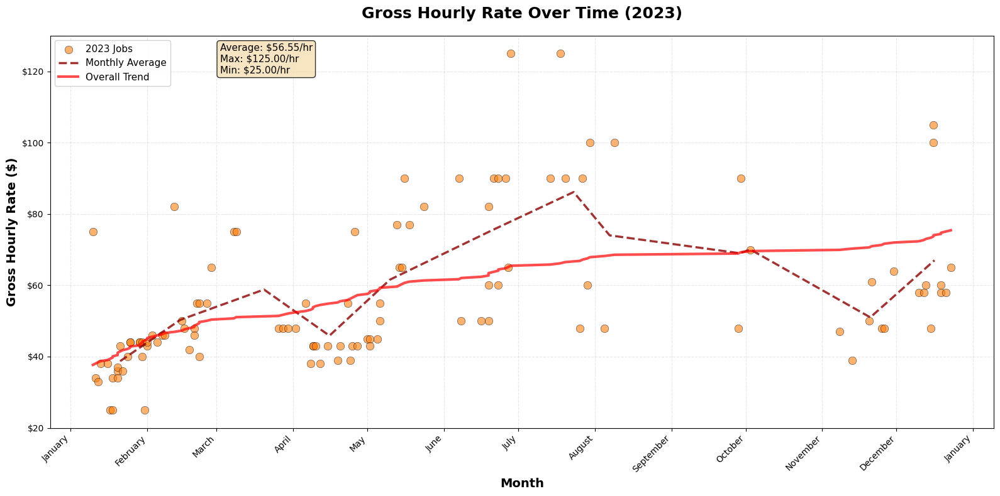

✓ Chart for 2023 saved


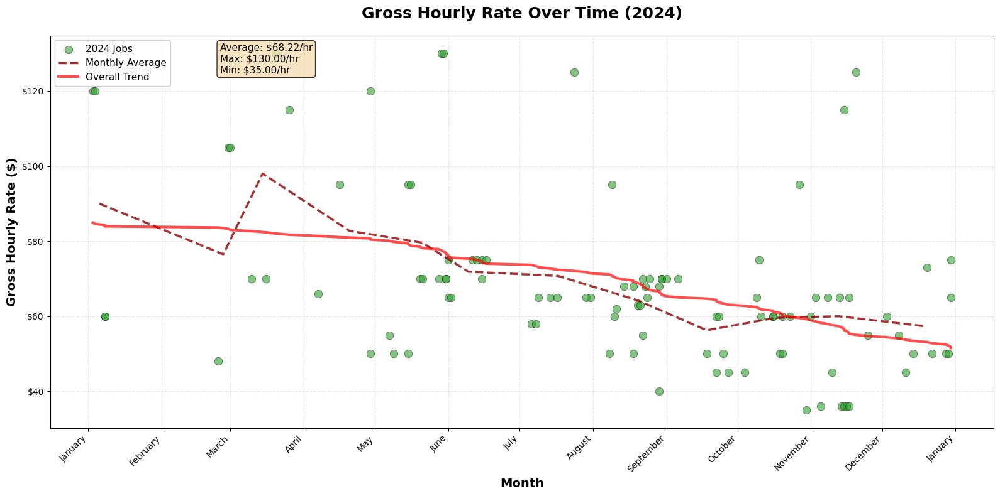

✓ Chart for 2024 saved


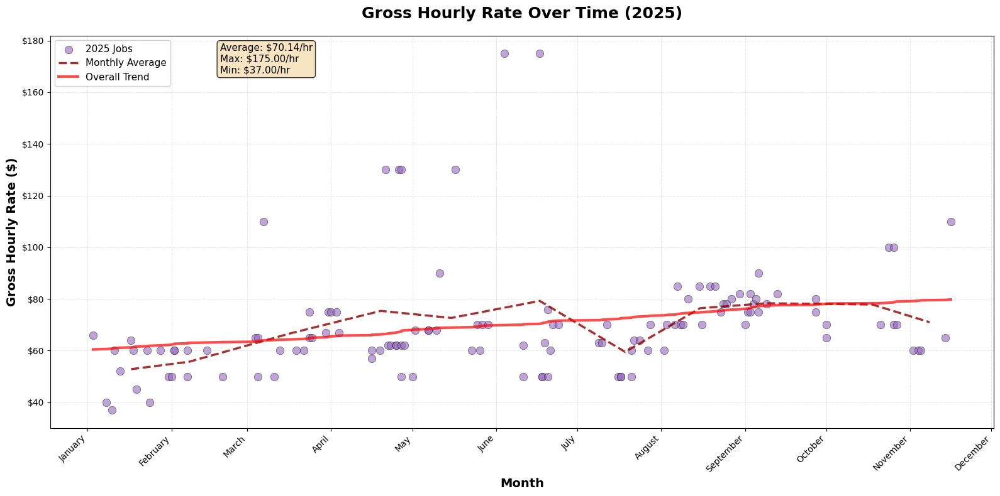

✓ Chart for 2025 saved

✓ All individual year charts created!


In [ ]:
# Prepare data
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Extract year and month
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Month_Name'] = df_clean['Date'].dt.strftime('%B')  # Full month name
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly averages
monthly_avg = df_clean.groupby(['Year', 'Year_Month']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color for each year's dots
year_colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}

# Create individual chart for each year
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    year_monthly = monthly_avg[monthly_avg['Year'] == year]
    
    # Calculate stats for this year
    avg_rate = year_data['Gross_Hourly_Rate'].mean()
    max_rate = year_data['Gross_Hourly_Rate'].max()
    min_rate = year_data['Gross_Hourly_Rate'].min()
    
    textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot dots for this year
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=year_colors[year], s=80, alpha=0.6, 
               edgecolors='black', linewidth=0.5, label=f'{year} Jobs')
    
    # Add monthly average trend line
    ax.plot(year_monthly['Date'], year_monthly['Gross_Hourly_Rate'], 
            color='darkred', linewidth=2.5, label='Monthly Average', 
            linestyle='--', alpha=0.8)
    
    # Overall trend line for the year
    year_sorted = year_data.sort_values('Date')
    x_numeric = np.arange(len(year_sorted))
    z = np.polyfit(x_numeric, year_sorted['Gross_Hourly_Rate'], 1)
    p = np.poly1d(z)
    
    ax.plot(year_sorted['Date'], p(x_numeric), 
            color='red', linewidth=3, label='Overall Trend', alpha=0.7)
    
    # Styling
    ax.set_title(f'Gross Hourly Rate Over Time ({year})', 
                 fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Month', fontsize=14, fontweight='bold')
    ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')
    
    # Format y-axis to show dollars
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
    # Format x-axis to show month names
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%B'))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')
    
    # Add legend
    ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
    
    # Add stats box
    ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.savefig(f'../visualizations/hourly_rate_{year}.png', 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Chart for {year} saved")

print("\n✓ All individual year charts created!")

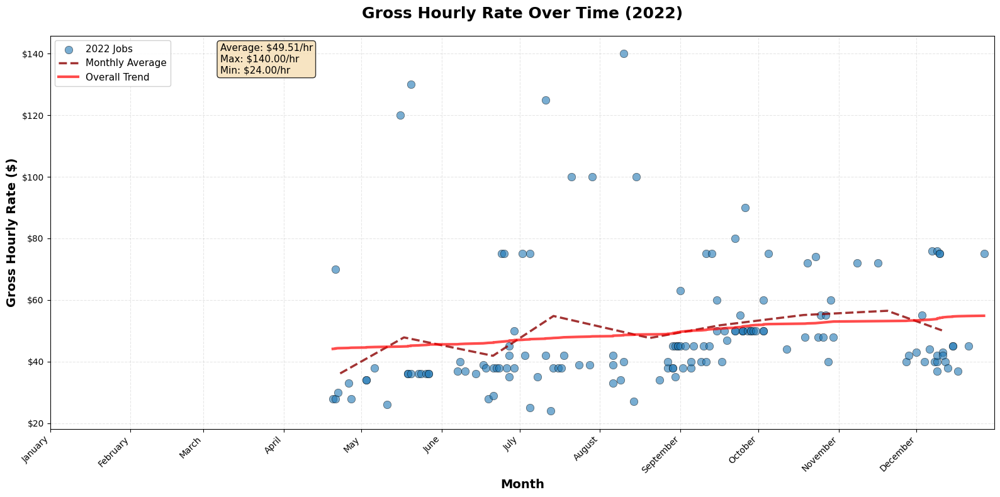

✓ Chart for 2022 saved


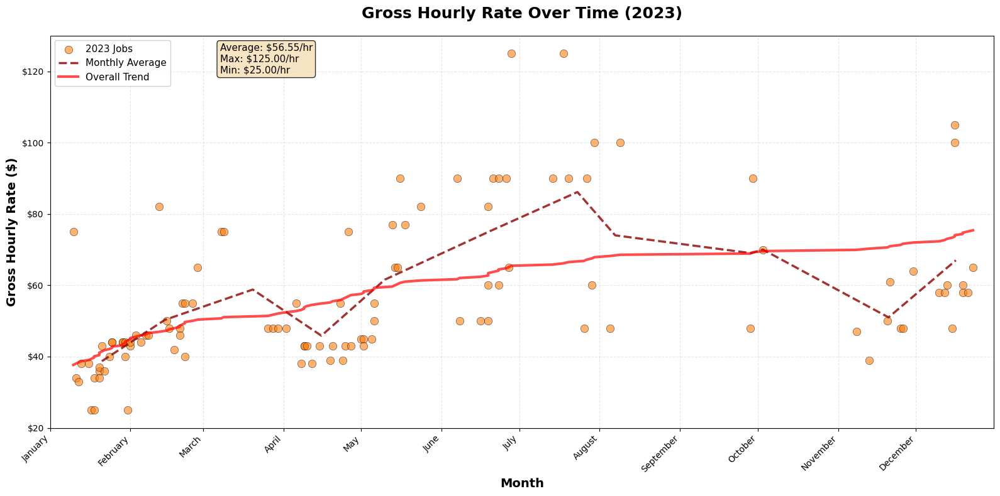

✓ Chart for 2023 saved


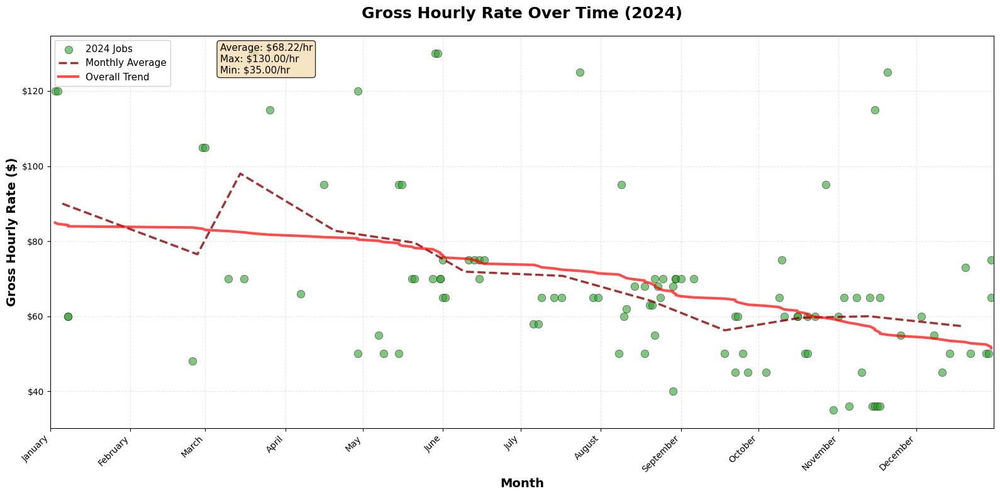

✓ Chart for 2024 saved


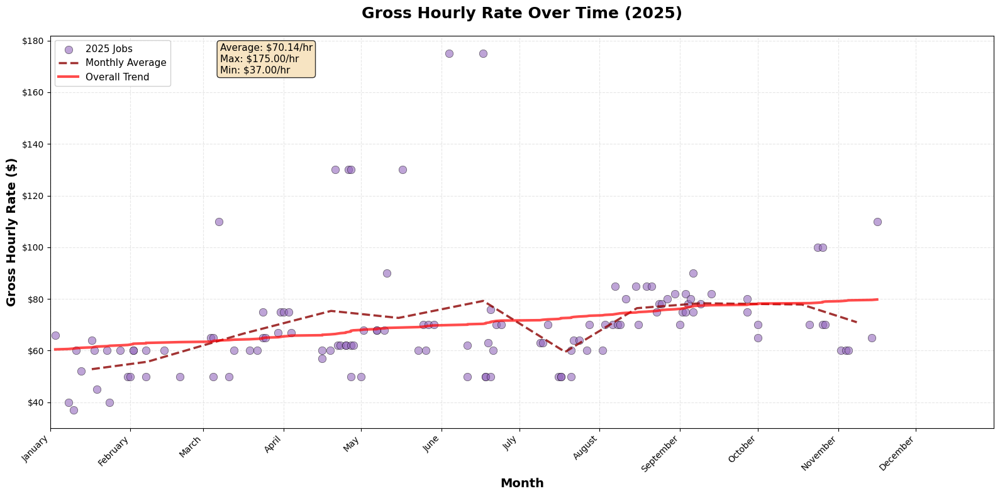

✓ Chart for 2025 saved

✓ All individual year charts created!


In [ ]:
# Prepare data
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Extract year and month
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Month_Name'] = df_clean['Date'].dt.strftime('%B')
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly averages
monthly_avg = df_clean.groupby(['Year', 'Year_Month']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color for each year's dots
year_colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}

# Create individual chart for each year
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    year_monthly = monthly_avg[monthly_avg['Year'] == year]
    
    # Calculate stats for this year
    avg_rate = year_data['Gross_Hourly_Rate'].mean()
    max_rate = year_data['Gross_Hourly_Rate'].max()
    min_rate = year_data['Gross_Hourly_Rate'].min()
    
    textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot dots for this year
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=year_colors[year], s=80, alpha=0.6, 
               edgecolors='black', linewidth=0.5, label=f'{year} Jobs')
    
    # Add monthly average trend line
    ax.plot(year_monthly['Date'], year_monthly['Gross_Hourly_Rate'], 
            color='darkred', linewidth=2.5, label='Monthly Average', 
            linestyle='--', alpha=0.8)
    
    # Overall trend line for the year
    year_sorted = year_data.sort_values('Date')
    x_numeric = np.arange(len(year_sorted))
    z = np.polyfit(x_numeric, year_sorted['Gross_Hourly_Rate'], 1)
    p = np.poly1d(z)
    
    ax.plot(year_sorted['Date'], p(x_numeric), 
            color='red', linewidth=3, label='Overall Trend', alpha=0.7)
    
    # Styling
    ax.set_title(f'Gross Hourly Rate Over Time ({year})', 
                 fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Month', fontsize=14, fontweight='bold')
    ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')
    
    # Format y-axis to show dollars
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
    # Set x-axis limits to exactly the year boundary
    ax.set_xlim(pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year}-12-31'))
    
    # Format x-axis to show month names - one per month
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%B'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')
    
    # Add legend
    ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
    
    # Add stats box
    ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.savefig(f'../visualizations/hourly_rate_{year}.png', 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Chart for {year} saved")

print("\n✓ All individual year charts created!")

[Text(20103.0, 0, 'January'),
 Text(20134.0, 0, 'February'),
 Text(20162.0, 0, 'March'),
 Text(20193.0, 0, 'April'),
 Text(20223.0, 0, 'May'),
 Text(20254.0, 0, 'June'),
 Text(20284.0, 0, 'July'),
 Text(20315.0, 0, 'August'),
 Text(20346.0, 0, 'September'),
 Text(20376.0, 0, 'October'),
 Text(20407.0, 0, 'November'),
 Text(20437.0, 0, 'December')]

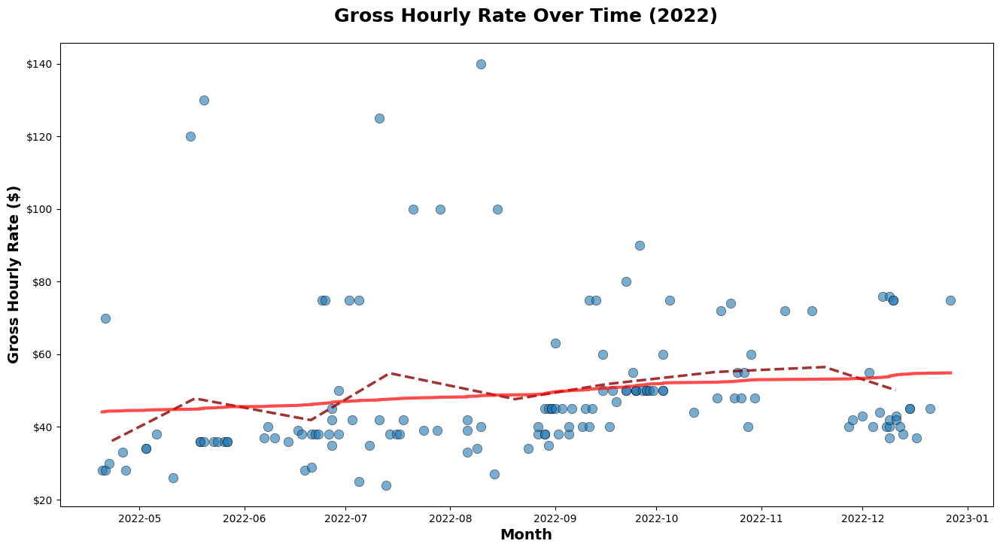

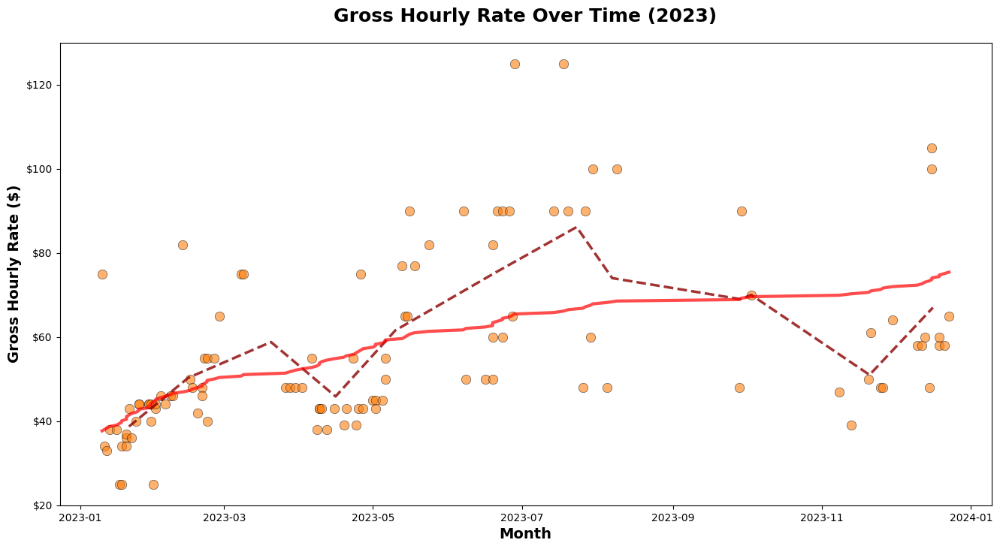

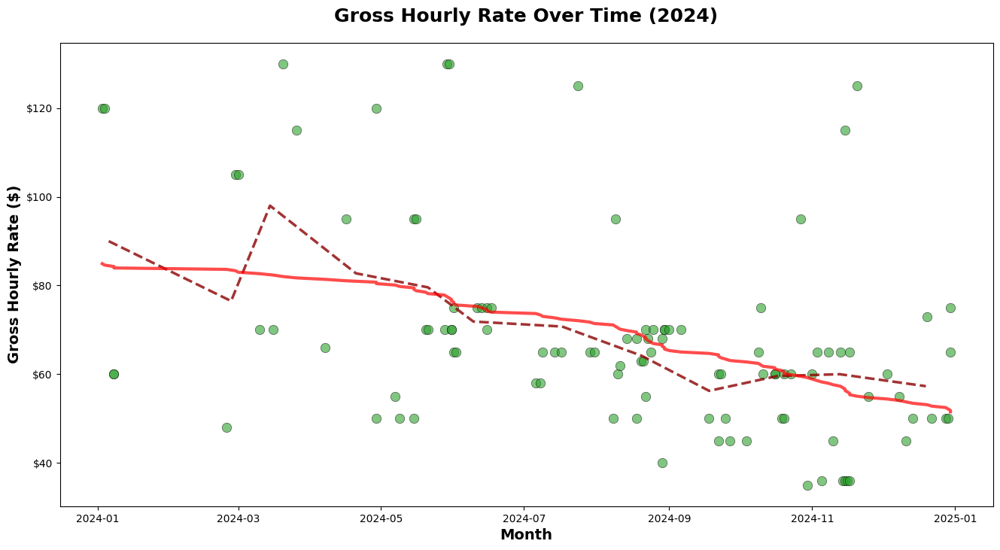

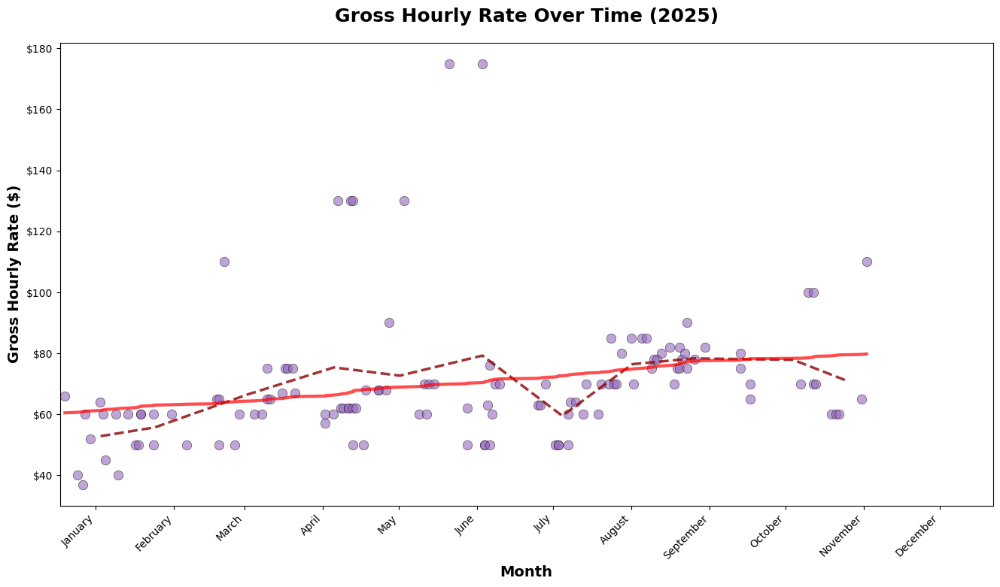

In [ ]:
# Prepare data
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Extract year and month
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Month_Name'] = df_clean['Date'].dt.strftime('%B')
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly averages
monthly_avg = df_clean.groupby(['Year', 'Year_Month']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color for each year's dots
year_colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}

# Create individual chart for each year
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    year_monthly = monthly_avg[monthly_avg['Year'] == year]
    
    # Calculate stats for this year
    avg_rate = year_data['Gross_Hourly_Rate'].mean()
    max_rate = year_data['Gross_Hourly_Rate'].max()
    min_rate = year_data['Gross_Hourly_Rate'].min()
    
    textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot dots for this year
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=year_colors[year], s=80, alpha=0.6, 
               edgecolors='black', linewidth=0.5, label=f'{year} Jobs')
    
    # Add monthly average trend line
    ax.plot(year_monthly['Date'], year_monthly['Gross_Hourly_Rate'], 
            color='darkred', linewidth=2.5, label='Monthly Average', 
            linestyle='--', alpha=0.8)
    
    # Overall trend line for the year
    year_sorted = year_data.sort_values('Date')
    x_numeric = np.arange(len(year_sorted))
    z = np.polyfit(x_numeric, year_sorted['Gross_Hourly_Rate'], 1)
    p = np.poly1d(z)
    
    ax.plot(year_sorted['Date'], p(x_numeric), 
            color='red', linewidth=3, label='Overall Trend', alpha=0.7)
    
    # Styling
    ax.set_title(f'Gross Hourly Rate Over Time ({year})', 
                 fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Month', fontsize=14, fontweight='bold')
    ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')
    
    # Format y-axis to show dollars
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
   # Set x-axis limits with padding - extend slightly past year end
ax.set_xlim(pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year+1}-01-05'))

# Manually set the month labels
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

# Create tick positions at the 15th of each month
tick_dates = [pd.Timestamp(f'{year}-{m:02d}-15') for m in range(1, 13)]

ax.set_xticks(tick_dates)
ax.set_xticklabels(month_names, rotation=45, ha='right')

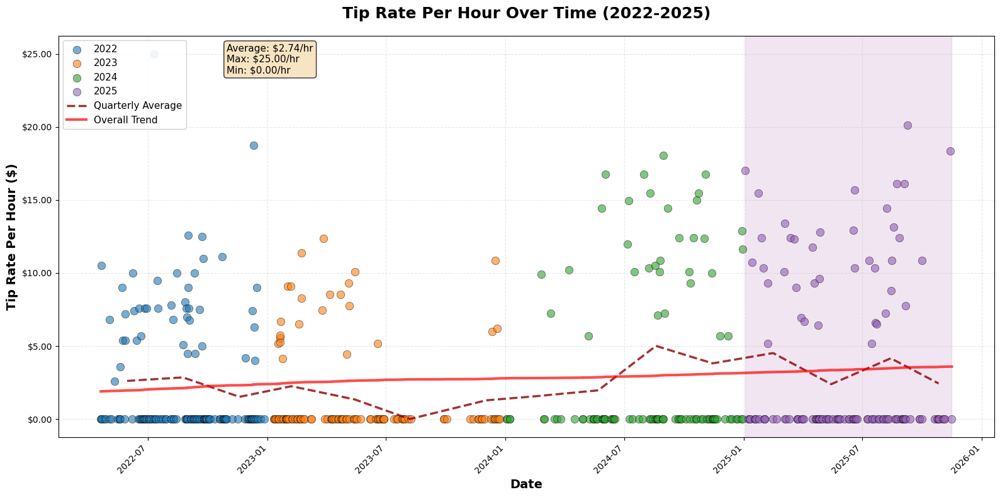

✓ Tip chart WITH trend line saved


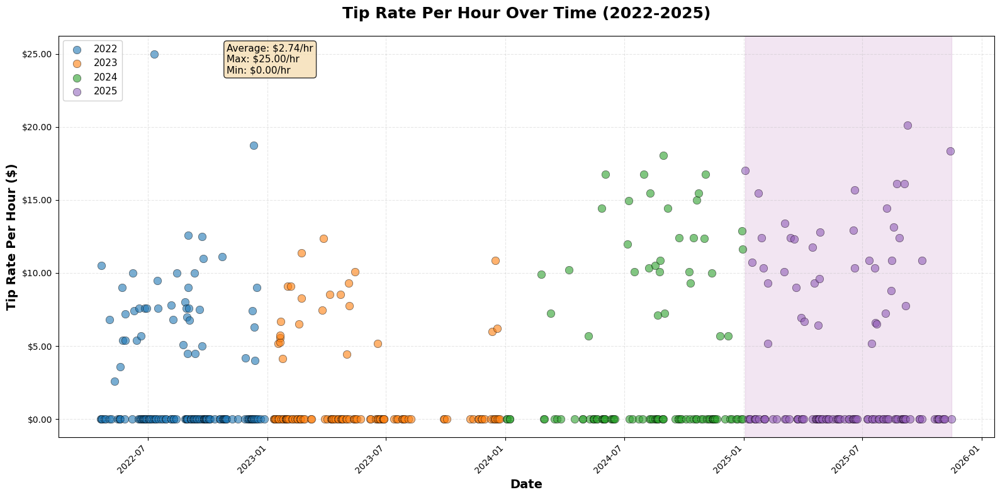

✓ Tip chart WITHOUT trend lines saved

Quarterly Average Tip Rates:
YearQuarter  Tip_Hourly_Rate
    2022-Q2         2.610291
    2022-Q3         2.851562
    2022-Q4         1.518750
    2023-Q1         2.247359
    2023-Q2         1.343834
    2023-Q3         0.000000
    2023-Q4         1.279087
    2024-Q1         1.558235
    2024-Q2         1.963638
    2024-Q3         5.008455
    2024-Q4         3.813287
    2025-Q1         4.517439
    2025-Q2         2.386478
    2025-Q3         4.159985
    2025-Q4         2.433519


In [ ]:
# Prepare data - Tips per hour
df['Tip_Hourly_Rate'] = df['Tip'] / df['Hours']
df_tip_clean = df[(df['Tip_Hourly_Rate'] >= 0) & (df['Tip_Hourly_Rate'] < np.inf)].copy()

# Extract year and quarter
df_tip_clean['Year'] = df_tip_clean['Date'].dt.year
df_tip_clean['Quarter'] = df_tip_clean['Date'].dt.to_period('Q').astype(str)
df_tip_clean['YearQuarter'] = df_tip_clean['Year'].astype(str) + '-Q' + df_tip_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for tips
quarterly_tip_avg = df_tip_clean.groupby('YearQuarter').agg({
    'Tip_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats
avg_tip_rate = df_tip_clean['Tip_Hourly_Rate'].mean()
max_tip_rate = df_tip_clean['Tip_Hourly_Rate'].max()
min_tip_rate = df_tip_clean['Tip_Hourly_Rate'].min()

textstr = f'Average: ${avg_tip_rate:.2f}/hr\nMax: ${max_tip_rate:.2f}/hr\nMin: ${min_tip_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_tip_avg['Date'], quarterly_tip_avg['Tip_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
df_sorted = df_tip_clean.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Tip_Hourly_Rate'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Tip Rates:")
print(quarterly_tip_avg[['YearQuarter', 'Tip_Hourly_Rate']].to_string(index=False))

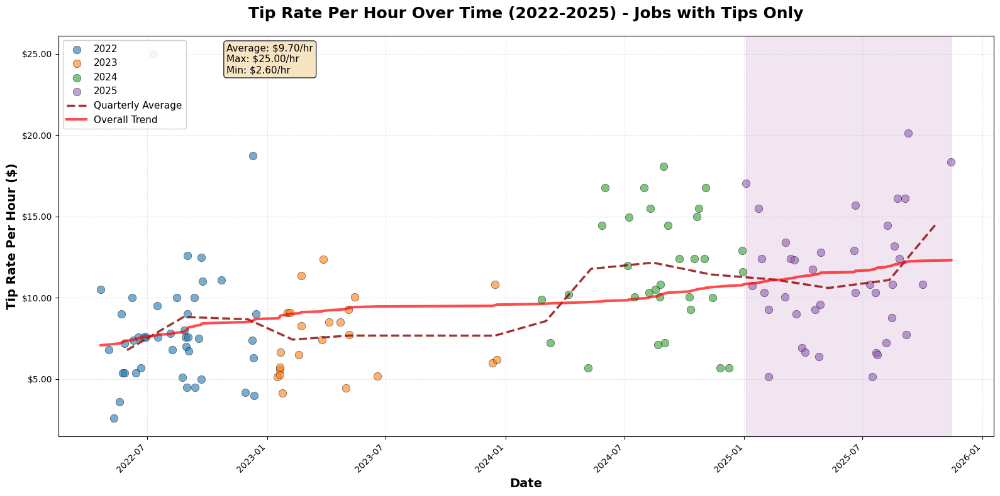

✓ Tip chart WITH trend line saved
Note: Excluded 360 jobs with zero tips


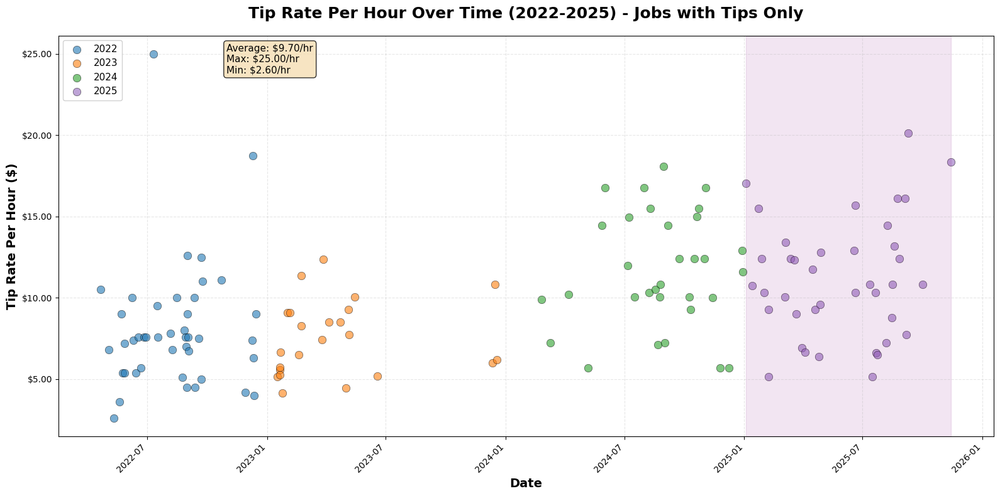

✓ Tip chart WITHOUT trend lines saved

Quarterly Average Tip Rates (Jobs with Tips Only):
YearQuarter  Tip_Hourly_Rate
    2022-Q2         6.786756
    2022-Q3         8.826264
    2022-Q4         8.678571
    2023-Q1         7.433573
    2023-Q2         7.679052
    2023-Q4         7.674524
    2024-Q1         8.570294
    2024-Q2        11.781827
    2024-Q3        12.163390
    2024-Q4        11.439861
    2025-Q1        11.119849
    2025-Q2        10.606569
    2025-Q3        11.093294
    2025-Q4        14.601111


In [ ]:
# Prepare data - Tips per hour (EXCLUDE ZERO TIPS)
df['Tip_Hourly_Rate'] = df['Tip'] / df['Hours']
df_tip_clean = df[(df['Tip_Hourly_Rate'] > 0) & (df['Tip_Hourly_Rate'] < np.inf)].copy()  # Changed >= to >

# Extract year and quarter
df_tip_clean['Year'] = df_tip_clean['Date'].dt.year
df_tip_clean['Quarter'] = df_tip_clean['Date'].dt.to_period('Q').astype(str)
df_tip_clean['YearQuarter'] = df_tip_clean['Year'].astype(str) + '-Q' + df_tip_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for tips
quarterly_tip_avg = df_tip_clean.groupby('YearQuarter').agg({
    'Tip_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats (ONLY non-zero tips)
avg_tip_rate = df_tip_clean['Tip_Hourly_Rate'].mean()
max_tip_rate = df_tip_clean['Tip_Hourly_Rate'].max()
min_tip_rate = df_tip_clean['Tip_Hourly_Rate'].min()

textstr = f'Average: ${avg_tip_rate:.2f}/hr\nMax: ${max_tip_rate:.2f}/hr\nMin: ${min_tip_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_tip_avg['Date'], quarterly_tip_avg['Tip_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line (RECALCULATED without zeros)
df_sorted = df_tip_clean.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Tip_Hourly_Rate'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITH trend line saved")
print(f"Note: Excluded {len(df[df['Tip'] == 0])} jobs with zero tips")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Tip Rates (Jobs with Tips Only):")
print(quarterly_tip_avg[['YearQuarter', 'Tip_Hourly_Rate']].to_string(index=False))

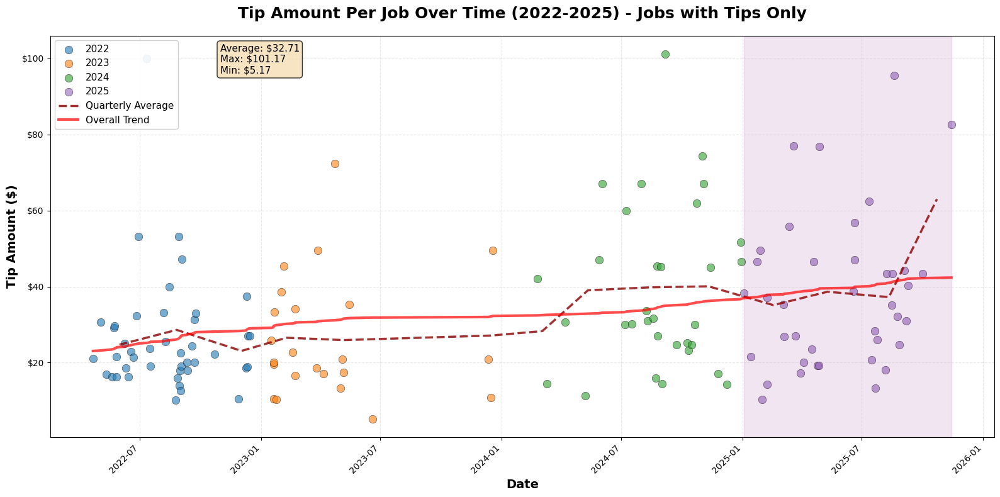

✓ Tip amount per job chart WITH trend line saved
Note: 137 jobs included (excluded 360 jobs with zero tips)


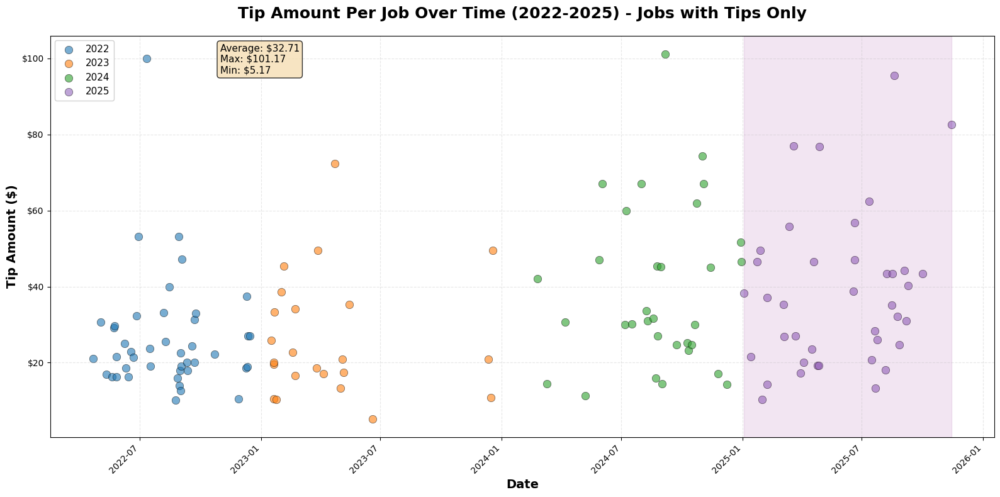

✓ Tip amount per job chart WITHOUT trend lines saved

Quarterly Average Tip Amounts Per Job (Jobs with Tips Only):
YearQuarter       Tip
    2022-Q2 24.722000
    2022-Q3 28.608571
    2022-Q4 23.085714
    2023-Q1 26.543077
    2023-Q2 25.928571
    2023-Q4 27.120000
    2024-Q1 28.290000
    2024-Q2 39.022500
    2024-Q3 39.801429
    2024-Q4 40.072500
    2025-Q1 35.128462
    2025-Q2 38.645556
    2025-Q3 37.234667
    2025-Q4 62.995000


In [ ]:
# Prepare data - Tip amount per job (EXCLUDE ZERO TIPS)
df_tip_job = df[df['Tip'] > 0].copy()

# Extract year and quarter
df_tip_job['Year'] = df_tip_job['Date'].dt.year
df_tip_job['Quarter'] = df_tip_job['Date'].dt.to_period('Q').astype(str)
df_tip_job['YearQuarter'] = df_tip_job['Year'].astype(str) + '-Q' + df_tip_job['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for tip amounts
quarterly_tip_job_avg = df_tip_job.groupby('YearQuarter').agg({
    'Tip': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats (ONLY non-zero tips)
avg_tip = df_tip_job['Tip'].mean()
max_tip = df_tip_job['Tip'].max()
min_tip = df_tip_job['Tip'].min()

textstr = f'Average: ${avg_tip:.2f}\nMax: ${max_tip:.2f}\nMin: ${min_tip:.2f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_job['Year'].unique()):
    year_data = df_tip_job[df_tip_job['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_tip_job_avg['Date'], quarterly_tip_job_avg['Tip'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
df_sorted = df_tip_job.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Tip'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Tip Amount Per Job Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_job['Year'].values:
    ax.axvspan(df_tip_job[df_tip_job['Year'] == 2025]['Date'].min(), 
               df_tip_job[df_tip_job['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_amount_per_job_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip amount per job chart WITH trend line saved")
print(f"Note: {len(df_tip_job)} jobs included (excluded {len(df[df['Tip'] == 0])} jobs with zero tips)")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_job['Year'].unique()):
    year_data = df_tip_job[df_tip_job['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Tip Amount Per Job Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_job['Year'].values:
    ax.axvspan(df_tip_job[df_tip_job['Year'] == 2025]['Date'].min(), 
               df_tip_job[df_tip_job['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_amount_per_job_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip amount per job chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Tip Amounts Per Job (Jobs with Tips Only):")
print(quarterly_tip_job_avg[['YearQuarter', 'Tip']].to_string(index=False))

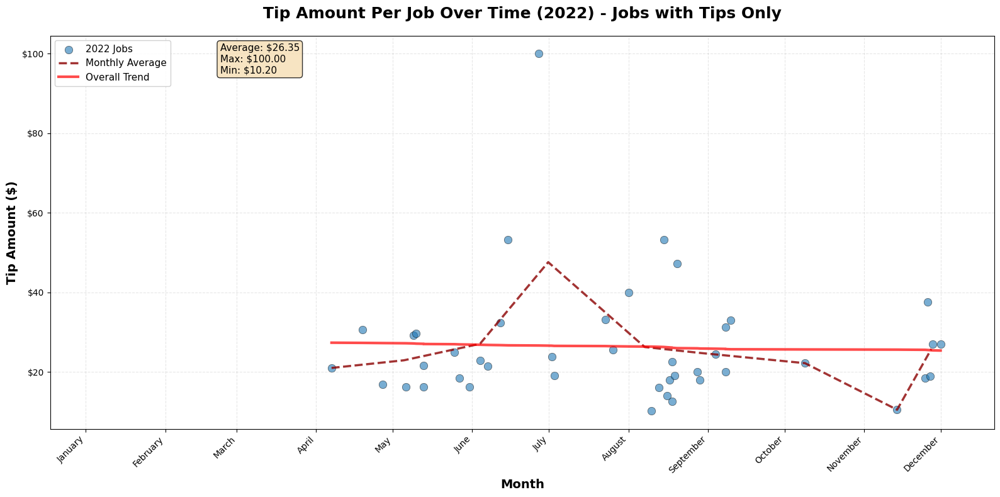

✓ Tip amount chart for 2022 saved


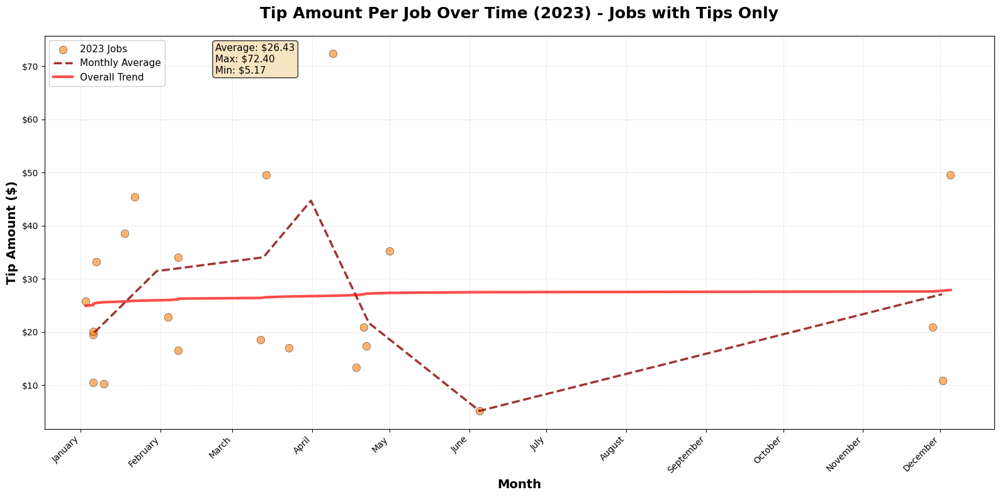

✓ Tip amount chart for 2023 saved


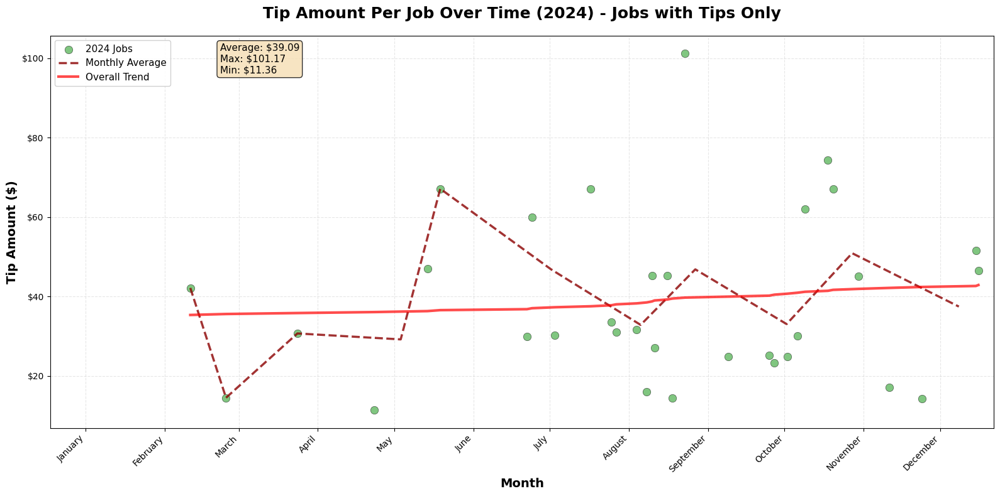

✓ Tip amount chart for 2024 saved


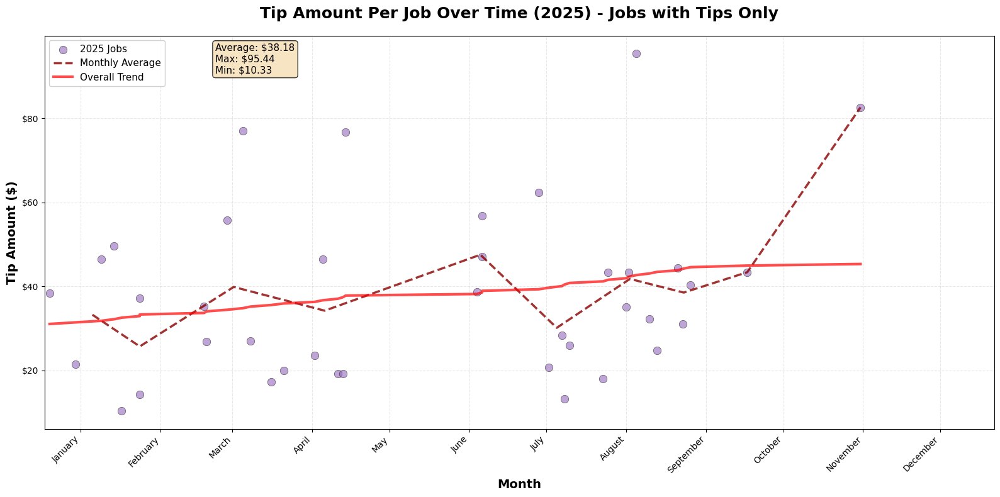

✓ Tip amount chart for 2025 saved

✓ All individual year tip amount charts created!


In [ ]:
# Prepare data - Tip amount per job (EXCLUDE ZERO TIPS)
df_tip_job = df[df['Tip'] > 0].copy()

# Extract year and month
df_tip_job['Year'] = df_tip_job['Date'].dt.year
df_tip_job['Month'] = df_tip_job['Date'].dt.month
df_tip_job['Month_Name'] = df_tip_job['Date'].dt.strftime('%B')
df_tip_job['Year_Month'] = df_tip_job['Date'].dt.to_period('M')

# Calculate monthly averages
monthly_tip_avg = df_tip_job.groupby(['Year', 'Year_Month']).agg({
    'Tip': 'mean',
    'Date': 'mean'
}).reset_index()

# Color for each year's dots
year_colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}

# Create individual chart for each year
for year in sorted(df_tip_job['Year'].unique()):
    year_data = df_tip_job[df_tip_job['Year'] == year]
    year_monthly = monthly_tip_avg[monthly_tip_avg['Year'] == year]
    
    # Calculate stats for this year
    avg_tip = year_data['Tip'].mean()
    max_tip = year_data['Tip'].max()
    min_tip = year_data['Tip'].min()
    
    textstr = f'Average: ${avg_tip:.2f}\nMax: ${max_tip:.2f}\nMin: ${min_tip:.2f}'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot dots for this year
    ax.scatter(year_data['Date'], year_data['Tip'], 
               c=year_colors[year], s=80, alpha=0.6, 
               edgecolors='black', linewidth=0.5, label=f'{year} Jobs')
    
    # Add monthly average trend line
    ax.plot(year_monthly['Date'], year_monthly['Tip'], 
            color='darkred', linewidth=2.5, label='Monthly Average', 
            linestyle='--', alpha=0.8)
    
    # Overall trend line for the year
    year_sorted = year_data.sort_values('Date')
    x_numeric = np.arange(len(year_sorted))
    z = np.polyfit(x_numeric, year_sorted['Tip'], 1)
    p = np.poly1d(z)
    
    ax.plot(year_sorted['Date'], p(x_numeric), 
            color='red', linewidth=3, label='Overall Trend', alpha=0.7)
    
    # Styling
    ax.set_title(f'Tip Amount Per Job Over Time ({year}) - Jobs with Tips Only', 
                 fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Month', fontsize=14, fontweight='bold')
    ax.set_ylabel('Tip Amount ($)', fontsize=14, fontweight='bold')
    
    # Format y-axis to show dollars
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
    # Set x-axis limits with padding
    start_date = pd.Timestamp(f'{year}-01-01')
    end_date = pd.Timestamp(f'{year+1}-01-05')
    ax.set_xlim(start_date, end_date)
    
    # Manually set the month labels
    month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
                   'July', 'August', 'September', 'October', 'November', 'December']
    
    # Create tick positions at the 15th of each month
    tick_dates = [pd.Timestamp(f'{year}-{m:02d}-15') for m in range(1, 13)]
    
    ax.set_xticks(tick_dates)
    ax.set_xticklabels(month_names, rotation=45, ha='right')
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Add legend
    ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
    
    # Add stats box
    ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.savefig(f'../visualizations/tip_amount_per_job_{year}.png', 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Tip amount chart for {year} saved")

print("\n✓ All individual year tip amount charts created!")

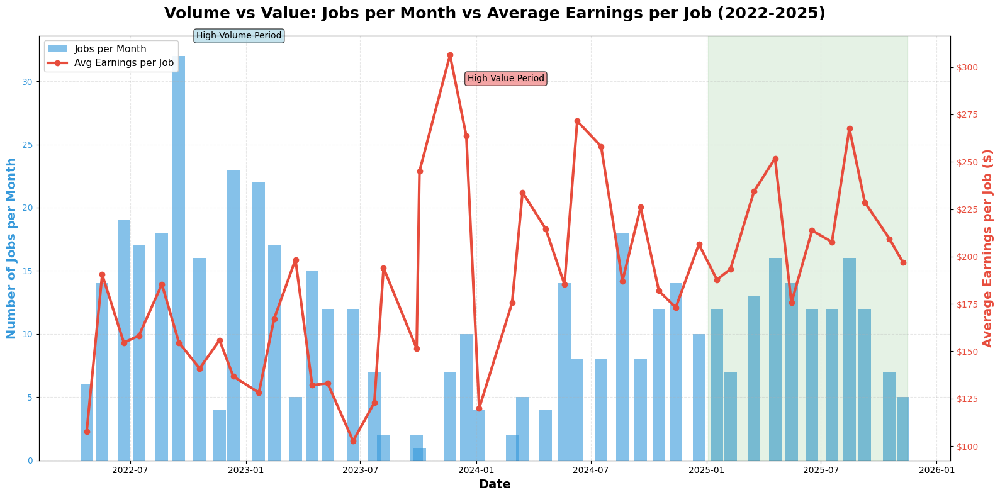

✓ Volume vs Value chart saved

VOLUME VS VALUE SUMMARY
Highest volume month: 2022-09 - 32 jobs
Highest value month: 2023-11 - $306.36 per job

Total trend:
  Early period avg jobs/month: 17.7
  Recent period avg jobs/month: 10.7
  Early period avg earnings/job: $158.53
  Recent period avg earnings/job: $220.70


In [ ]:
# Prepare data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly metrics
monthly_metrics = df_clean.groupby('Year_Month').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',      # Average earnings per job
    'Date': 'mean'        # For plotting
}).reset_index()

monthly_metrics.columns = ['Year_Month', 'Jobs_Count', 'Avg_Earnings_Per_Job', 'Date']

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
bar_color = '#3498db'  # Blue for volume
line_color = '#e74c3c'  # Red for value

# Plot bars - Jobs per month (left y-axis)
ax1.bar(monthly_metrics['Date'], monthly_metrics['Jobs_Count'], 
        color=bar_color, alpha=0.6, width=20, label='Jobs per Month')

ax1.set_xlabel('Date', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Jobs per Month', fontsize=14, fontweight='bold', color=bar_color)
ax1.tick_params(axis='y', labelcolor=bar_color)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(monthly_metrics['Date'], monthly_metrics['Avg_Earnings_Per_Job'], 
         color=line_color, linewidth=3, marker='o', markersize=6, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=line_color)
ax2.tick_params(axis='y', labelcolor=line_color)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Volume vs Value: Jobs per Month vs Average Earnings per Job (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight strategic shift period (2025)
if 2025 in df_clean['Year'].values:
    shift_start = df_clean[df_clean['Year'] == 2025]['Date'].min()
    shift_end = df_clean[df_clean['Year'] == 2025]['Date'].max()
    ax1.axvspan(shift_start, shift_end, alpha=0.1, color='green', label='Strategic Optimization')

# Add annotation showing the shift
max_volume_month = monthly_metrics.loc[monthly_metrics['Jobs_Count'].idxmax()]
max_value_month = monthly_metrics.loc[monthly_metrics['Avg_Earnings_Per_Job'].idxmax()]

ax1.annotate('High Volume Period', 
             xy=(max_volume_month['Date'], max_volume_month['Jobs_Count']),
             xytext=(20, 20), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
             fontsize=10, ha='left')

ax2.annotate('High Value Period', 
             xy=(max_value_month['Date'], max_value_month['Avg_Earnings_Per_Job']),
             xytext=(20, -30), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.7),
             fontsize=10, ha='left')

plt.tight_layout()
plt.savefig('../visualizations/volume_vs_value.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Volume vs Value chart saved")

# Print summary stats
print("\n" + "="*60)
print("VOLUME VS VALUE SUMMARY")
print("="*60)
print(f"Highest volume month: {max_volume_month['Year_Month']} - {int(max_volume_month['Jobs_Count'])} jobs")
print(f"Highest value month: {max_value_month['Year_Month']} - ${max_value_month['Avg_Earnings_Per_Job']:.2f} per job")
print(f"\nTotal trend:")
print(f"  Early period avg jobs/month: {monthly_metrics.head(6)['Jobs_Count'].mean():.1f}")
print(f"  Recent period avg jobs/month: {monthly_metrics.tail(6)['Jobs_Count'].mean():.1f}")
print(f"  Early period avg earnings/job: ${monthly_metrics.head(6)['Avg_Earnings_Per_Job'].mean():.2f}")
print(f"  Recent period avg earnings/job: ${monthly_metrics.tail(6)['Avg_Earnings_Per_Job'].mean():.2f}")

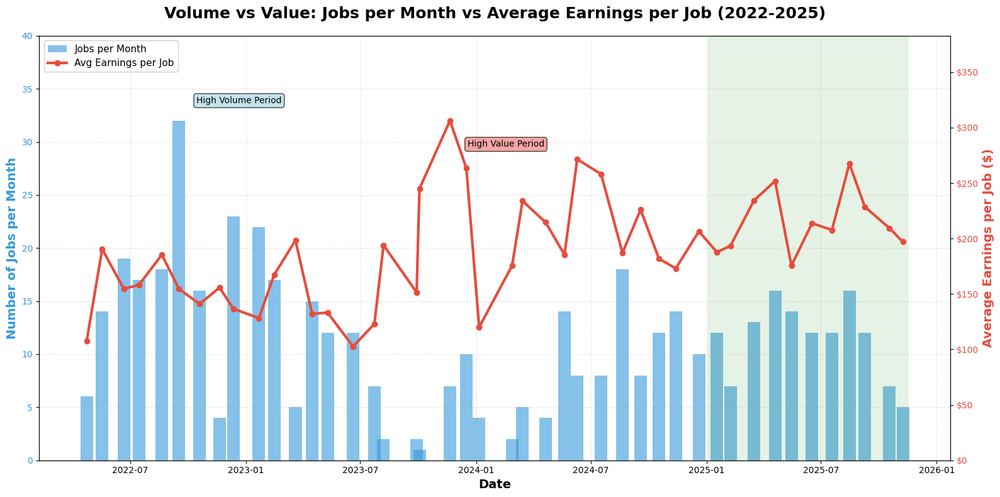

✓ Volume vs Value chart saved

VOLUME VS VALUE SUMMARY
Highest volume month: 2022-09 - 32 jobs
Highest value month: 2023-11 - $306.36 per job

Total trend:
  Early period avg jobs/month: 17.7
  Recent period avg jobs/month: 10.7
  Early period avg earnings/job: $158.53
  Recent period avg earnings/job: $220.70


In [ ]:
# Prepare data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly metrics
monthly_metrics = df_clean.groupby('Year_Month').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',      # Average earnings per job
    'Date': 'mean'        # For plotting
}).reset_index()

monthly_metrics.columns = ['Year_Month', 'Jobs_Count', 'Avg_Earnings_Per_Job', 'Date']

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
bar_color = '#3498db'  # Blue for volume
line_color = '#e74c3c'  # Red for value

# Plot bars - Jobs per month (left y-axis)
ax1.bar(monthly_metrics['Date'], monthly_metrics['Jobs_Count'], 
        color=bar_color, alpha=0.6, width=20, label='Jobs per Month')

ax1.set_xlabel('Date', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Jobs per Month', fontsize=14, fontweight='bold', color=bar_color)
ax1.tick_params(axis='y', labelcolor=bar_color)

# Add extra space at the top of left y-axis
ax1.set_ylim(0, monthly_metrics['Jobs_Count'].max() * 1.25)  # 25% extra space

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(monthly_metrics['Date'], monthly_metrics['Avg_Earnings_Per_Job'], 
         color=line_color, linewidth=3, marker='o', markersize=6, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=line_color)
ax2.tick_params(axis='y', labelcolor=line_color)

# Add extra space at the top of right y-axis
ax2.set_ylim(0, monthly_metrics['Avg_Earnings_Per_Job'].max() * 1.25)  # 25% extra space

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Volume vs Value: Jobs per Month vs Average Earnings per Job (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight strategic shift period (2025)
if 2025 in df_clean['Year'].values:
    shift_start = df_clean[df_clean['Year'] == 2025]['Date'].min()
    shift_end = df_clean[df_clean['Year'] == 2025]['Date'].max()
    ax1.axvspan(shift_start, shift_end, alpha=0.1, color='green', label='Strategic Optimization')

# Add annotation showing the shift
max_volume_month = monthly_metrics.loc[monthly_metrics['Jobs_Count'].idxmax()]
max_value_month = monthly_metrics.loc[monthly_metrics['Avg_Earnings_Per_Job'].idxmax()]

ax1.annotate('High Volume Period', 
             xy=(max_volume_month['Date'], max_volume_month['Jobs_Count']),
             xytext=(20, 20), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
             fontsize=10, ha='left')

ax2.annotate('High Value Period', 
             xy=(max_value_month['Date'], max_value_month['Avg_Earnings_Per_Job']),
             xytext=(20, -30), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.7),
             fontsize=10, ha='left')

plt.tight_layout()
plt.savefig('../visualizations/volume_vs_value.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Volume vs Value chart saved")

# Print summary stats
print("\n" + "="*60)
print("VOLUME VS VALUE SUMMARY")
print("="*60)
print(f"Highest volume month: {max_volume_month['Year_Month']} - {int(max_volume_month['Jobs_Count'])} jobs")
print(f"Highest value month: {max_value_month['Year_Month']} - ${max_value_month['Avg_Earnings_Per_Job']:.2f} per job")
print(f"\nTotal trend:")
print(f"  Early period avg jobs/month: {monthly_metrics.head(6)['Jobs_Count'].mean():.1f}")
print(f"  Recent period avg jobs/month: {monthly_metrics.tail(6)['Jobs_Count'].mean():.1f}")
print(f"  Early period avg earnings/job: ${monthly_metrics.head(6)['Avg_Earnings_Per_Job'].mean():.2f}")
print(f"  Recent period avg earnings/job: ${monthly_metrics.tail(6)['Avg_Earnings_Per_Job'].mean():.2f}")

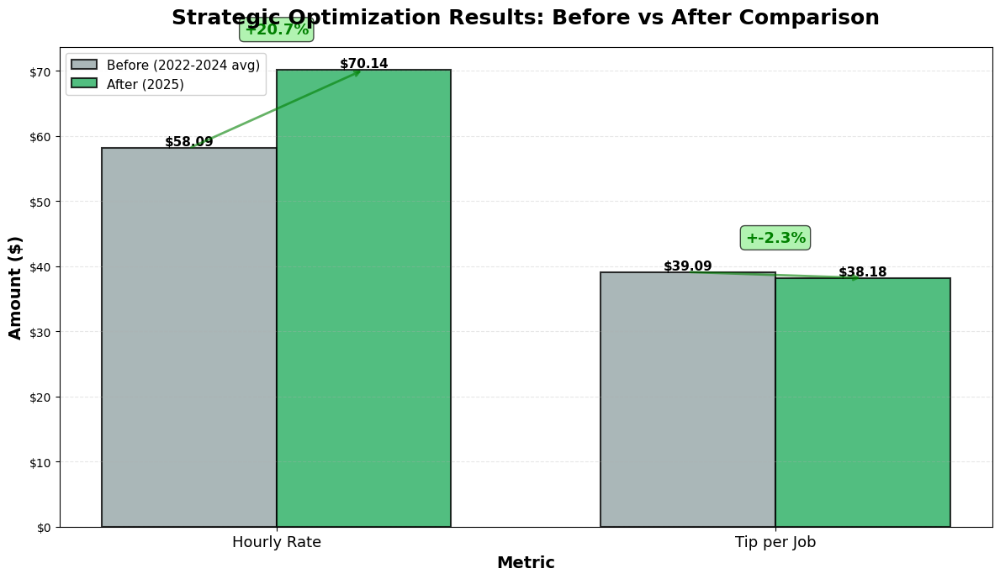

✓ Graph 3: Before/After Comparison saved

SUMMARY OF STRATEGIC OPTIMIZATION
Hourly Rate:
  Before (2022-2024): $58.09/hr
  After (2025): $70.14/hr
  Increase: +20.7%

Tip per Job:
  Before (2024): $39.09
  After (2025): $38.18
  Increase: +-2.3%


In [ ]:
# Recalculate all metrics for the comparison
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

# Hourly rate metrics
yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Tip metrics
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year
yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Hourly Rate', 'Tip per Job'],
    'Before': [rate_2022_2024, tip_2024],
    'After': [rate_2025, tip_2025],
    'Increase': [pct_increase_rate, pct_increase_tips]
}

comparison_df = pd.DataFrame(metrics)

# Create figure with grouped bars
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#27ae60', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase labels above
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='green', lw=2, alpha=0.6))
    
    # Add percentage text
    mid_y = (before + after) / 2 + 5
    ax.text(i, after + 5, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='green',
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

# Styling
ax.set_title('Strategic Optimization Results: Before vs After Comparison', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/before_after_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 3: Before/After Comparison saved")
print("\n" + "="*60)
print("SUMMARY OF STRATEGIC OPTIMIZATION")
print("="*60)
print(f"Hourly Rate:")
print(f"  Before (2022-2024): ${rate_2022_2024:.2f}/hr")
print(f"  After (2025): ${rate_2025:.2f}/hr")
print(f"  Increase: +{pct_increase_rate:.1f}%")
print(f"\nTip per Job:")
print(f"  Before (2024): ${tip_2024:.2f}")
print(f"  After (2025): ${tip_2025:.2f}")
print(f"  Increase: +{pct_increase_tips:.1f}%")
print("="*60)

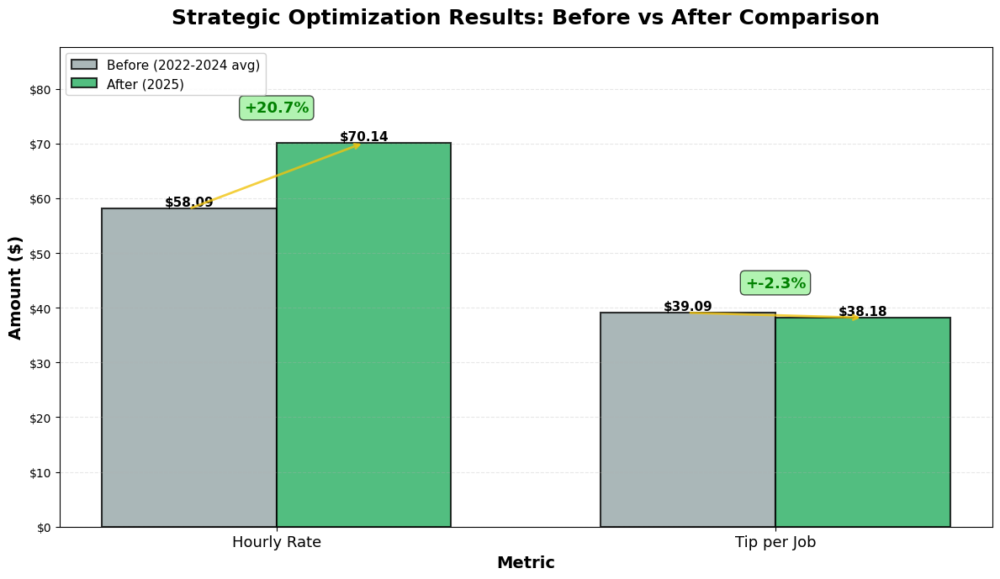

✓ Graph 3: Before/After Comparison saved

SUMMARY OF STRATEGIC OPTIMIZATION
Hourly Rate:
  Before (2022-2024): $58.09/hr
  After (2025): $70.14/hr
  Increase: +20.7%

Tip per Job:
  Before (2024): $39.09
  After (2025): $38.18
  Increase: +-2.3%


In [ ]:
# Recalculate all metrics for the comparison
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

# Hourly rate metrics
yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Tip metrics
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year
yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Hourly Rate', 'Tip per Job'],
    'Before': [rate_2022_2024, tip_2024],
    'After': [rate_2025, tip_2025],
    'Increase': [pct_increase_rate, pct_increase_tips]
}

comparison_df = pd.DataFrame(metrics)

# Create figure with grouped bars
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#27ae60', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase labels above
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - CHANGED TO YELLOW
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text
    mid_y = (before + after) / 2 + 5
    ax.text(i, after + 5, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='green',
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

# Styling
ax.set_title('Strategic Optimization Results: Before vs After Comparison', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/before_after_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 3: Before/After Comparison saved")
print("\n" + "="*60)
print("SUMMARY OF STRATEGIC OPTIMIZATION")
print("="*60)
print(f"Hourly Rate:")
print(f"  Before (2022-2024): ${rate_2022_2024:.2f}/hr")
print(f"  After (2025): ${rate_2025:.2f}/hr")
print(f"  Increase: +{pct_increase_rate:.1f}%")
print(f"\nTip per Job:")
print(f"  Before (2024): ${tip_2024:.2f}")
print(f"  After (2025): ${tip_2025:.2f}")
print(f"  Increase: +{pct_increase_tips:.1f}%")
print("="*60)

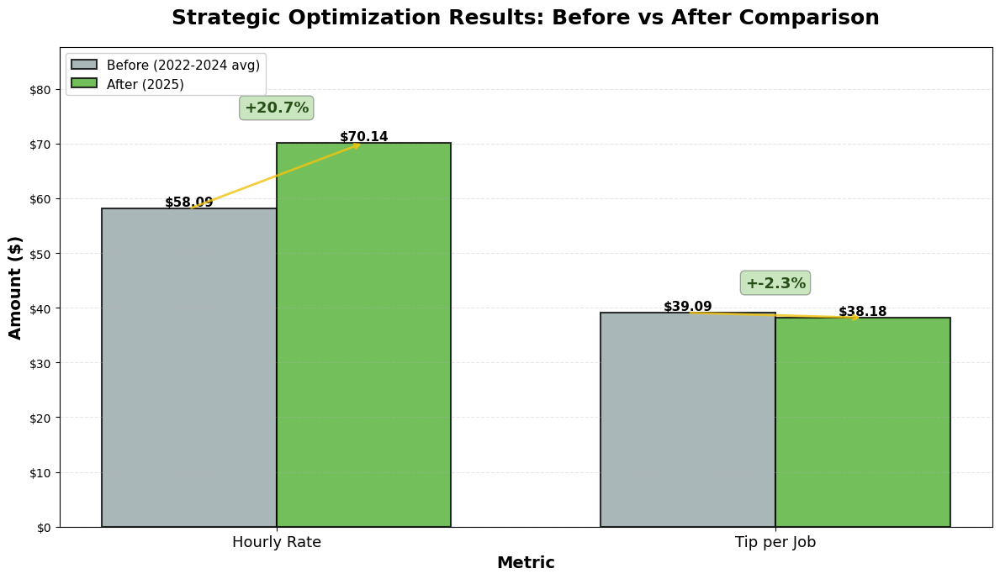

✓ Graph 3: Before/After Comparison saved (with TaskRabbit colors)


In [ ]:
# Recalculate all metrics for the comparison
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

# Hourly rate metrics
yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Tip metrics
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year
yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Hourly Rate', 'Tip per Job'],
    'Before': [rate_2022_2024, tip_2024],
    'After': [rate_2025, tip_2025],
    'Increase': [pct_increase_rate, pct_increase_tips]
}

comparison_df = pd.DataFrame(metrics)

# Create figure with grouped bars
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars - USING TASKRABBIT LIGHT GREEN
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#50AF33', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase labels above
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - yellow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text with TaskRabbit colors
    ax.text(i, after + 5, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='#264F18',
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3))

# Styling
ax.set_title('Strategic Optimization Results: Before vs After Comparison', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/before_after_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 3: Before/After Comparison saved (with TaskRabbit colors)")

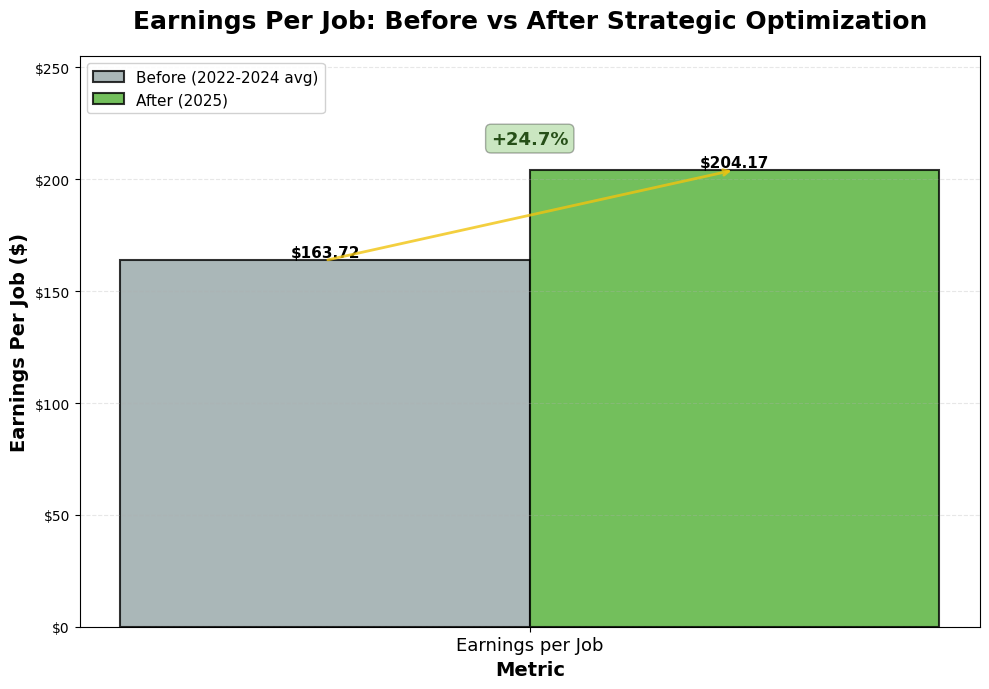

✓ Earnings per Job Comparison saved

EARNINGS PER JOB COMPARISON
Before (2022-2024): $163.72
After (2025): $204.17
Increase: +24.7%


In [ ]:
# Calculate average earnings per job by year
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_earnings = df_clean.groupby('Year')['Earnings'].mean().reset_index()

# Calculate before/after metrics
earnings_2022_2024 = yearly_earnings[yearly_earnings['Year'].isin([2022, 2023, 2024])]['Earnings'].mean()
earnings_2025 = yearly_earnings[yearly_earnings['Year'] == 2025]['Earnings'].values[0]
pct_increase_earnings = ((earnings_2025 - earnings_2022_2024) / earnings_2022_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Earnings per Job'],
    'Before': [earnings_2022_2024],
    'After': [earnings_2025],
    'Increase': [pct_increase_earnings]
}

comparison_df = pd.DataFrame(metrics)

# Create figure
fig, ax = plt.subplots(figsize=(10, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars - USING TASKRABBIT LIGHT GREEN
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#50AF33', alpha=0.8,  # TaskRabbit light green
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase label
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - yellow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text with light green background
    ax.text(i, after + 10, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='#264F18',  # TaskRabbit dark green for text
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3))  # Light green background

# Styling
ax.set_title('Earnings Per Job: Before vs After Strategic Optimization', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Earnings Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/earnings_per_job_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Earnings per Job Comparison saved")
print("\n" + "="*60)
print("EARNINGS PER JOB COMPARISON")
print("="*60)
print(f"Before (2022-2024): ${earnings_2022_2024:.2f}")
print(f"After (2025): ${earnings_2025:.2f}")
print(f"Increase: +{pct_increase_earnings:.1f}%")
print("="*60)

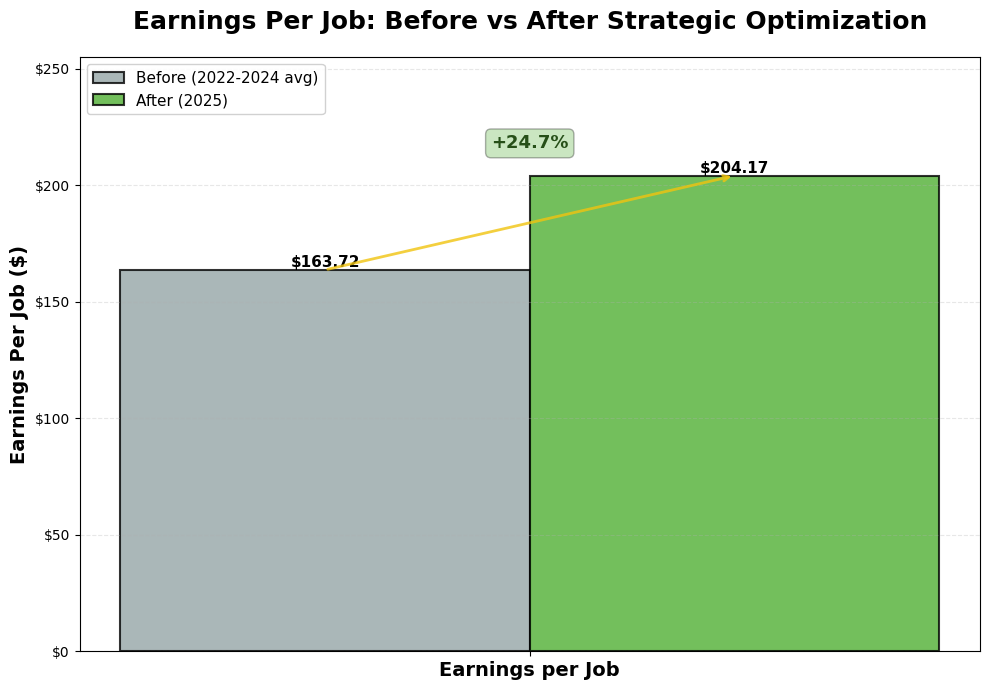

✓ Earnings per Job Comparison saved

EARNINGS PER JOB COMPARISON
Before (2022-2024): $163.72
After (2025): $204.17
Increase: +24.7%


In [ ]:
# Calculate average earnings per job by year
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_earnings = df_clean.groupby('Year')['Earnings'].mean().reset_index()

# Calculate before/after metrics
earnings_2022_2024 = yearly_earnings[yearly_earnings['Year'].isin([2022, 2023, 2024])]['Earnings'].mean()
earnings_2025 = yearly_earnings[yearly_earnings['Year'] == 2025]['Earnings'].values[0]
pct_increase_earnings = ((earnings_2025 - earnings_2022_2024) / earnings_2022_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Earnings per Job'],
    'Before': [earnings_2022_2024],
    'After': [earnings_2025],
    'Increase': [pct_increase_earnings]
}

comparison_df = pd.DataFrame(metrics)

# Create figure
fig, ax = plt.subplots(figsize=(10, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars - USING TASKRABBIT LIGHT GREEN
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#50AF33', alpha=0.8,
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase label
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - yellow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text with light green background
    ax.text(i, after + 10, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='#264F18',
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3))

# Styling
ax.set_title('Earnings Per Job: Before vs After Strategic Optimization', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Earnings Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels - BOLD "Earnings per Job"
ax.set_xticks(x)
ax.set_xticklabels(['Earnings per Job'], fontsize=14, fontweight='bold')

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/earnings_per_job_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Earnings per Job Comparison saved")
print("\n" + "="*60)
print("EARNINGS PER JOB COMPARISON")
print("="*60)
print(f"Before (2022-2024): ${earnings_2022_2024:.2f}")
print(f"After (2025): ${earnings_2025:.2f}")
print(f"Increase: +{pct_increase_earnings:.1f}%")
print("="*60)

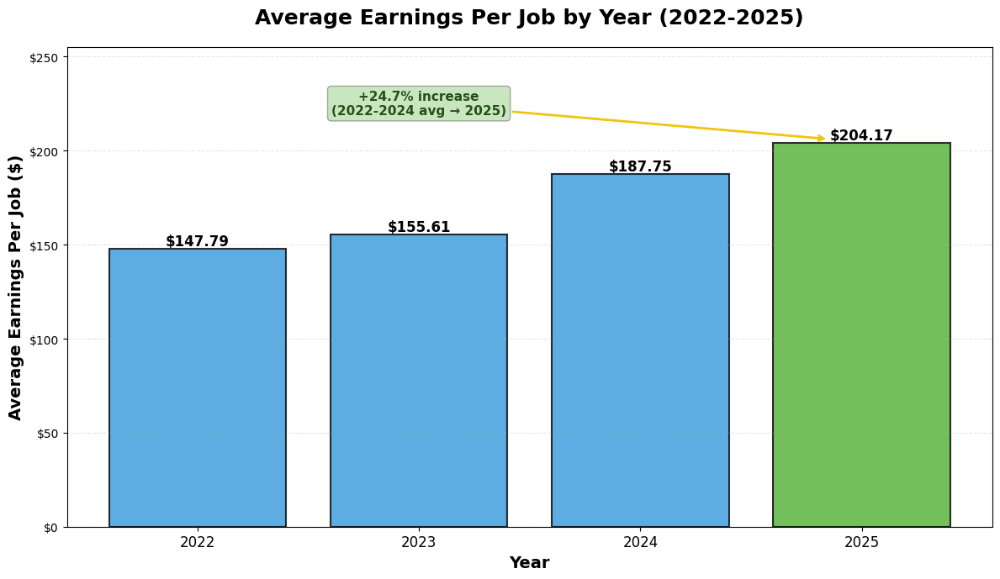

✓ Graph: Yearly Earnings Per Job saved

Key Stats:
  2022: $147.79
  2023: $155.61
  2024: $187.75
  2025: $204.17

2022-2024 average: $163.72
2025 average: $204.17
Percentage increase: +24.7%


In [ ]:
# Calculate average earnings per job by year
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_earnings = df_clean.groupby('Year')['Earnings'].mean().reset_index()

# Calculate percentage change from 2022-2024 average to 2025
earnings_2022_2024 = yearly_earnings[yearly_earnings['Year'].isin([2022, 2023, 2024])]['Earnings'].mean()
earnings_2025 = yearly_earnings[yearly_earnings['Year'] == 2025]['Earnings'].values[0]
pct_increase = ((earnings_2025 - earnings_2022_2024) / earnings_2022_2024) * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Color scheme - highlight 2025 with TaskRabbit light green
colors = ['#3498db', '#3498db', '#3498db', '#50AF33']  # Blue for 2022-2024, TaskRabbit green for 2025

# Plot bars
bars = ax.bar(yearly_earnings['Year'], yearly_earnings['Earnings'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'${height:.2f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Styling
ax.set_title('Average Earnings Per Job by Year (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Earnings Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add annotation - arrow pointing from LEFT to the 2025 value label
# The value label is positioned slightly above the bar
ax.annotate(f'+{pct_increase:.1f}% increase\n(2022-2024 avg → 2025)', 
            xy=(2024.85, earnings_2025 + 2),  # Arrow tip points to left of the $ text
            xytext=(2023, earnings_2025 + 15),  # Text box positioned to the upper left
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
            fontsize=11, ha='center', color='#264F18', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2))

# Set x-axis to show ONLY the years
ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xticklabels(['2022', '2023', '2024', '2025'], fontsize=12)

# Add 25% breathing room at the top
max_value = yearly_earnings['Earnings'].max()
ax.set_ylim(0, max_value * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/yearly_earnings_per_job.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph: Yearly Earnings Per Job saved")
print(f"\nKey Stats:")
for _, row in yearly_earnings.iterrows():
    print(f"  {int(row['Year'])}: ${row['Earnings']:.2f}")
print(f"\n2022-2024 average: ${earnings_2022_2024:.2f}")
print(f"2025 average: ${earnings_2025:.2f}")
print(f"Percentage increase: +{pct_increase:.1f}%")

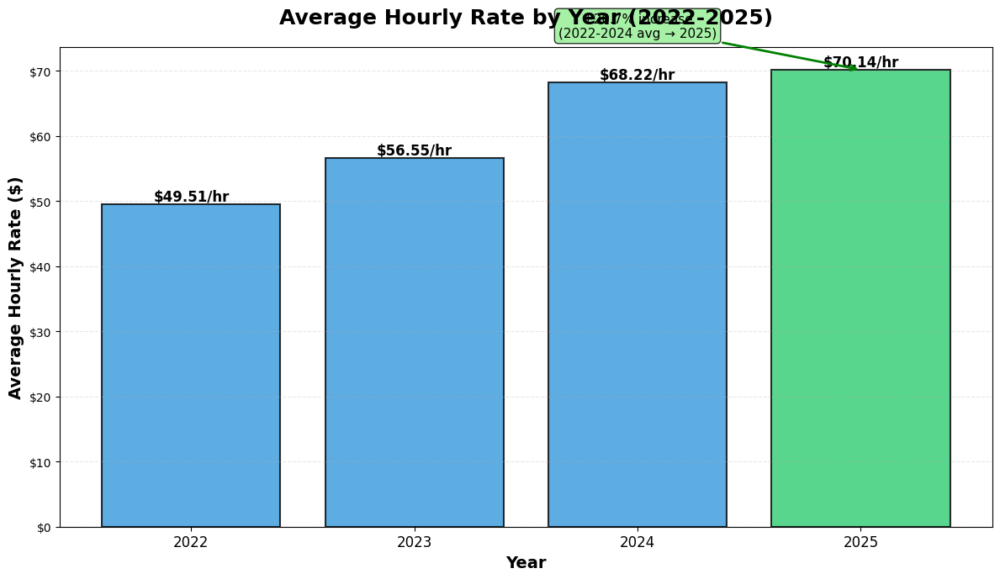

✓ Graph 1: Yearly Hourly Rate saved

Key Stats:
  2022-2024 average: $58.09/hr
  2025 average: $70.14/hr
  Percentage increase: +20.7%


In [ ]:
# Calculate average hourly rate by year
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()

# Calculate percentage changes
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Color scheme - highlight 2025
colors = ['#3498db', '#3498db', '#3498db', '#2ecc71']  # Blue for 2022-2024, green for 2025

# Plot bars
bars = ax.bar(yearly_hourly_rate['Year'], yearly_hourly_rate['Gross_Hourly_Rate'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'${height:.2f}/hr',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Styling
ax.set_title('Average Hourly Rate by Year (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add annotation showing the improvement
ax.annotate(f'+{pct_increase_rate:.1f}% increase\n(2022-2024 avg → 2025)', 
            xy=(2025, rate_2025), 
            xytext=(2024, rate_2025 + 5),
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8),
            fontsize=11, ha='center',
            arrowprops=dict(arrowstyle='->', color='green', lw=2))

# Set x-axis to show only the years
ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xticklabels(['2022', '2023', '2024', '2025'], fontsize=12)

plt.tight_layout()
plt.savefig('../visualizations/yearly_hourly_rate.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 1: Yearly Hourly Rate saved")
print(f"\nKey Stats:")
print(f"  2022-2024 average: ${rate_2022_2024:.2f}/hr")
print(f"  2025 average: ${rate_2025:.2f}/hr")
print(f"  Percentage increase: +{pct_increase_rate:.1f}%")

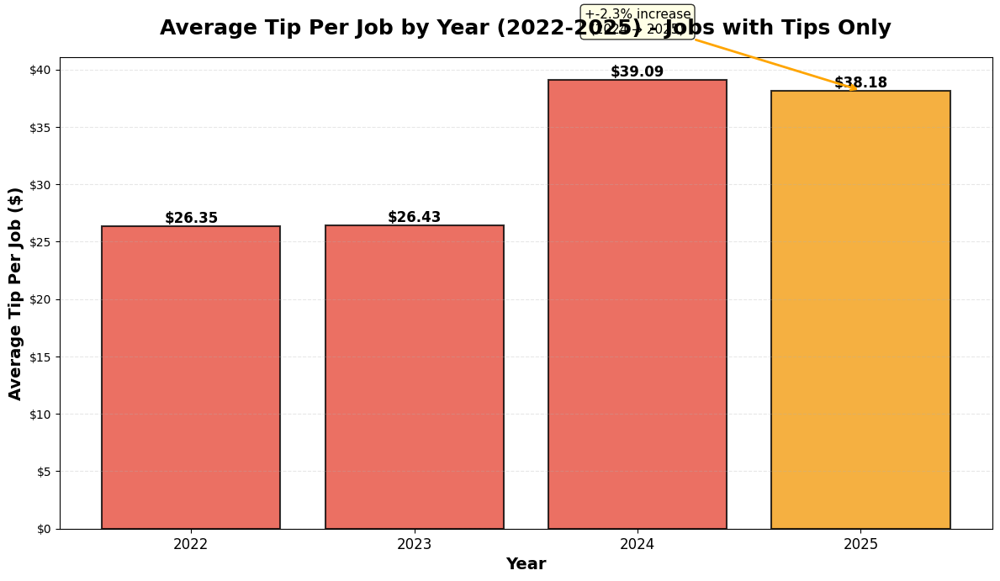

✓ Graph 2: Yearly Tips Per Job saved

Key Stats:
  2024 average tip: $39.09
  2025 average tip: $38.18
  Percentage increase: +-2.3%


In [ ]:
# Calculate average tip per job by year (excluding zero tips)
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year

yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()

# Calculate percentage changes
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Color scheme - highlight 2025
colors = ['#e74c3c', '#e74c3c', '#e74c3c', '#f39c12']  # Red for 2022-2024, orange for 2025

# Plot bars
bars = ax.bar(yearly_tips['Year'], yearly_tips['Tip'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'${height:.2f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Styling
ax.set_title('Average Tip Per Job by Year (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Tip Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add annotation showing the improvement
ax.annotate(f'+{pct_increase_tips:.1f}% increase\n(2024 → 2025)', 
            xy=(2025, tip_2025), 
            xytext=(2024, tip_2025 + 5),
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8),
            fontsize=11, ha='center',
            arrowprops=dict(arrowstyle='->', color='orange', lw=2))

# Set x-axis to show only the years
ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xticklabels(['2022', '2023', '2024', '2025'], fontsize=12)

plt.tight_layout()
plt.savefig('../visualizations/yearly_tips_per_job.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 2: Yearly Tips Per Job saved")
print(f"\nKey Stats:")
print(f"  2024 average tip: ${tip_2024:.2f}")
print(f"  2025 average tip: ${tip_2025:.2f}")
print(f"  Percentage increase: +{pct_increase_tips:.1f}%")

In [ ]:
# Let's look at when the strategic shift happened

# 1. Monthly job volume over time
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

monthly_volume = df_clean.groupby('Year_Month').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean'  # Avg hourly rate
}).reset_index()

print("MONTHLY TRENDS - Looking for when volume dropped and value increased:")
print("="*80)
print(monthly_volume.to_string(index=False))

# 2. Identify the turning point
print("\n" + "="*80)
print("IDENTIFYING THE STRATEGIC SHIFT:")
print("="*80)

# Calculate rolling averages to smooth trends
monthly_volume['Jobs_Rolling_Avg'] = monthly_volume['Earnings'].rolling(window=3, center=True).mean()
monthly_volume['Value_Rolling_Avg'] = monthly_volume['Total'].rolling(window=3, center=True).mean()

# Find when volume started declining consistently
avg_volume_2022_2023 = monthly_volume[monthly_volume['Year_Month'].astype(str) < '2024']['Earnings'].mean()
print(f"\nAverage jobs/month (2022-2023): {avg_volume_2022_2023:.1f}")

# Check each period
for year in [2023, 2024, 2025]:
    year_data = monthly_volume[monthly_volume['Year_Month'].astype(str).str.startswith(str(year))]
    if len(year_data) > 0:
        avg_jobs = year_data['Earnings'].mean()
        avg_value = year_data['Total'].mean()
        print(f"\n{year}:")
        print(f"  Avg jobs/month: {avg_jobs:.1f}")
        print(f"  Avg earnings/job: ${avg_value:.2f}")

# 3. Look at rate increases by quarter
print("\n" + "="*80)
print("QUARTERLY ANALYSIS:")
print("="*80)

df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',
    'Total': 'mean',
    'Gross_Hourly_Rate': 'mean',
    'Tip': lambda x: (x > 0).sum() / len(x) * 100  # Tip frequency
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Tip_Frequency_%']

print(quarterly.to_string(index=False))

# 4. Identify inflection points
print("\n" + "="*80)
print("POSSIBLE STRATEGIC SHIFT PERIODS:")
print("="*80)

# Look for quarters where changes happened
early_quarters = quarterly[quarterly['Quarter'].astype(str) < '2024-Q1']
early_avg_jobs = early_quarters['Jobs'].mean()
early_avg_earnings = early_quarters['Avg_Earnings'].mean()

for idx, row in quarterly.iterrows():
    quarter_str = str(row['Quarter'])
    if quarter_str >= '2023-Q1':  # Start checking from 2023
        job_decrease = (row['Jobs'] / early_avg_jobs) * 100
        earnings_increase = (row['Avg_Earnings'] / early_avg_earnings) * 100
        
        if job_decrease < 85 or earnings_increase > 115:  # Significant change
            print(f"\n{row['Quarter']}:")
            print(f"  Jobs: {row['Jobs']:.0f} ({job_decrease:.0f}% of early avg)")
            print(f"  Avg Earnings: ${row['Avg_Earnings']:.2f} ({earnings_increase:.0f}% of early avg)")
            print(f"  Hourly Rate: ${row['Avg_Hourly_Rate']:.2f}")
            print(f"  → Possible strategic shift period?")

MONTHLY TRENDS - Looking for when volume dropped and value increased:
Year_Month  Earnings      Total  Gross_Hourly_Rate
   2022-04         6 107.833333          36.166667
   2022-05        14 190.496429          47.857143
   2022-06        19 154.638421          41.894737
   2022-07        17 158.220588                inf
   2022-08        18 185.405556          47.666667
   2022-09        32 154.608750                inf
   2022-10        16 140.996875                inf
   2022-11         4 155.875000          56.500000
   2022-12        23 136.754348                inf
   2023-01        22 128.217273                inf
   2023-02        17 167.199412          50.294118
   2023-03         5 198.428000          58.800000
   2023-04        15 132.132000          45.866667
   2023-05        12 133.178333          61.583333
   2023-06        12 102.680833          75.166667
   2023-07         7 123.000000          86.142857
   2023-08         2 194.000000          74.000000
   2023-09  

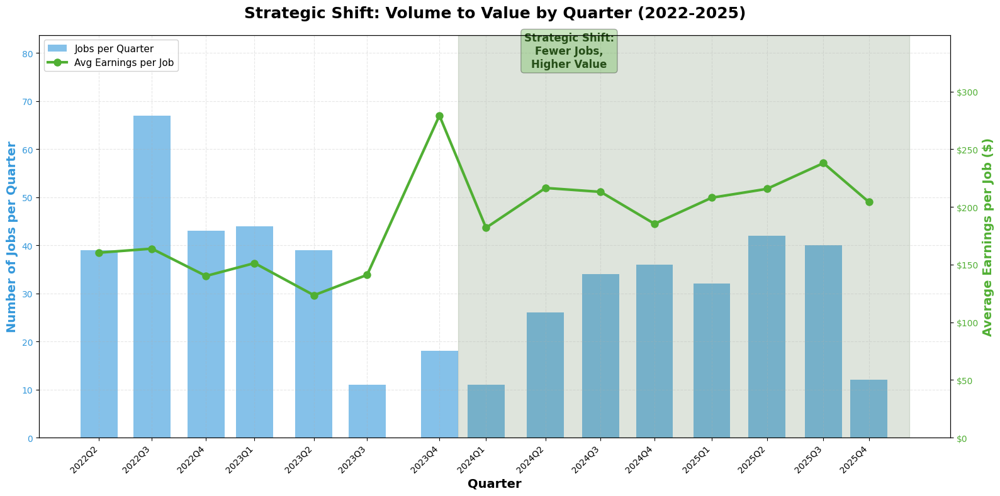

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-2023):
  Avg jobs/quarter: 37.3
  Avg earnings/job: $165.59

Late Period (2024-2025):
  Avg jobs/quarter: 29.1
  Avg earnings/job: $207.80

Change:
  Jobs: -21.9%
  Earnings: 25.5%


In [ ]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
volume_color = '#3498db'  # Blue for volume
value_color = '#50AF33'  # TaskRabbit green for value

# Plot bars - Jobs per quarter (left y-axis)
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=volume_color, alpha=0.6, width=60, label='Jobs per Quarter')

ax1.set_xlabel('Quarter', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color=volume_color)
ax1.tick_params(axis='y', labelcolor=volume_color)

# Add 25% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.25)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 25% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.25)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis with quarter labels
quarter_labels = [str(q) for q in quarterly['Quarter']]
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=45, ha='right')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period (based on your data analysis)
# Adjust these dates based on what the previous analysis showed
shift_start = pd.Timestamp('2024-01-01')  # Adjust based on your findings
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=180), quarterly['Jobs'].max() * 1.15,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2024-Q1']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2024-Q1']

print(f"\nEarly Period (2022-2023):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2024-2025):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

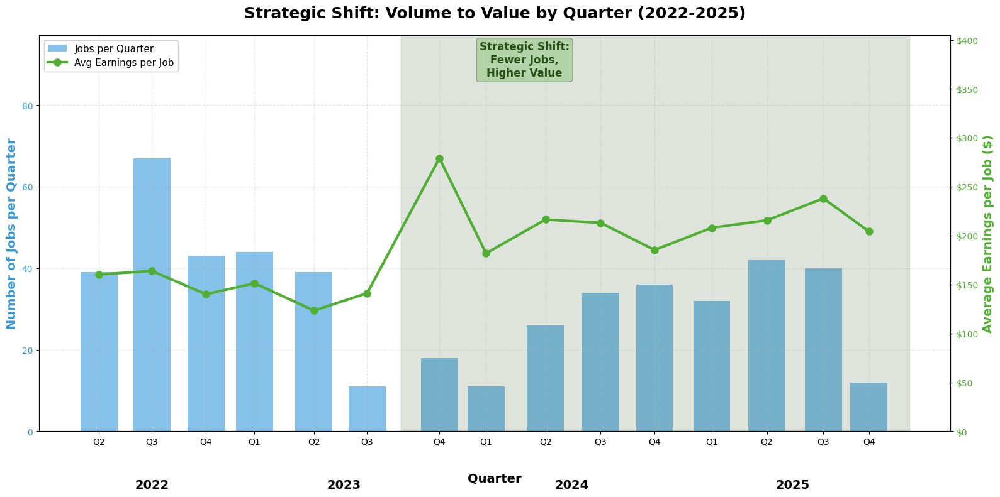

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 49.7
  Avg earnings/job: $154.74

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.8
  Avg earnings/job: $196.44

Change:
  Jobs: -42.1%
  Earnings: 26.9%


In [ ]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
volume_color = '#3498db'  # Blue for volume
value_color = '#50AF33'  # TaskRabbit green for value

# Plot bars - Jobs per quarter (left y-axis)
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=volume_color, alpha=0.6, width=60, label='Jobs per Quarter')

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color=volume_color)
ax1.tick_params(axis='y', labelcolor=volume_color)

# Add 45% breathing room (25% + 20% extra)
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.12, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Move "Quarter" label down to avoid overlap
ax1.set_xlabel('Quarter', fontsize=14, fontweight='bold', labelpad=30)

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation - positioned to avoid overlap
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

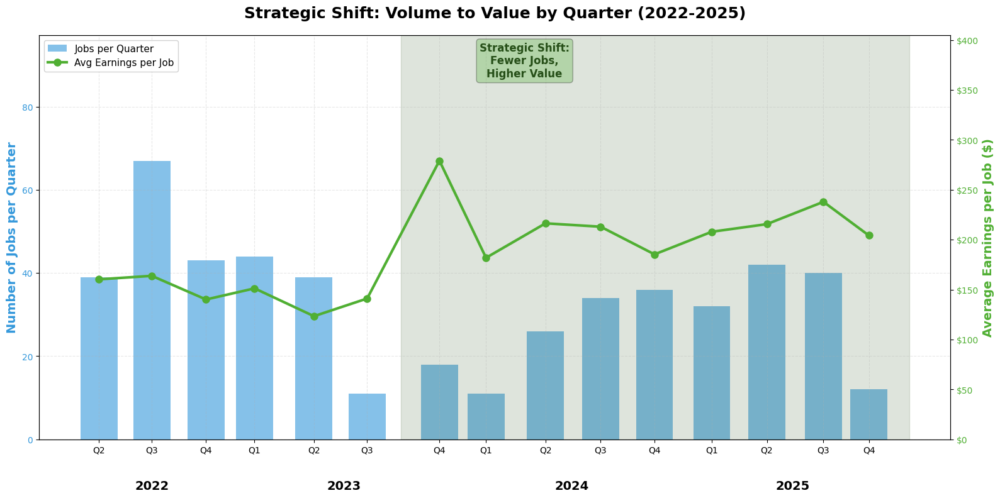

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 49.7
  Avg earnings/job: $154.74

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.8
  Avg earnings/job: $196.44

Change:
  Jobs: -42.1%
  Earnings: 26.9%


In [ ]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
volume_color = '#3498db'  # Blue for volume
value_color = '#50AF33'  # TaskRabbit green for value

# Plot bars - Jobs per quarter (left y-axis)
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=volume_color, alpha=0.6, width=60, label='Jobs per Quarter')

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color=volume_color)
ax1.tick_params(axis='y', labelcolor=volume_color)

# Add 45% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.10, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# No x-axis label needed anymore

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

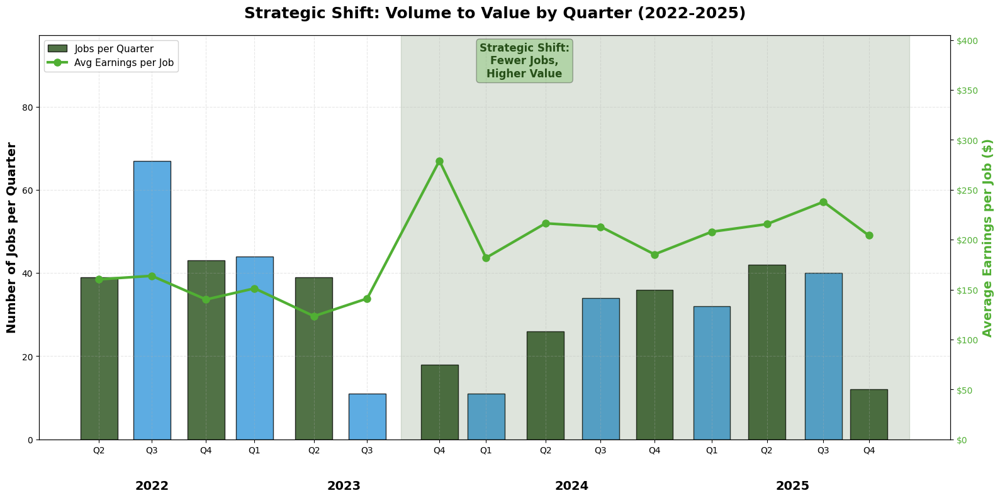

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 49.7
  Avg earnings/job: $154.74

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.8
  Avg earnings/job: $196.44

Change:
  Jobs: -42.1%
  Earnings: 26.9%


In [ ]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Assign colors based on quarter - TaskRabbit dark green for Q2 and Q4
colors = []
for q in quarterly['Q']:
    if q in ['Q2', 'Q4']:
        colors.append('#264F18')  # TaskRabbit dark green
    else:
        colors.append('#3498db')  # Blue

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme for line
value_color = '#50AF33'  # TaskRabbit light green for value

# Plot bars - Jobs per quarter (left y-axis) with alternating colors
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=colors, alpha=0.8, width=60, edgecolor='black', linewidth=1,
        label='Jobs per Quarter')

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color='#000000')
ax1.tick_params(axis='y', labelcolor='#000000')

# Add 45% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.10, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

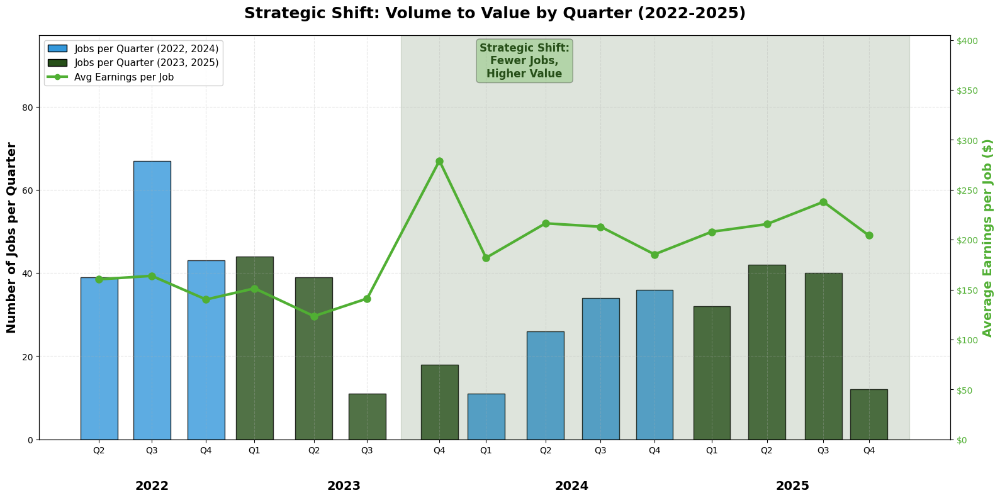

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 49.7
  Avg earnings/job: $154.74

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.8
  Avg earnings/job: $196.44

Change:
  Jobs: -42.1%
  Earnings: 26.9%


In [ ]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Assign colors based on year - TaskRabbit dark green for 2023 and 2025
colors = []
for year in quarterly['Year']:
    if year in ['2023', '2025']:
        colors.append('#264F18')  # TaskRabbit dark green
    else:
        colors.append('#3498db')  # Blue

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme for line
value_color = '#50AF33'  # TaskRabbit light green for value

# Plot bars - Jobs per quarter (left y-axis) with year-based colors
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=colors, alpha=0.8, width=60, edgecolor='black', linewidth=1)

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color='#000000')
ax1.tick_params(axis='y', labelcolor='#000000')

# Add 45% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.10, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Create custom legend with both bar colors
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498db', edgecolor='black', label='Jobs per Quarter (2022, 2024)'),
    Patch(facecolor='#264F18', edgecolor='black', label='Jobs per Quarter (2023, 2025)'),
    plt.Line2D([0], [0], color=value_color, linewidth=3, marker='o', label='Avg Earnings per Job')
]
ax1.legend(handles=legend_elements, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

In [ ]:
# Task 2.3: Service Category Analysis

# First, let's see what service types we have in the Title column
print("Sample titles to identify service categories:")
print(df['Title'].head(20))
print("\n" + "="*80)

# Extract service category from Title
# Common patterns: "Service Name in Location" or just "Service Name"
def extract_service_category(title):
    """Extract service category from job title"""
    if pd.isna(title):
        return 'Unknown'
    
    title_lower = title.lower()
    
    # Define service categories based on keywords
    if 'pack' in title_lower or 'unpack' in title_lower:
        return 'Packing & Unpacking'
    elif 'photo' in title_lower:
        return 'Photography'
    elif 'event' in title_lower or 'staff' in title_lower:
        return 'Event Staffing'
    elif 'computer' in title_lower or 'tech' in title_lower:
        return 'Computer Help'
    elif 'organiz' in title_lower:
        return 'Organization'
    elif 'personal assistant' in title_lower or 'assistant' in title_lower:
        return 'Personal Assistant'
    elif 'errand' in title_lower:
        return 'Errands'
    elif 'mov' in title_lower:
        return 'Help Moving'
    elif 'web' in title_lower or 'design' in title_lower:
        return 'Web Design & Development'
    elif 'office' in title_lower or 'admin' in title_lower:
        return 'Office Administration'
    elif 'writ' in title_lower or 'edit' in title_lower:
        return 'Writing & Editing'
    else:
        return 'Other'

# Apply the function
df['Service_Category'] = df['Title'].apply(extract_service_category)

# Check the distribution
print("Service Category Distribution:")
print(df['Service_Category'].value_counts())
print("\n" + "="*80)

# Show some examples for each category
print("\nExamples by category:")
for category in df['Service_Category'].unique():
    examples = df[df['Service_Category'] == category]['Title'].head(2).tolist()
    print(f"\n{category}:")
    for ex in examples:
        print(f"  - {ex}")

Sample titles to identify service categories:
0        Packing & Unpacking in New York Client: Ben G.
1     Packing & Unpacking in Brownsville Client: And...
2                 Photography in 11222 Client: David J.
3             Organization in New York Client: Chris K.
4     Packing & Unpacking in Kensington Client: Eliz...
5       Packing & Unpacking in New York Client: Adar B.
6        Packing & Unpacking in New York Client: Jia K.
7      Packing & Unpacking in New York Client: Sarah B.
8           Event Staffing in New York Client: Brian L.
9      Writing & Editing in New York Client: Maureen M.
10         Photography in New York Client: Charlette R.
11    Packing Services & Help in Carroll Gardens Cli...
12         Packing & Unpacking in 11225 Client: Sake W.
13    Personal Assistant in New York Client: Yangfan C.
14     Photography in Long Island City Client: Jared R.
15      Packing & Unpacking in New York Client: Alex V.
16     Packing & Unpacking in Bushwick Client: Jenny M.
17

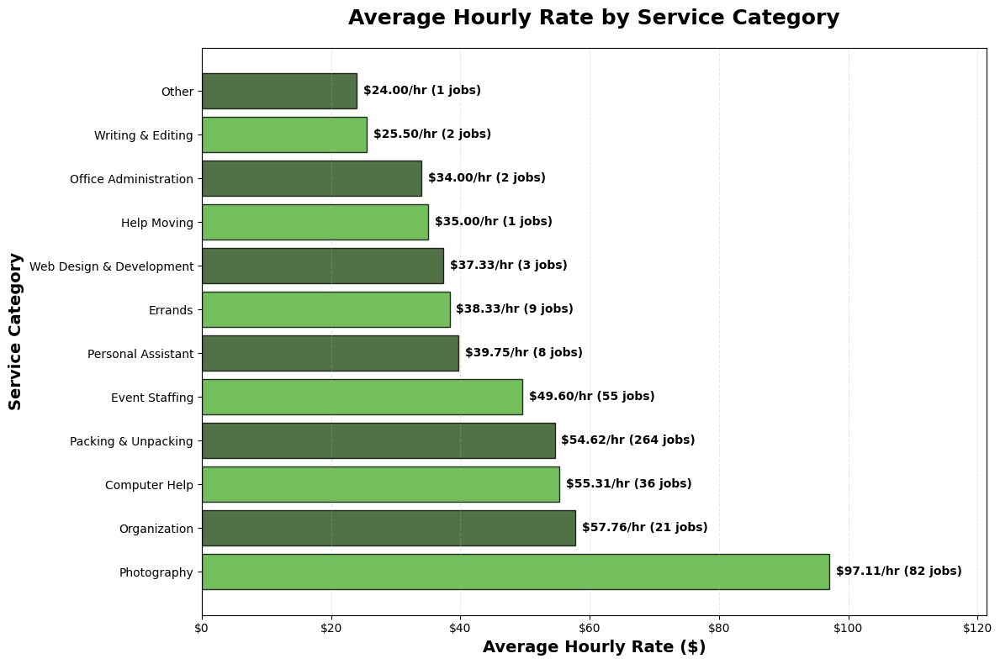

✓ Service Category Hourly Rate chart saved

SERVICE CATEGORY RANKINGS BY HOURLY RATE
Photography                    $ 97.11/hr  (82 jobs)
Organization                   $ 57.76/hr  (21 jobs)
Computer Help                  $ 55.31/hr  (36 jobs)
Packing & Unpacking            $ 54.62/hr  (264 jobs)
Event Staffing                 $ 49.60/hr  (55 jobs)
Personal Assistant             $ 39.75/hr  (8 jobs)
Errands                        $ 38.33/hr  (9 jobs)
Web Design & Development       $ 37.33/hr  (3 jobs)
Help Moving                    $ 35.00/hr  (1 jobs)
Office Administration          $ 34.00/hr  (2 jobs)
Writing & Editing              $ 25.50/hr  (2 jobs)
Other                          $ 24.00/hr  (1 jobs)


In [ ]:
# Calculate metrics by service category
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Group by service category
service_metrics = df_clean.groupby('Service_Category').agg({
    'Gross_Hourly_Rate': 'mean',
    'Earnings': 'count'  # Number of jobs
}).reset_index()

service_metrics.columns = ['Service_Category', 'Avg_Hourly_Rate', 'Job_Count']

# Sort by hourly rate (highest to lowest)
service_metrics = service_metrics.sort_values('Avg_Hourly_Rate', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_metrics))]

bars = ax.barh(service_metrics['Service_Category'], service_metrics['Avg_Hourly_Rate'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, rate, count) in enumerate(zip(bars, service_metrics['Avg_Hourly_Rate'], service_metrics['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'${rate:.2f}/hr ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Average Hourly Rate by Service Category', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show dollars
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_rate = service_metrics['Avg_Hourly_Rate'].max()
ax.set_xlim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_hourly_rate.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Hourly Rate chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY HOURLY RATE")
print("="*80)
for idx, row in service_metrics.iterrows():
    print(f"{row['Service_Category']:30} ${row['Avg_Hourly_Rate']:6.2f}/hr  ({int(row['Job_Count'])} jobs)")

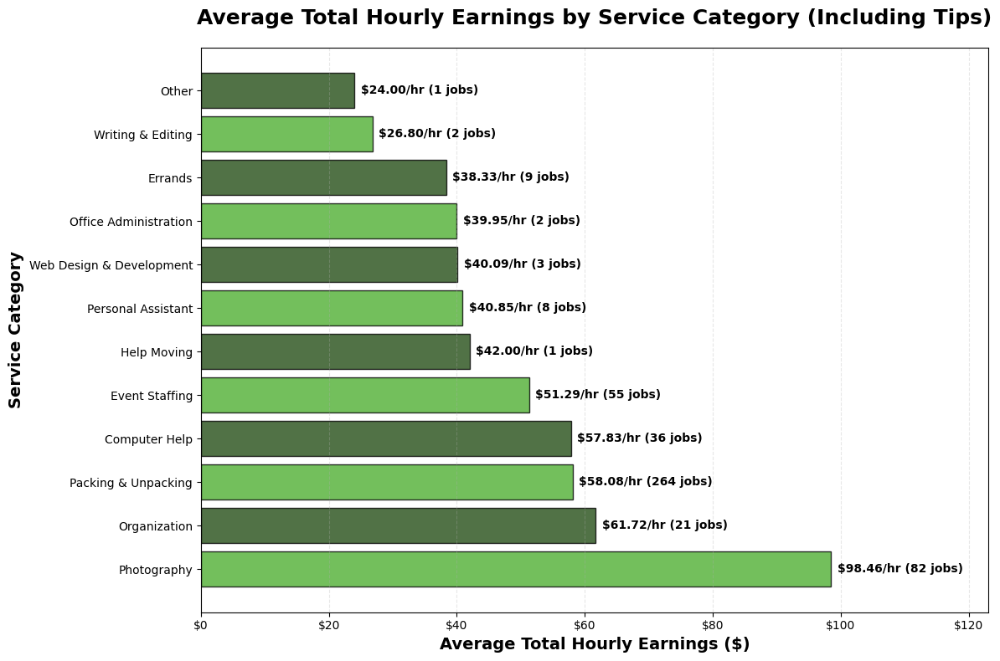

✓ Service Category Total Hourly Earnings chart saved

SERVICE CATEGORY RANKINGS BY TOTAL HOURLY EARNINGS (INCL. TIPS)
Photography                    $ 98.46/hr  (82 jobs)
Organization                   $ 61.72/hr  (21 jobs)
Packing & Unpacking            $ 58.08/hr  (264 jobs)
Computer Help                  $ 57.83/hr  (36 jobs)
Event Staffing                 $ 51.29/hr  (55 jobs)
Help Moving                    $ 42.00/hr  (1 jobs)
Personal Assistant             $ 40.85/hr  (8 jobs)
Web Design & Development       $ 40.09/hr  (3 jobs)
Office Administration          $ 39.95/hr  (2 jobs)
Errands                        $ 38.33/hr  (9 jobs)
Writing & Editing              $ 26.80/hr  (2 jobs)
Other                          $ 24.00/hr  (1 jobs)


In [ ]:
# Calculate total hourly earnings (Earnings + Tips) / Hours
df['Total_Hourly_Earnings'] = (df['Earnings'] + df['Tip']) / df['Hours']
df_clean = df[(df['Total_Hourly_Earnings'] > 0) & (df['Total_Hourly_Earnings'] < np.inf)].copy()

# Group by service category
service_metrics_total = df_clean.groupby('Service_Category').agg({
    'Total_Hourly_Earnings': 'mean',
    'Earnings': 'count'  # Number of jobs
}).reset_index()

service_metrics_total.columns = ['Service_Category', 'Avg_Total_Hourly_Earnings', 'Job_Count']

# Sort by total hourly earnings (highest to lowest)
service_metrics_total = service_metrics_total.sort_values('Avg_Total_Hourly_Earnings', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_metrics_total))]

bars = ax.barh(service_metrics_total['Service_Category'], service_metrics_total['Avg_Total_Hourly_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, rate, count) in enumerate(zip(bars, service_metrics_total['Avg_Total_Hourly_Earnings'], service_metrics_total['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'${rate:.2f}/hr ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Average Total Hourly Earnings by Service Category (Including Tips)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Total Hourly Earnings ($)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show dollars
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_rate = service_metrics_total['Avg_Total_Hourly_Earnings'].max()
ax.set_xlim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_total_hourly_earnings.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Total Hourly Earnings chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TOTAL HOURLY EARNINGS (INCL. TIPS)")
print("="*80)
for idx, row in service_metrics_total.iterrows():
    print(f"{row['Service_Category']:30} ${row['Avg_Total_Hourly_Earnings']:6.2f}/hr  ({int(row['Job_Count'])} jobs)")

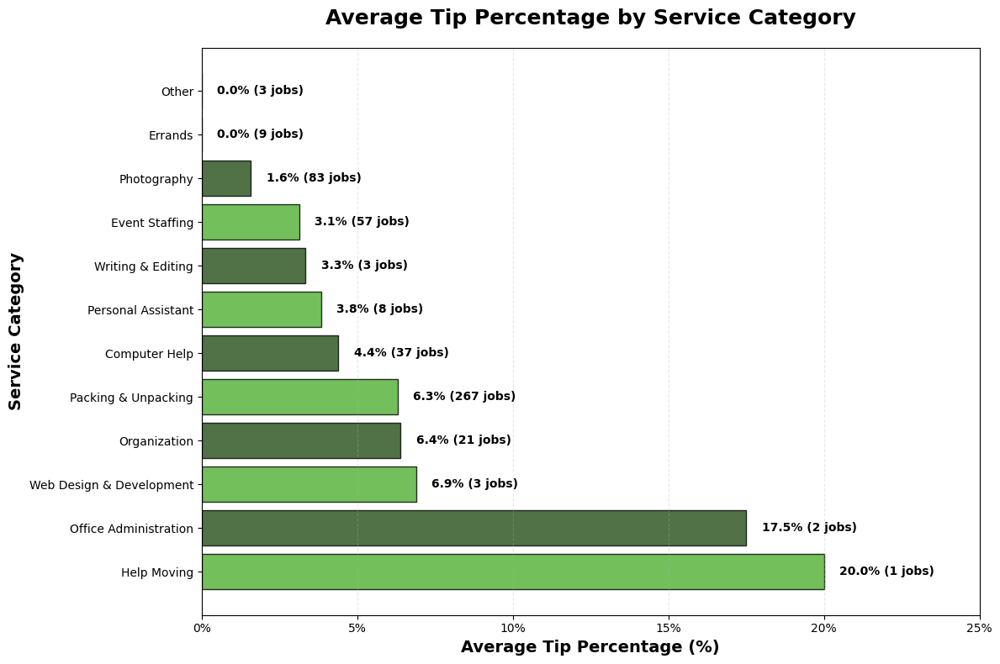

✓ Service Category Tip Percentage chart saved

SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE
Help Moving                     20.0%  (1 jobs)
Office Administration           17.5%  (2 jobs)
Web Design & Development         6.9%  (3 jobs)
Organization                     6.4%  (21 jobs)
Packing & Unpacking              6.3%  (267 jobs)
Computer Help                    4.4%  (37 jobs)
Personal Assistant               3.8%  (8 jobs)
Writing & Editing                3.3%  (3 jobs)
Event Staffing                   3.1%  (57 jobs)
Photography                      1.6%  (83 jobs)
Errands                          0.0%  (9 jobs)
Other                            0.0%  (3 jobs)


In [ ]:
# Calculate tip percentage for each job
df['Tip_Percentage'] = (df['Tip'] / df['Earnings']) * 100

# Clean data - only jobs with positive earnings
df_tip_clean = df[(df['Earnings'] > 0) & (df['Tip_Percentage'] >= 0) & (df['Tip_Percentage'] < np.inf)].copy()

# Group by service category
service_tip_metrics = df_tip_clean.groupby('Service_Category').agg({
    'Tip_Percentage': 'mean',
    'Earnings': 'count'  # Number of jobs
}).reset_index()

service_tip_metrics.columns = ['Service_Category', 'Avg_Tip_Percentage', 'Job_Count']

# Sort by tip percentage (highest to lowest)
service_tip_metrics = service_tip_metrics.sort_values('Avg_Tip_Percentage', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_metrics))]

bars = ax.barh(service_tip_metrics['Service_Category'], service_tip_metrics['Avg_Tip_Percentage'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, pct, count) in enumerate(zip(bars, service_tip_metrics['Avg_Tip_Percentage'], service_tip_metrics['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}% ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Average Tip Percentage by Service Category', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Tip Percentage (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_pct = service_tip_metrics['Avg_Tip_Percentage'].max()
ax.set_xlim(0, max_pct * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_percentage.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Percentage chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE")
print("="*80)
for idx, row in service_tip_metrics.iterrows():
    print(f"{row['Service_Category']:30} {row['Avg_Tip_Percentage']:5.1f}%  ({int(row['Job_Count'])} jobs)")

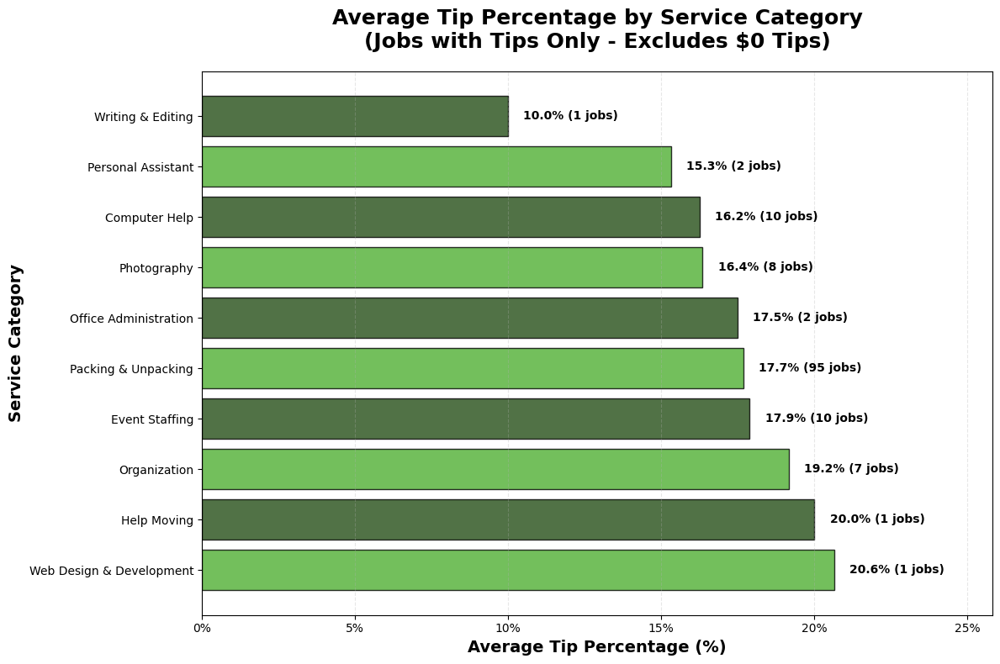

✓ Service Category Tip Percentage chart saved (Jobs with Tips Only)

SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE (JOBS WITH TIPS ONLY)
Web Design & Development        20.6%  (1/3 jobs = 33% tipped)
Help Moving                     20.0%  (1/2 jobs = 50% tipped)
Organization                    19.2%  (7/21 jobs = 33% tipped)
Event Staffing                  17.9%  (10/59 jobs = 17% tipped)
Packing & Unpacking             17.7%  (95/267 jobs = 36% tipped)
Office Administration           17.5%  (2/2 jobs = 100% tipped)
Photography                     16.4%  (8/83 jobs = 10% tipped)
Computer Help                   16.2%  (10/37 jobs = 27% tipped)
Personal Assistant              15.3%  (2/8 jobs = 25% tipped)
Writing & Editing               10.0%  (1/3 jobs = 33% tipped)


In [ ]:
# Calculate tip percentage for jobs that received tips ONLY
df['Tip_Percentage'] = (df['Tip'] / df['Earnings']) * 100

# Clean data - ONLY jobs with tips (Tip > 0)
df_tip_clean = df[(df['Earnings'] > 0) & (df['Tip'] > 0) & (df['Tip_Percentage'] < np.inf)].copy()

# Group by service category
service_tip_metrics = df_tip_clean.groupby('Service_Category').agg({
    'Tip_Percentage': 'mean',
    'Earnings': 'count'  # Number of jobs WITH tips
}).reset_index()

service_tip_metrics.columns = ['Service_Category', 'Avg_Tip_Percentage', 'Job_Count']

# Sort by tip percentage (highest to lowest)
service_tip_metrics = service_tip_metrics.sort_values('Avg_Tip_Percentage', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_metrics))]

bars = ax.barh(service_tip_metrics['Service_Category'], service_tip_metrics['Avg_Tip_Percentage'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, pct, count) in enumerate(zip(bars, service_tip_metrics['Avg_Tip_Percentage'], service_tip_metrics['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}% ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling - Title with subtitle
ax.set_title('Average Tip Percentage by Service Category\n(Jobs with Tips Only - Excludes $0 Tips)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Tip Percentage (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_pct = service_tip_metrics['Avg_Tip_Percentage'].max()
ax.set_xlim(0, max_pct * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_percentage.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Percentage chart saved (Jobs with Tips Only)")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE (JOBS WITH TIPS ONLY)")
print("="*80)
for idx, row in service_tip_metrics.iterrows():
    # Calculate how many jobs with tips vs total jobs
    total_jobs = len(df[df['Service_Category'] == row['Service_Category']])
    jobs_with_tips = int(row['Job_Count'])
    tip_frequency = (jobs_with_tips / total_jobs * 100) if total_jobs > 0 else 0
    
    print(f"{row['Service_Category']:30} {row['Avg_Tip_Percentage']:5.1f}%  ({jobs_with_tips}/{total_jobs} jobs = {tip_frequency:.0f}% tipped)")

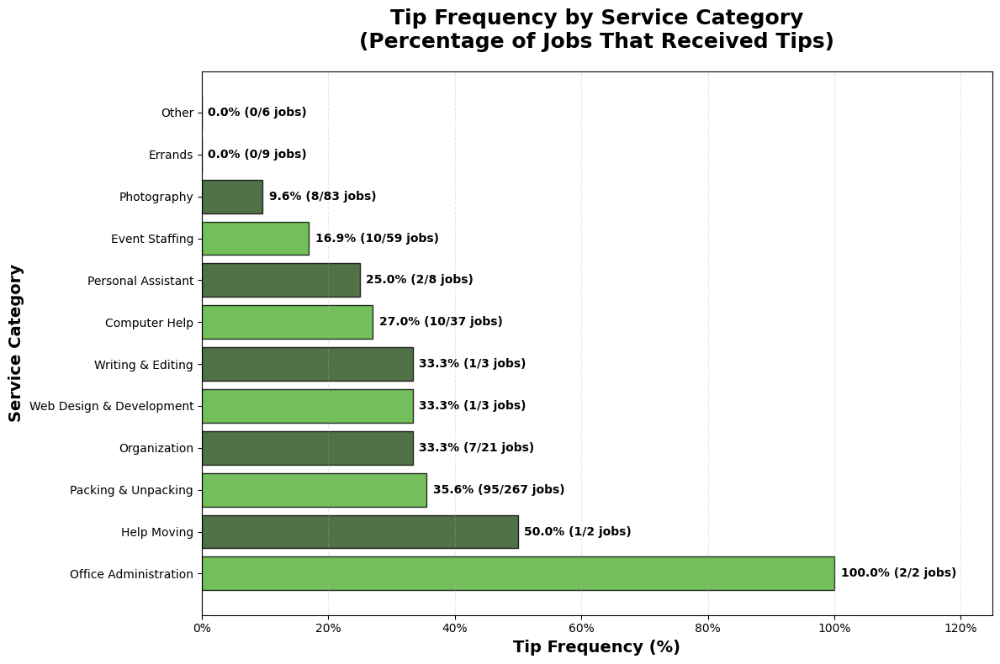

✓ Service Category Tip Frequency chart saved

SERVICE CATEGORY RANKINGS BY TIP FREQUENCY
Office Administration          100.0%  (2/2 jobs tipped)
Help Moving                     50.0%  (1/2 jobs tipped)
Packing & Unpacking             35.6%  (95/267 jobs tipped)
Organization                    33.3%  (7/21 jobs tipped)
Web Design & Development        33.3%  (1/3 jobs tipped)
Writing & Editing               33.3%  (1/3 jobs tipped)
Computer Help                   27.0%  (10/37 jobs tipped)
Personal Assistant              25.0%  (2/8 jobs tipped)
Event Staffing                  16.9%  (10/59 jobs tipped)
Photography                      9.6%  (8/83 jobs tipped)
Errands                          0.0%  (0/9 jobs tipped)
Other                            0.0%  (0/6 jobs tipped)


In [ ]:
# Calculate tip frequency by service category
service_tip_frequency = df.groupby('Service_Category').agg({
    'Tip': lambda x: (x > 0).sum(),  # Count of jobs WITH tips
    'Earnings': 'count'  # Total count of jobs
}).reset_index()

service_tip_frequency.columns = ['Service_Category', 'Jobs_With_Tips', 'Total_Jobs']

# Calculate tip frequency percentage
service_tip_frequency['Tip_Frequency_%'] = (service_tip_frequency['Jobs_With_Tips'] / service_tip_frequency['Total_Jobs']) * 100

# Sort by tip frequency (highest to lowest)
service_tip_frequency = service_tip_frequency.sort_values('Tip_Frequency_%', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_frequency))]

bars = ax.barh(service_tip_frequency['Service_Category'], service_tip_frequency['Tip_Frequency_%'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, freq, tipped, total) in enumerate(zip(bars, service_tip_frequency['Tip_Frequency_%'], 
                                                     service_tip_frequency['Jobs_With_Tips'], 
                                                     service_tip_frequency['Total_Jobs'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'{freq:.1f}% ({int(tipped)}/{int(total)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Tip Frequency by Service Category\n(Percentage of Jobs That Received Tips)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Tip Frequency (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_freq = service_tip_frequency['Tip_Frequency_%'].max()
ax.set_xlim(0, max_freq * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_frequency.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Frequency chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TIP FREQUENCY")
print("="*80)
for idx, row in service_tip_frequency.iterrows():
    print(f"{row['Service_Category']:30} {row['Tip_Frequency_%']:5.1f}%  ({int(row['Jobs_With_Tips'])}/{int(row['Total_Jobs'])} jobs tipped)")

Top 8 Highest Grossing Service Categories:
Packing & Unpacking            $47,209.75
Photography                    $15,953.25
Event Staffing                 $10,320.65
Computer Help                  $5,843.75
Organization                   $3,659.75
Personal Assistant             $994.75
Errands                        $528.00
Writing & Editing              $214.00




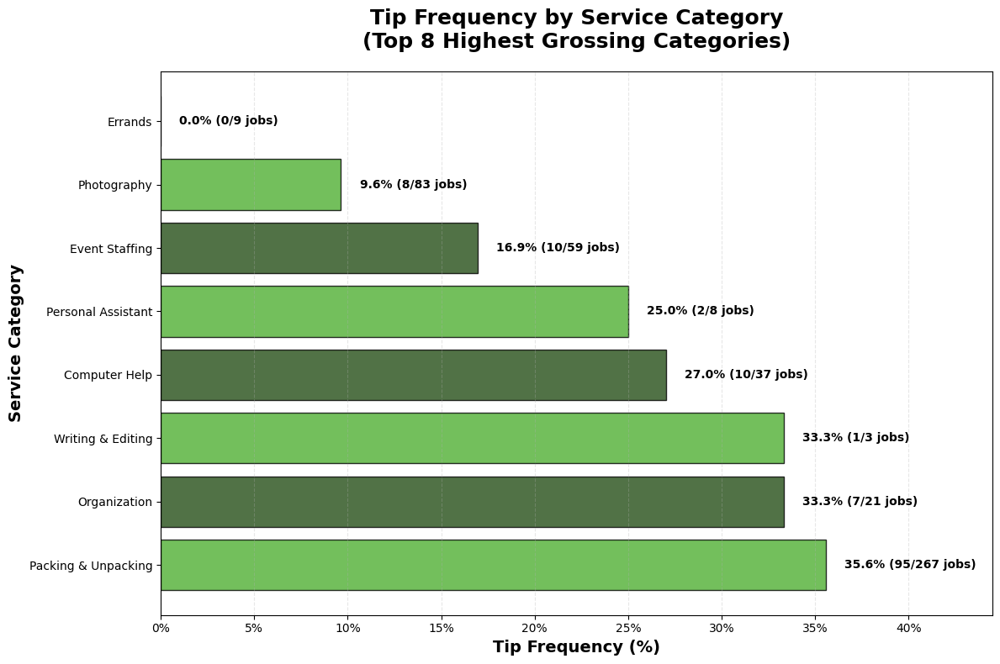

✓ Service Category Tip Frequency (Top 8) chart saved

TIP FREQUENCY FOR TOP 8 HIGHEST GROSSING CATEGORIES
Packing & Unpacking             35.6%  (95/267 jobs tipped)
Organization                    33.3%  (7/21 jobs tipped)
Writing & Editing               33.3%  (1/3 jobs tipped)
Computer Help                   27.0%  (10/37 jobs tipped)
Personal Assistant              25.0%  (2/8 jobs tipped)
Event Staffing                  16.9%  (10/59 jobs tipped)
Photography                      9.6%  (8/83 jobs tipped)
Errands                          0.0%  (0/9 jobs tipped)


In [ ]:
# Calculate total revenue by service category to find top earners
service_revenue = df.groupby('Service_Category').agg({
    'Earnings': 'sum'  # Total revenue
}).reset_index()

service_revenue.columns = ['Service_Category', 'Total_Revenue']
service_revenue = service_revenue.sort_values('Total_Revenue', ascending=False)

# Get top 8 categories by revenue
top_categories = service_revenue.head(8)['Service_Category'].tolist()

print("Top 8 Highest Grossing Service Categories:")
print("="*60)
for idx, row in service_revenue.head(8).iterrows():
    print(f"{row['Service_Category']:30} ${row['Total_Revenue']:,.2f}")
print("\n")

# Filter data to only top categories
df_top = df[df['Service_Category'].isin(top_categories)].copy()

# Calculate tip frequency for top categories only
service_tip_frequency_top = df_top.groupby('Service_Category').agg({
    'Tip': lambda x: (x > 0).sum(),  # Count of jobs WITH tips
    'Earnings': 'count'  # Total count of jobs
}).reset_index()

service_tip_frequency_top.columns = ['Service_Category', 'Jobs_With_Tips', 'Total_Jobs']

# Calculate tip frequency percentage
service_tip_frequency_top['Tip_Frequency_%'] = (service_tip_frequency_top['Jobs_With_Tips'] / service_tip_frequency_top['Total_Jobs']) * 100

# Sort by tip frequency (highest to lowest)
service_tip_frequency_top = service_tip_frequency_top.sort_values('Tip_Frequency_%', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_frequency_top))]

bars = ax.barh(service_tip_frequency_top['Service_Category'], service_tip_frequency_top['Tip_Frequency_%'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, freq, tipped, total) in enumerate(zip(bars, service_tip_frequency_top['Tip_Frequency_%'], 
                                                     service_tip_frequency_top['Jobs_With_Tips'], 
                                                     service_tip_frequency_top['Total_Jobs'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'{freq:.1f}% ({int(tipped)}/{int(total)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Tip Frequency by Service Category\n(Top 8 Highest Grossing Categories)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Tip Frequency (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_freq = service_tip_frequency_top['Tip_Frequency_%'].max()
ax.set_xlim(0, max_freq * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_frequency_top8.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Frequency (Top 8) chart saved")

# Print summary
print("\n" + "="*80)
print("TIP FREQUENCY FOR TOP 8 HIGHEST GROSSING CATEGORIES")
print("="*80)
for idx, row in service_tip_frequency_top.iterrows():
    print(f"{row['Service_Category']:30} {row['Tip_Frequency_%']:5.1f}%  ({int(row['Jobs_With_Tips'])}/{int(row['Total_Jobs'])} jobs tipped)")

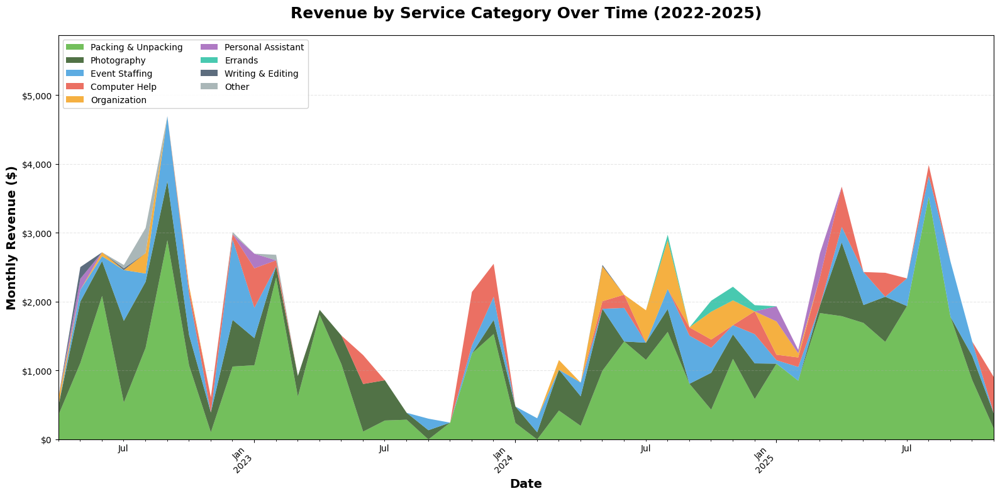

✓ Service Category Revenue Over Time chart saved

REVENUE BY SERVICE CATEGORY (TOP 8 + OTHER)
Packing & Unpacking            $ 47,209.75
Photography                    $ 15,953.25
Event Staffing                 $ 10,336.50
Computer Help                  $  5,843.75
Organization                   $  3,659.75
Personal Assistant             $    994.75
Errands                        $    528.00
Writing & Editing              $    214.00
Office Administration          $    195.50
Web Design & Development       $    179.00
Other                          $     80.20
Help Moving                    $     70.00


In [ ]:
# Prepare data - revenue by service category over time
df_revenue = df[df['Earnings'] > 0].copy()
df_revenue['Year_Month'] = df_revenue['Date'].dt.to_period('M')

# Calculate monthly revenue by service category
monthly_service_revenue = df_revenue.groupby(['Year_Month', 'Service_Category']).agg({
    'Earnings': 'sum'
}).reset_index()

# Pivot to get service categories as columns
revenue_pivot = monthly_service_revenue.pivot(index='Year_Month', columns='Service_Category', values='Earnings').fillna(0)

# Convert Year_Month back to datetime for plotting
revenue_pivot.index = revenue_pivot.index.to_timestamp()

# Get top 8 categories by total revenue (to avoid too many colors)
top_categories = df_revenue.groupby('Service_Category')['Earnings'].sum().nlargest(8).index.tolist()

# Filter to only top categories, group others as "Other"
revenue_pivot_top = revenue_pivot[top_categories].copy()
if len(revenue_pivot.columns) > 8:
    revenue_pivot_top['Other'] = revenue_pivot.drop(columns=top_categories, errors='ignore').sum(axis=1)

# Create stacked area chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define color palette - mix of greens, blues, and other colors
colors = ['#50AF33', '#264F18', '#3498db', '#e74c3c', '#f39c12', 
          '#9b59b6', '#1abc9c', '#34495e', '#95a5a6']

# Create stacked area plot (removed edgecolor parameter)
revenue_pivot_top.plot.area(ax=ax, color=colors[:len(revenue_pivot_top.columns)], 
                             alpha=0.8, linewidth=0)

# Styling
ax.set_title('Revenue by Service Category Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Monthly Revenue ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Position legend outside plot area
ax.legend(loc='upper left', fontsize=10, framealpha=0.9, ncol=2)

# Add 25% breathing room at top
max_revenue = revenue_pivot_top.sum(axis=1).max()
ax.set_ylim(0, max_revenue * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Revenue Over Time chart saved")

# Print summary
print("\n" + "="*80)
print("REVENUE BY SERVICE CATEGORY (TOP 8 + OTHER)")
print("="*80)
total_by_category = df_revenue.groupby('Service_Category')['Earnings'].sum().sort_values(ascending=False)
for category, revenue in total_by_category.items():
    print(f"{category:30} ${revenue:>10,.2f}")

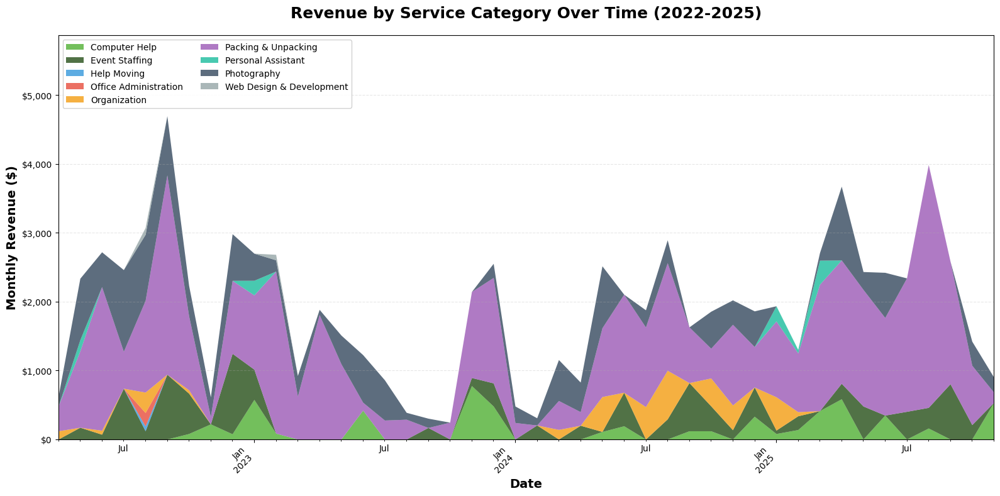

✓ Service Category Revenue Over Time chart saved

REVENUE BY SERVICE CATEGORY (EXCLUDING ERRANDS, WRITING & EDITING, OTHER)
Packing & Unpacking            $ 47,209.75
Photography                    $ 15,953.25
Event Staffing                 $ 10,336.50
Computer Help                  $  5,843.75
Organization                   $  3,659.75
Personal Assistant             $    994.75
Office Administration          $    195.50
Web Design & Development       $    179.00
Help Moving                    $     70.00


In [ ]:
# Prepare data - revenue by service category over time
df_revenue = df[df['Earnings'] > 0].copy()
df_revenue['Year_Month'] = df_revenue['Date'].dt.to_period('M')

# Filter out Errands, Writing & Editing, and Other
exclude_categories = ['Errands', 'Writing & Editing', 'Other']
df_revenue_filtered = df_revenue[~df_revenue['Service_Category'].isin(exclude_categories)].copy()

# Calculate monthly revenue by service category
monthly_service_revenue = df_revenue_filtered.groupby(['Year_Month', 'Service_Category']).agg({
    'Earnings': 'sum'
}).reset_index()

# Pivot to get service categories as columns
revenue_pivot = monthly_service_revenue.pivot(index='Year_Month', columns='Service_Category', values='Earnings').fillna(0)

# Convert Year_Month back to datetime for plotting
revenue_pivot.index = revenue_pivot.index.to_timestamp()

# Create stacked area chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define color palette - mix of greens, blues, and other colors
colors = ['#50AF33', '#264F18', '#3498db', '#e74c3c', '#f39c12', 
          '#9b59b6', '#1abc9c', '#34495e', '#95a5a6']

# Create stacked area plot
revenue_pivot.plot.area(ax=ax, color=colors[:len(revenue_pivot.columns)], 
                        alpha=0.8, linewidth=0)

# Styling
ax.set_title('Revenue by Service Category Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Monthly Revenue ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Position legend
ax.legend(loc='upper left', fontsize=10, framealpha=0.9, ncol=2)

# Add 25% breathing room at top
max_revenue = revenue_pivot.sum(axis=1).max()
ax.set_ylim(0, max_revenue * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Revenue Over Time chart saved")

# Print summary
print("\n" + "="*80)
print("REVENUE BY SERVICE CATEGORY (EXCLUDING ERRANDS, WRITING & EDITING, OTHER)")
print("="*80)
total_by_category = df_revenue_filtered.groupby('Service_Category')['Earnings'].sum().sort_values(ascending=False)
for category, revenue in total_by_category.items():
    print(f"{category:30} ${revenue:>10,.2f}")

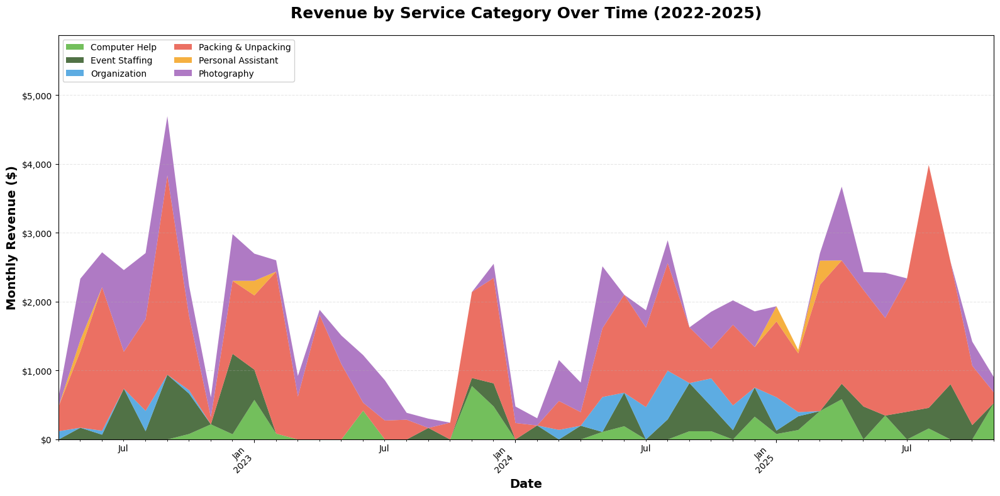

✓ Service Category Revenue Over Time chart saved

REVENUE BY SERVICE CATEGORY (TOP CATEGORIES ONLY)
Packing & Unpacking            $ 47,209.75
Photography                    $ 15,953.25
Event Staffing                 $ 10,336.50
Computer Help                  $  5,843.75
Organization                   $  3,659.75
Personal Assistant             $    994.75

Categories excluded: Errands, Writing & Editing, Other, Office Administration, Web Design & Development, Help Moving


In [ ]:
# Prepare data - revenue by service category over time
df_revenue = df[df['Earnings'] > 0].copy()
df_revenue['Year_Month'] = df_revenue['Date'].dt.to_period('M')

# Filter out specified categories
exclude_categories = ['Errands', 'Writing & Editing', 'Other', 'Office Administration', 
                      'Web Design & Development', 'Help Moving']
df_revenue_filtered = df_revenue[~df_revenue['Service_Category'].isin(exclude_categories)].copy()

# Calculate monthly revenue by service category
monthly_service_revenue = df_revenue_filtered.groupby(['Year_Month', 'Service_Category']).agg({
    'Earnings': 'sum'
}).reset_index()

# Pivot to get service categories as columns
revenue_pivot = monthly_service_revenue.pivot(index='Year_Month', columns='Service_Category', values='Earnings').fillna(0)

# Convert Year_Month back to datetime for plotting
revenue_pivot.index = revenue_pivot.index.to_timestamp()

# Create stacked area chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define color palette - mix of greens, blues, and other colors
colors = ['#50AF33', '#264F18', '#3498db', '#e74c3c', '#f39c12', 
          '#9b59b6', '#1abc9c', '#34495e', '#95a5a6']

# Create stacked area plot
revenue_pivot.plot.area(ax=ax, color=colors[:len(revenue_pivot.columns)], 
                        alpha=0.8, linewidth=0)

# Styling
ax.set_title('Revenue by Service Category Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Monthly Revenue ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Position legend
ax.legend(loc='upper left', fontsize=10, framealpha=0.9, ncol=2)

# Add 25% breathing room at top
max_revenue = revenue_pivot.sum(axis=1).max()
ax.set_ylim(0, max_revenue * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Revenue Over Time chart saved")

# Print summary
print("\n" + "="*80)
print("REVENUE BY SERVICE CATEGORY (TOP CATEGORIES ONLY)")
print("="*80)
total_by_category = df_revenue_filtered.groupby('Service_Category')['Earnings'].sum().sort_values(ascending=False)
for category, revenue in total_by_category.items():
    print(f"{category:30} ${revenue:>10,.2f}")
print(f"\nCategories excluded: {', '.join(exclude_categories)}")

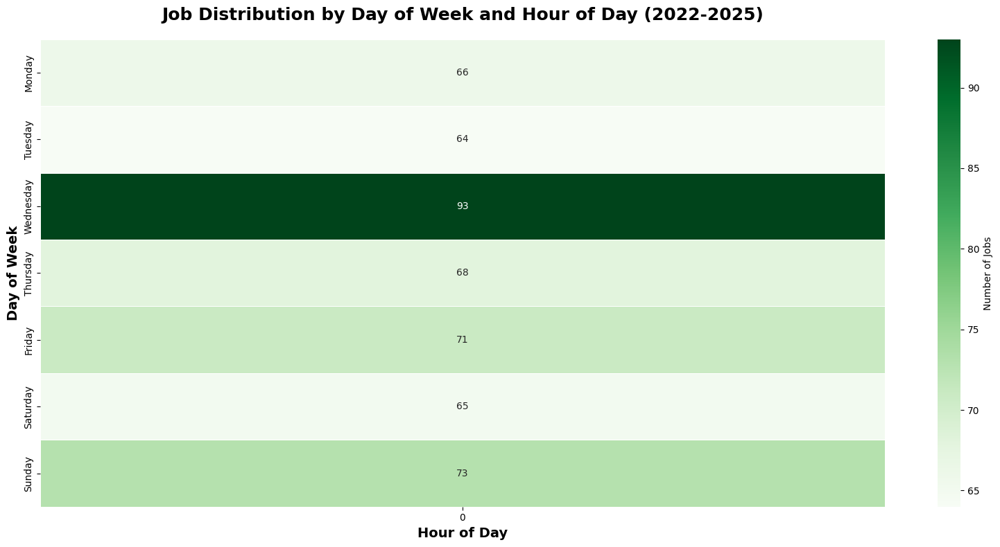

✓ Jobs Heatmap (Day/Hour) saved

BUSIEST TIMES

Top 5 busiest day/hour combinations:
Wednesday  at 00:00 - 93 jobs
Sunday     at 00:00 - 73 jobs
Friday     at 00:00 - 71 jobs
Thursday   at 00:00 - 68 jobs
Monday     at 00:00 - 66 jobs


In [ ]:
# Task 2.4: Time-Based Analysis - Heatmap

# Extract day of week and hour from Date
df['Day_of_Week'] = df['Date'].dt.day_name()
df['Hour'] = df['Date'].dt.hour

# Create pivot table for heatmap
heatmap_data = df.groupby(['Day_of_Week', 'Hour']).size().reset_index(name='Job_Count')

# Pivot for heatmap format
heatmap_pivot = heatmap_data.pivot(index='Day_of_Week', columns='Hour', values='Job_Count').fillna(0)

# Reorder days of week properly (Monday first)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_pivot = heatmap_pivot.reindex(day_order)

# Create heatmap
fig, ax = plt.subplots(figsize=(16, 8))

# Use a green color scheme (TaskRabbit themed)
import seaborn as sns
sns.heatmap(heatmap_pivot, cmap='Greens', annot=True, fmt='.0f', 
            linewidths=0.5, cbar_kws={'label': 'Number of Jobs'},
            ax=ax)

# Styling
ax.set_title('Job Distribution by Day of Week and Hour of Day (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Hour of Day', fontsize=14, fontweight='bold')
ax.set_ylabel('Day of Week', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../visualizations/jobs_heatmap_day_hour.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Jobs Heatmap (Day/Hour) saved")

# Print summary stats
print("\n" + "="*80)
print("BUSIEST TIMES")
print("="*80)
print("\nTop 5 busiest day/hour combinations:")
top_times = heatmap_data.nlargest(5, 'Job_Count')
for idx, row in top_times.iterrows():
    print(f"{row['Day_of_Week']:10} at {int(row['Hour']):02d}:00 - {int(row['Job_Count'])} jobs")

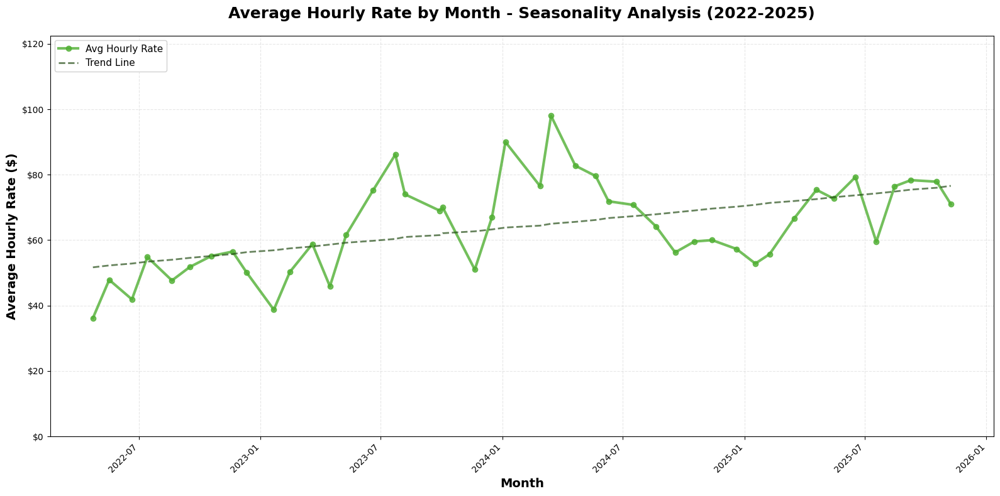

✓ Hourly Rate Seasonality chart saved

SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH

Average hourly rate by calendar month (all years combined):
January      $ 48.84/hr
February     $ 53.77/hr
March        $ 71.78/hr
April        $ 59.56/hr
May          $ 64.72/hr
June         $ 63.22/hr
July         $ 64.19/hr
August       $ 62.67/hr
September    $ 59.13/hr
October      $ 61.63/hr
November     $ 59.27/hr
December     $ 56.00/hr

Best month: March ($71.78/hr)
Worst month: January ($48.84/hr)


In [ ]:
# Task 2.4: Time-Based Analysis - Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')
df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Calculate average hourly rate by month
monthly_rates = df_clean.groupby('Year_Month').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

monthly_rates.columns = ['Year_Month', 'Avg_Hourly_Rate', 'Date']

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Plot line with markers
ax.plot(monthly_rates['Date'], monthly_rates['Avg_Hourly_Rate'], 
        color='#50AF33', linewidth=3, marker='o', markersize=6, 
        label='Avg Hourly Rate', alpha=0.8)

# Add trend line
x_numeric = np.arange(len(monthly_rates))
z = np.polyfit(x_numeric, monthly_rates['Avg_Hourly_Rate'], 1)
p = np.poly1d(z)
ax.plot(monthly_rates['Date'], p(x_numeric), 
        color='#264F18', linewidth=2, linestyle='--', 
        label='Trend Line', alpha=0.7)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality Analysis (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Month', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = monthly_rates['Avg_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Hourly Rate Seasonality chart saved")

# Analyze seasonality by month (across all years)
print("\n" + "="*80)
print("SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH")
print("="*80)
monthly_seasonality = df_clean.groupby('Month_Name').agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Num': 'first'
}).reset_index()

monthly_seasonality = monthly_seasonality.sort_values('Month_Num')

print("\nAverage hourly rate by calendar month (all years combined):")
for idx, row in monthly_seasonality.iterrows():
    print(f"{row['Month_Name']:12} ${row['Gross_Hourly_Rate']:6.2f}/hr")

# Identify highest and lowest months
best_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmax()]
worst_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmin()]

print(f"\nBest month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
print(f"Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")

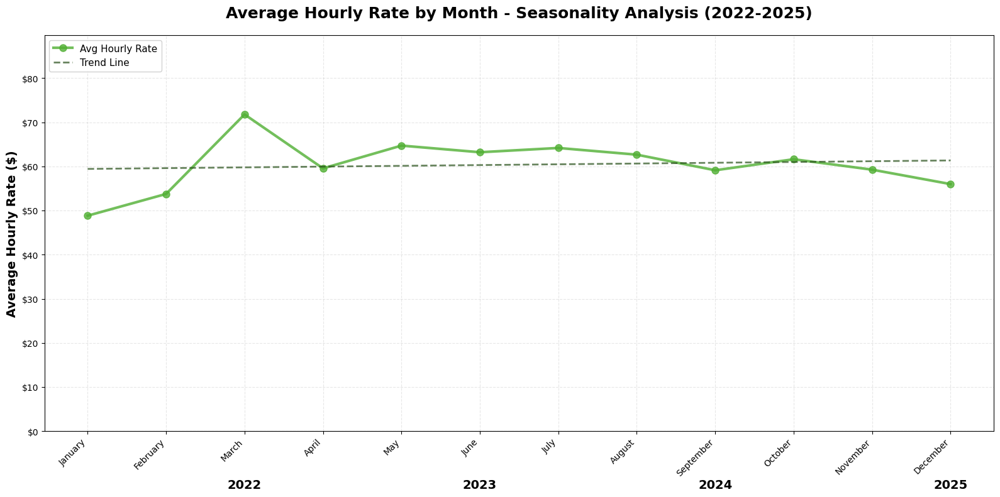

✓ Hourly Rate Seasonality chart saved

SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH

Average hourly rate by calendar month (2022-2025 combined):
January      $ 48.84/hr
February     $ 53.77/hr
March        $ 71.78/hr
April        $ 59.56/hr
May          $ 64.72/hr
June         $ 63.22/hr
July         $ 64.19/hr
August       $ 62.67/hr
September    $ 59.13/hr
October      $ 61.63/hr
November     $ 59.27/hr
December     $ 56.00/hr

Best month: March ($71.78/hr)
Worst month: January ($48.84/hr)


In [ ]:
# Task 2.4: Time-Based Analysis - Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Calculate average hourly rate by month (aggregated across all years)
monthly_seasonality = df_clean.groupby('Month_Num').agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

monthly_seasonality = monthly_seasonality.sort_values('Month_Num')

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Plot line with markers
ax.plot(monthly_seasonality['Month_Num'], monthly_seasonality['Gross_Hourly_Rate'], 
        color='#50AF33', linewidth=3, marker='o', markersize=8, 
        label='Avg Hourly Rate', alpha=0.8)

# Add trend line
x_numeric = np.arange(len(monthly_seasonality))
z = np.polyfit(monthly_seasonality['Month_Num'], monthly_seasonality['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)
ax.plot(monthly_seasonality['Month_Num'], p(monthly_seasonality['Month_Num']), 
        color='#264F18', linewidth=2, linestyle='--', 
        label='Trend Line', alpha=0.7)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality Analysis (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = monthly_seasonality['Month_Name'].tolist()
ax.set_xticks(monthly_seasonality['Month_Num'])
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add year labels below, centered
# Calculate center position for each year (between months 6 and 7)
years = sorted(df_clean['Year'].unique())
for i, year in enumerate(years):
    # Position years at quarters: 1.5, 4.5, 7.5, 10.5
    year_position = 3 * i + 1.5  # Spread across the 12 months
    if year_position <= 12:
        ax.text(year_position + 1.5, -0.12, str(year), 
                transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = monthly_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Hourly Rate Seasonality chart saved")

# Analyze seasonality
print("\n" + "="*80)
print("SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH")
print("="*80)

print("\nAverage hourly rate by calendar month (2022-2025 combined):")
for idx, row in monthly_seasonality.iterrows():
    print(f"{row['Month_Name']:12} ${row['Gross_Hourly_Rate']:6.2f}/hr")

# Identify highest and lowest months
best_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmax()]
worst_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmin()]

print(f"\nBest month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
print(f"Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")

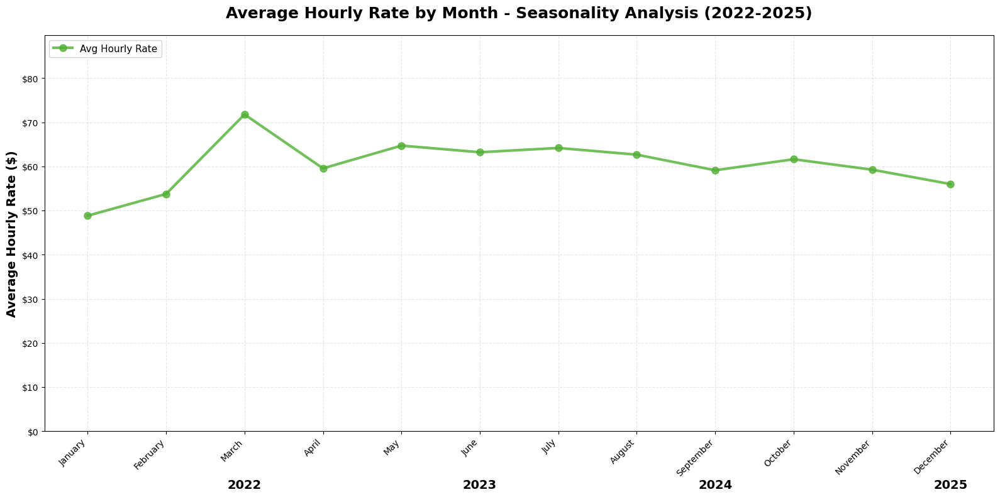

✓ Hourly Rate Seasonality chart saved

SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH

Average hourly rate by calendar month (2022-2025 combined):
January      $ 48.84/hr
February     $ 53.77/hr
March        $ 71.78/hr
April        $ 59.56/hr
May          $ 64.72/hr
June         $ 63.22/hr
July         $ 64.19/hr
August       $ 62.67/hr
September    $ 59.13/hr
October      $ 61.63/hr
November     $ 59.27/hr
December     $ 56.00/hr

Best month: March ($71.78/hr)
Worst month: January ($48.84/hr)


In [ ]:
# Task 2.4: Time-Based Analysis - Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Calculate average hourly rate by month (aggregated across all years)
monthly_seasonality = df_clean.groupby('Month_Num').agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

monthly_seasonality = monthly_seasonality.sort_values('Month_Num')

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Plot line with markers
ax.plot(monthly_seasonality['Month_Num'], monthly_seasonality['Gross_Hourly_Rate'], 
        color='#50AF33', linewidth=3, marker='o', markersize=8, 
        label='Avg Hourly Rate', alpha=0.8)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality Analysis (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = monthly_seasonality['Month_Name'].tolist()
ax.set_xticks(monthly_seasonality['Month_Num'])
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add year labels below, centered
# Calculate center position for each year (between months 6 and 7)
years = sorted(df_clean['Year'].unique())
for i, year in enumerate(years):
    # Position years at quarters: 1.5, 4.5, 7.5, 10.5
    year_position = 3 * i + 1.5  # Spread across the 12 months
    if year_position <= 12:
        ax.text(year_position + 1.5, -0.12, str(year), 
                transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = monthly_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Hourly Rate Seasonality chart saved")

# Analyze seasonality
print("\n" + "="*80)
print("SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH")
print("="*80)

print("\nAverage hourly rate by calendar month (2022-2025 combined):")
for idx, row in monthly_seasonality.iterrows():
    print(f"{row['Month_Name']:12} ${row['Gross_Hourly_Rate']:6.2f}/hr")

# Identify highest and lowest months
best_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmax()]
worst_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmin()]

print(f"\nBest month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
print(f"Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")

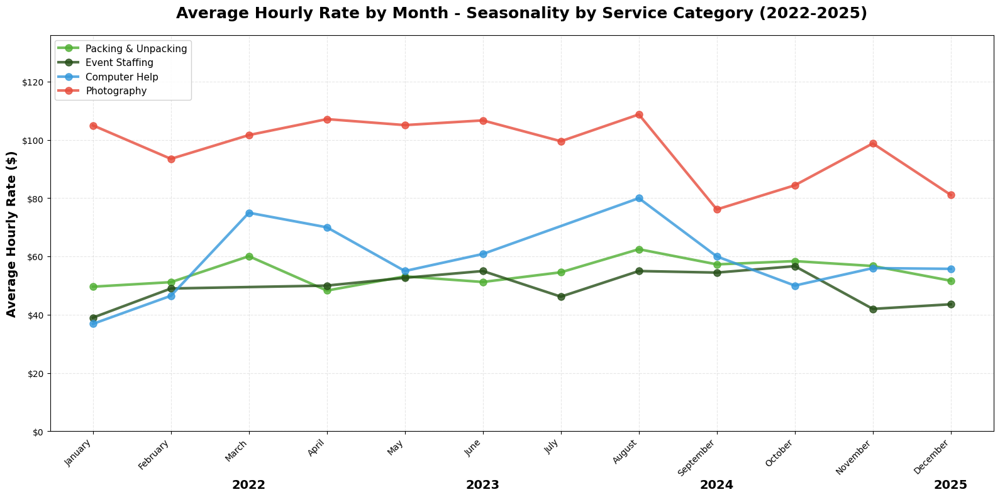

✓ Multi-Category Seasonality chart saved

SEASONALITY ANALYSIS BY SERVICE CATEGORY

Packing & Unpacking:
  Best month: August ($62.49/hr)
  Worst month: April ($48.29/hr)
  Average: $54.56/hr

Event Staffing:
  Best month: October ($56.67/hr)
  Worst month: January ($39.00/hr)
  Average: $49.42/hr

Computer Help:
  Best month: August ($80.00/hr)
  Worst month: January ($36.86/hr)
  Average: $58.72/hr

Photography:
  Best month: August ($108.75/hr)
  Worst month: September ($76.14/hr)
  Average: $97.32/hr


In [ ]:
# Task 2.4: Time-Based Analysis - Multi-Category Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Filter to only the four categories
categories = ['Packing & Unpacking', 'Event Staffing', 'Computer Help', 'Photography']
df_four_cats = df_clean[df_clean['Service_Category'].isin(categories)].copy()

# Calculate average hourly rate by month and category
category_seasonality = df_four_cats.groupby(['Month_Num', 'Service_Category']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define colors for each category
category_colors = {
    'Packing & Unpacking': '#50AF33',      # TaskRabbit light green
    'Event Staffing': '#264F18',            # TaskRabbit dark green
    'Computer Help': '#3498db',             # Blue
    'Photography': '#e74c3c'                # Red
}

# Plot line for each category
for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    ax.plot(cat_data['Month_Num'], cat_data['Gross_Hourly_Rate'], 
            color=category_colors[category], linewidth=3, marker='o', markersize=8, 
            label=category, alpha=0.8)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality by Service Category (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add year labels below, centered
years = sorted(df_clean['Year'].unique())
for i, year in enumerate(years):
    year_position = 3 * i + 1.5
    if year_position <= 12:
        ax.text(year_position + 1.5, -0.12, str(year), 
                transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = category_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Multi-Category Seasonality chart saved")

# Print summary for each category
print("\n" + "="*80)
print("SEASONALITY ANALYSIS BY SERVICE CATEGORY")
print("="*80)

for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    print(f"\n{category}:")
    
    if len(cat_data) > 0:
        best_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmax()]
        worst_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmin()]
        
        print(f"  Best month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Average: ${cat_data['Gross_Hourly_Rate'].mean():.2f}/hr")
    else:
        print("  No data available")

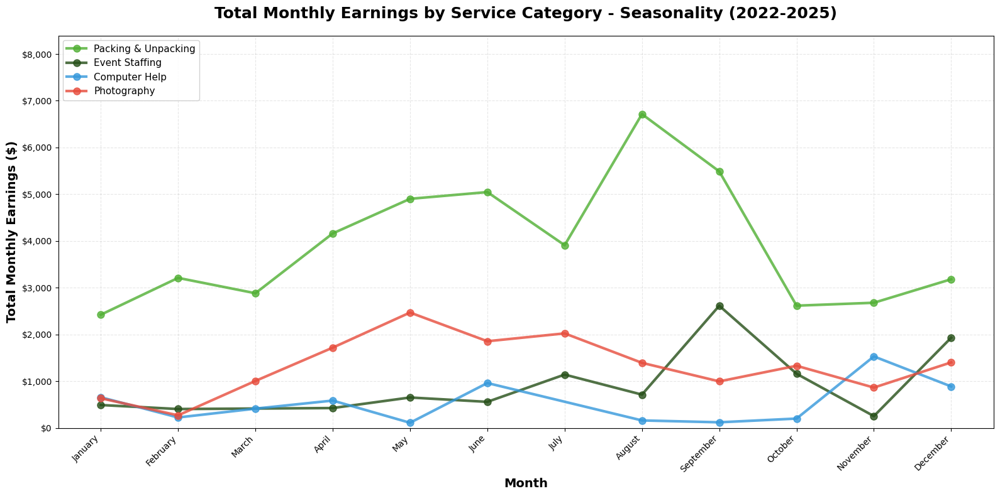

✓ Multi-Category Monthly Earnings Seasonality chart saved

MONTHLY EARNINGS SEASONALITY BY SERVICE CATEGORY

Packing & Unpacking:
  Best month: August ($6,714.50)
  Worst month: January ($2,422.00)
  Total earnings: $47,209.75

Event Staffing:
  Best month: September ($2,614.25)
  Worst month: November ($252.00)
  Total earnings: $10,336.50

Computer Help:
  Best month: November ($1,529.50)
  Worst month: May ($110.00)
  Total earnings: $5,843.75

Photography:
  Best month: May ($2,468.50)
  Worst month: February ($269.00)
  Total earnings: $15,953.25


In [ ]:
# Task 2.4: Time-Based Analysis - Multi-Category Monthly Earnings

# Clean data
df_clean = df[df['Earnings'] > 0].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Filter to only the four categories
categories = ['Packing & Unpacking', 'Event Staffing', 'Computer Help', 'Photography']
df_four_cats = df_clean[df_clean['Service_Category'].isin(categories)].copy()

# Calculate total earnings by month and category
category_monthly_earnings = df_four_cats.groupby(['Month_Num', 'Service_Category']).agg({
    'Earnings': 'sum',
    'Month_Name': 'first'
}).reset_index()

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define colors for each category
category_colors = {
    'Packing & Unpacking': '#50AF33',      # TaskRabbit light green
    'Event Staffing': '#264F18',            # TaskRabbit dark green
    'Computer Help': '#3498db',             # Blue
    'Photography': '#e74c3c'                # Red
}

# Plot line for each category
for category in categories:
    cat_data = category_monthly_earnings[category_monthly_earnings['Service_Category'] == category].sort_values('Month_Num')
    ax.plot(cat_data['Month_Num'], cat_data['Earnings'], 
            color=category_colors[category], linewidth=3, marker='o', markersize=8, 
            label=category, alpha=0.8)

# Styling
ax.set_title('Total Monthly Earnings by Service Category - Seasonality (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Month', fontsize=14, fontweight='bold')
ax.set_ylabel('Total Monthly Earnings ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_earnings = category_monthly_earnings['Earnings'].max()
ax.set_ylim(0, max_earnings * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/monthly_earnings_seasonality_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Multi-Category Monthly Earnings Seasonality chart saved")

# Print summary for each category
print("\n" + "="*80)
print("MONTHLY EARNINGS SEASONALITY BY SERVICE CATEGORY")
print("="*80)

for category in categories:
    cat_data = category_monthly_earnings[category_monthly_earnings['Service_Category'] == category].sort_values('Month_Num')
    print(f"\n{category}:")
    
    if len(cat_data) > 0:
        best_month = cat_data.loc[cat_data['Earnings'].idxmax()]
        worst_month = cat_data.loc[cat_data['Earnings'].idxmin()]
        
        print(f"  Best month: {best_month['Month_Name']} (${best_month['Earnings']:,.2f})")
        print(f"  Worst month: {worst_month['Month_Name']} (${worst_month['Earnings']:,.2f})")
        print(f"  Total earnings: ${cat_data['Earnings'].sum():,.2f}")
    else:
        print("  No data available")

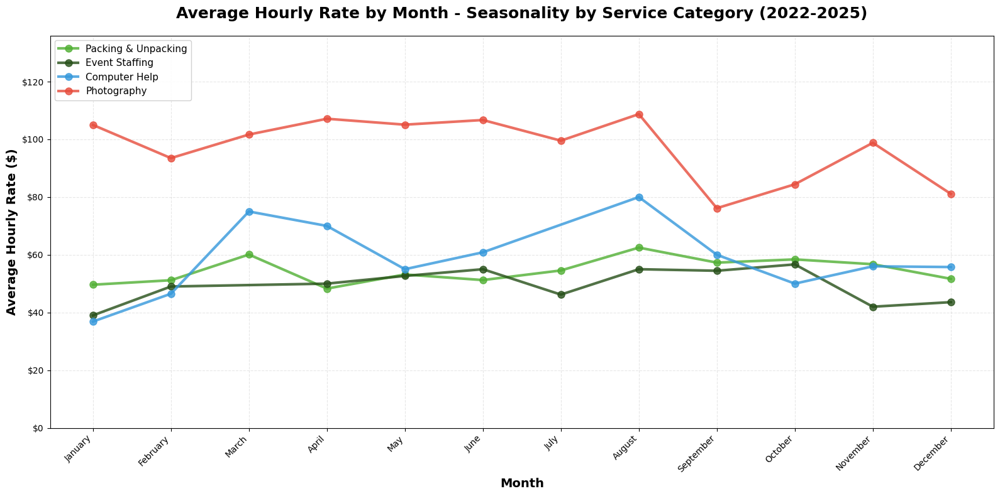

✓ Multi-Category Seasonality chart saved

SEASONALITY ANALYSIS BY SERVICE CATEGORY

Packing & Unpacking:
  Best month: August ($62.49/hr)
  Worst month: April ($48.29/hr)
  Average: $54.56/hr

Event Staffing:
  Best month: October ($56.67/hr)
  Worst month: January ($39.00/hr)
  Average: $49.42/hr

Computer Help:
  Best month: August ($80.00/hr)
  Worst month: January ($36.86/hr)
  Average: $58.72/hr

Photography:
  Best month: August ($108.75/hr)
  Worst month: September ($76.14/hr)
  Average: $97.32/hr


In [ ]:
# Task 2.4: Time-Based Analysis - Multi-Category Seasonality Chart (Updated)

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Filter to only the four categories
categories = ['Packing & Unpacking', 'Event Staffing', 'Computer Help', 'Photography']
df_four_cats = df_clean[df_clean['Service_Category'].isin(categories)].copy()

# Calculate average hourly rate by month and category
category_seasonality = df_four_cats.groupby(['Month_Num', 'Service_Category']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define colors for each category
category_colors = {
    'Packing & Unpacking': '#50AF33',      # TaskRabbit light green
    'Event Staffing': '#264F18',            # TaskRabbit dark green
    'Computer Help': '#3498db',             # Blue
    'Photography': '#e74c3c'                # Red
}

# Plot line for each category
for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    ax.plot(cat_data['Month_Num'], cat_data['Gross_Hourly_Rate'], 
            color=category_colors[category], linewidth=3, marker='o', markersize=8, 
            label=category, alpha=0.8)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality by Service Category (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Month', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = category_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Multi-Category Seasonality chart saved")

# Print summary for each category
print("\n" + "="*80)
print("SEASONALITY ANALYSIS BY SERVICE CATEGORY")
print("="*80)

for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    print(f"\n{category}:")
    
    if len(cat_data) > 0:
        best_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmax()]
        worst_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmin()]
        
        print(f"  Best month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Average: ${cat_data['Gross_Hourly_Rate'].mean():.2f}/hr")
    else:
        print("  No data available")

In [ ]:
import os

# List all saved visualizations
viz_folder = '/mnt/user-data/outputs/'
if os.path.exists(viz_folder):
    files = sorted([f for f in os.listdir(viz_folder) if f.endswith('.png')])
    print("✓ SAVED VISUALIZATIONS:")
    print("="*60)
    for i, file in enumerate(files, 1):
        print(f"{i:2d}. {file}")
    print(f"\nTotal: {len(files)} charts saved")
else:
    print("Visualizations folder not found")

Visualizations folder not found


In [ ]:
import os

# Check the visualizations folder (relative path)
viz_folder = '../visualizations/'

if os.path.exists(viz_folder):
    files = sorted([f for f in os.listdir(viz_folder) if f.endswith('.png')])
    print("✓ SAVED VISUALIZATIONS:")
    print("="*60)
    for i, file in enumerate(files, 1):
        print(f"{i:2d}. {file}")
    print(f"\nTotal: {len(files)} charts saved")
    print(f"\nLocation: {os.path.abspath(viz_folder)}")
else:
    print("Visualizations folder not found")
    
# Also check current directory
print("\n" + "="*60)
print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
for item in os.listdir('.'):
    print(f"  {item}")

✓ SAVED VISUALIZATIONS:
 1. before_after_comparison.png
 2. earnings_per_job_comparison.png
 3. hourly_rate_2022.png
 4. hourly_rate_2023.png
 5. hourly_rate_2024.png
 6. hourly_rate_2025.png
 7. hourly_rate_NO_trendline.png
 8. hourly_rate_WITH_trendline.png
 9. hourly_rate_seasonality.png
10. hourly_rate_seasonality_by_category.png
11. hourly_rate_trend_professional.png
12. jobs_heatmap_day_hour.png
13. monthly_earnings_seasonality_by_category.png
14. service_category_hourly_rate.png
15. service_category_revenue_over_time.png
16. service_category_tip_frequency.png
17. service_category_tip_frequency_top8.png
18. service_category_tip_percentage.png
19. service_category_total_hourly_earnings.png
20. strategic_shift_quarterly.png
21. tip_amount_per_job_2022.png
22. tip_amount_per_job_2023.png
23. tip_amount_per_job_2024.png
24. tip_amount_per_job_2025.png
25. tip_amount_per_job_NO_trendline.png
26. tip_amount_per_job_WITH_trendline.png
27. tip_rate_NO_trendline.png
28. tip_rate_WITH_tren

In [ ]:
import os

print("="*80)
print("YOUR SAVED FILES - VERIFICATION")
print("="*80)

# Check visualizations folder
viz_folder = '../visualizations/'
if os.path.exists(viz_folder):
    files = sorted([f for f in os.listdir(viz_folder) if f.endswith('.png')])
    print(f"\n✓ VISUALIZATIONS FOLDER: {os.path.abspath(viz_folder)}")
    print(f"Total charts saved: {len(files)}\n")
    for i, file in enumerate(files, 1):
        print(f"  {i:2d}. {file}")
else:
    print("\n✗ Visualizations folder not found")

# Check if data file exists
data_file = '../data/TaskRabbit.csv'
if os.path.exists(data_file):
    print(f"\n✓ DATA FILE: {os.path.abspath(data_file)}")
else:
    print("\n✗ Data file not found")

print("\n" + "="*80)
print("WHAT TO DO BEFORE CLOSING:")
print("="*80)
print("1. Save this notebook (Ctrl+S / Cmd+S)")
print("2. Download the '../visualizations/' folder")
print("3. Download this notebook file (.ipynb)")
print("4. Keep your original CSV data file")
print("="*80)
print("\nIf you're in GitHub, commit and push your changes!")
print("="*80)

YOUR SAVED FILES - VERIFICATION

✓ VISUALIZATIONS FOLDER: /workspaces/taskrabbit-analysis/visualizations
Total charts saved: 32

   1. before_after_comparison.png
   2. earnings_per_job_comparison.png
   3. hourly_rate_2022.png
   4. hourly_rate_2023.png
   5. hourly_rate_2024.png
   6. hourly_rate_2025.png
   7. hourly_rate_NO_trendline.png
   8. hourly_rate_WITH_trendline.png
   9. hourly_rate_seasonality.png
  10. hourly_rate_seasonality_by_category.png
  11. hourly_rate_trend_professional.png
  12. jobs_heatmap_day_hour.png
  13. monthly_earnings_seasonality_by_category.png
  14. service_category_hourly_rate.png
  15. service_category_revenue_over_time.png
  16. service_category_tip_frequency.png
  17. service_category_tip_frequency_top8.png
  18. service_category_tip_percentage.png
  19. service_category_total_hourly_earnings.png
  20. strategic_shift_quarterly.png
  21. tip_amount_per_job_2022.png
  22. tip_amount_per_job_2023.png
  23. tip_amount_per_job_2024.png
  24. tip_amoun